# Etapa 1: Análise exploratória dos dados e diagnóstico

**Disciplina:** Inteligência Artificial — Prof. Cristiane Neri Nobre
**Entrega:** 01/11/2026 | **Valor:** 2,00 pontos

Reaproveitamento do código anterior dos membros 1–4, adaptado a `treino.csv` e ao alvo binário.
As análises que estavam pendentes continuam como tarefas; não há treino de modelos nesta etapa.

| Responsável | Tarefa nesta adaptação |
|---|---|
| Membro 1 | Revisar carga, tipos e ausências da nova base; reescrever a síntese com os resultados atuais. |
| Membro 2 | Revisar distribuição normal/anomaly e justificar F1-macro, sem agrupamento em famílias. |
| Membro 3 | Revisar cardinalidade, espaços/caixa e ausências; atualizar a justificativa da codificação. |
| Membro 4 | Revisar duplicatas, conflitos, constantes e novos atributos derivados; propor comparações. |
| Membro 5 | Implementar associação de cada atributo com a classe, investigar vazamento e consolidar o diagnóstico. |

Substituir Membro 1–5 pelos nomes da equipe. Cada responsável deve executar e interpretar sua seção.
As conclusões da base antiga foram retiradas; os espaços de síntese devem ser preenchidos pela equipe.

### Como executar este notebook

**Dependências.** `pip install -r requirements.txt` na raiz do projeto. Este notebook usa apenas
`pandas`, `numpy`, `matplotlib`, `seaborn` e `IPython.display`; as medidas de associação e as
métricas da Seção 5 são calculadas com `numpy`/`pandas` puros, sem `scipy` ou `scikit-learn`,
para que a Etapa 1 rode com o mínimo de dependências. Validado em Python 3.14 com pandas 3.1.

**Execução.** Abrir a partir da raiz do projeto ou da pasta `notebooks/` (a célula de importação
resolve as duas situações) e executar **Kernel > Restart & Run All**. Todas as células dependem
apenas de células anteriores, na ordem em que aparecem: não há estado oculto, variáveis definidas
fora do notebook nem resultados colados manualmente. Tempo total de execução em torno de 1 minuto.

**Dados.** A única leitura de dados é `data/treino.csv`. O notebook **não** abre
`data/teste_sem_rotulo.csv` em nenhum momento — isso é verificado automaticamente na Seção 5.9,
que varre o código-fonte deste próprio arquivo. Nenhuma célula escreve em `data/`.

In [1]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

project_root = Path.cwd().resolve()
if not (project_root / "data" / "treino.csv").exists():
    project_root = project_root.parent
if not (project_root / "data" / "treino.csv").exists():
    raise FileNotFoundError("Execute na raiz do projeto ou em notebooks/.")

# Leitura direta: os módulos src ainda se referem à base antiga.
CLASSES = ["normal", "anomaly"]
sns.set_theme(style="whitegrid")

## Membro 1 — Caracterização geral da base e análise dos tipos de dados

Usamos exclusivamente `treino.csv`, com cabeçalho e alvo `class`.
Preservamos todas as colunas para diagnóstico, inclusive os sinais adicionados que o Membro 5 investigará.
Não consultamos o teste e não modificamos os arquivos oficiais. Tratamentos serão comparados na etapa 2.

### 1.1 Carregamento do conjunto de treino bruto

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df_train = pd.read_csv(project_root / "data" / "treino.csv")
df_train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,src_bytes_kb,dst_bytes_kb,total_bytes,same_srv_pct,protocolo_cod,score_ids_legado,tipo_alerta_soc,tempo_resposta_analista_min,class
0,0,tcp,http,SF,219.0000,3729,0,0,0,0,0,1.0000,0.0000,0.0000,0.0000,0,NaN,0,0.0000,0,0,0,3.0000,4.0000,NaN,0.0000,0.0000,0.0000,1.0000,0.0000,0.5000,255.0000,255.0000,1.0000,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2139,3.6416,"3,948.0000",100.0000,0,0.1760,OK,NaN,normal
1,0,tcp,finger,SF,NaN,443,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,223.0000,NaN,0.0400,0.0300,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.4326,NaN,100.0000,0,0.0670,OK,NaN,anomaly
2,0,tcp,http,SF,162.0000,29122,0,0,0,0,0,1.0000,0.0000,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,255.0000,255.0000,1.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,0.1582,28.4395,"29,284.0000",100.0000,0,0.2450,OK,NaN,normal
3,0,tcp,smtp,SF,942.0000,332,0,0,0,0,0,1.0000,0.0000,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,62.0000,173.0000,0.4200,0.0800,0.0200,0.0200,0.0000,0.0000,0.0000,0.0000,0.9199,0.3242,"1,274.0000",100.0000,0,0.2390,OK,NaN,normal
4,0,tcp,http,SF,232.0000,479,0,0,0,0,0,1.0000,NaN,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,8.0000,9.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.2200,255.0000,255.0000,1.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,0.2266,0.4678,711.0000,100.0000,0,0.2310,OK,NaN,normal


### 1.2 Dimensões e papel de cada coluna

In [3]:
COL_ROTULO = "class"
COLS_ATRIBUTOS = [c for c in df_train.columns if c != COL_ROTULO]
n_linhas, n_colunas = df_train.shape
assert n_linhas > 0
assert COL_ROTULO in df_train
assert df_train[COL_ROTULO].notna().all()
assert set(df_train[COL_ROTULO]) == set(CLASSES)
assert "id" not in COLS_ATRIBUTOS, "ID não deve ser tratado como preditor."
estrutura = pd.DataFrame({
    "Grupo": ["Atributos a investigar", "Alvo class", "Total de colunas"],
    "Quantidade": [len(COLS_ATRIBUTOS), 1, n_colunas],
})
print(f"Instâncias: {n_linhas:,}; colunas: {n_colunas}")
print(f"Uso de memória: {df_train.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
display(estrutura)

Instâncias: 69,833; colunas: 50
Uso de memória: 41.4 MB


,Grupo,Quantidade
0,Atributos a investigar,49
1,Alvo class,1
2,Total de colunas,50


In [4]:
print("Classes observadas:", sorted(df_train[COL_ROTULO].unique()))
print("Colunas:", df_train.columns.tolist())
# Não presumimos difficulty_level nem o esquema de 43 colunas do arquivo antigo.

Classes observadas: ['anomaly', 'normal']
Colunas: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'protocolo_cod', 'score_ids_legado', 'tipo_alerta_soc', 'tempo_resposta_analista_min', 'class']


### 1.3 Mapeamento dos tipos dos atributos

Distinguimos dois níveis:
- **Tipo físico:** como o pandas armazenou a coluna (inteiro, real ou texto).
- **Tipo semântico:** o que o valor representa (categórico, binário, contagem inteira, taxa real). Isso importa porque um atributo armazenado como inteiro pode ser, na prática, uma variável binária ou categórica, e o tratamento na Etapa 2 depende dessa leitura.

Na nova base há ausentes em colunas numéricas. Como o pandas não representa `NaN` em `int64`, uma contagem com ausentes é lida como `float64`. Por isso o tipo semântico é inferido pelos **valores observados**: um real cujos valores são todos inteiros é tratado como contagem.

In [5]:
def tipo_fisico(serie: pd.Series) -> str:
    if pd.api.types.is_integer_dtype(serie):
        return "inteiro"
    if pd.api.types.is_float_dtype(serie):
        return "real"
    return "categórico (texto)"

def tipo_semantico(serie: pd.Series) -> str:
    # Heurística exploratória sobre os valores observados; ausentes são ignorados.
    if not pd.api.types.is_numeric_dtype(serie):
        return "categórico nominal"
    observados = serie.dropna()
    valores = set(observados.unique())
    if not valores:
        return "totalmente ausente"
    if len(valores) == 1:
        return "constante"
    if valores <= {0, 1}:
        return "binário (0/1)"
    if (observados == observados.round()).all():
        return "inteiro – contagem/magnitude"
    if observados.min() >= 0 and observados.max() <= 1:
        return "real – taxa em [0, 1]"
    return "real"

def inteiro_lido_como_real(serie: pd.Series) -> bool:
    observados = serie.dropna()
    return pd.api.types.is_float_dtype(serie) and bool((observados == observados.round()).all())

mapa_tipos = pd.DataFrame({
    "dtype_pandas": df_train[COLS_ATRIBUTOS].dtypes.astype(str),
    "tipo_fisico": [tipo_fisico(df_train[c]) for c in COLS_ATRIBUTOS],
    "tipo_semantico": [tipo_semantico(df_train[c]) for c in COLS_ATRIBUTOS],
    "inteiro_lido_como_real": [inteiro_lido_como_real(df_train[c]) for c in COLS_ATRIBUTOS],
    "n_ausentes": df_train[COLS_ATRIBUTOS].isna().sum(),
    "n_valores_distintos": df_train[COLS_ATRIBUTOS].nunique(),
})

# protocolo_cod tem 3 valores inteiros, mas é um código do protocolo, não uma magnitude.
print(pd.crosstab(df_train["protocol_type"].str.lower(), df_train["protocolo_cod"]))
mapa_tipos.loc["protocolo_cod", "tipo_semantico"] = "categórico codificado (inteiro)"
mapa_tipos

protocolo_cod      0      1     2
protocol_type                    
icmp               0      0  1643
tcp            56010      0     0
udp                0  12180     0


,dtype_pandas,tipo_fisico,tipo_semantico,inteiro_lido_como_real,n_ausentes,n_valores_distintos
duration,int64,inteiro,inteiro – contagem/magnitude,False,0,1590
protocol_type,str,categórico (texto),categórico nominal,False,0,6
service,str,categórico (texto),categórico nominal,False,4416,96
flag,str,categórico (texto),categórico nominal,False,4093,19
src_bytes,float64,real,inteiro – contagem/magnitude,True,27906,2114
dst_bytes,int64,inteiro,inteiro – contagem/magnitude,False,0,9147
land,int64,inteiro,binário (0/1),False,0,2
wrong_fragment,int64,inteiro,inteiro – contagem/magnitude,False,0,3
urgent,int64,inteiro,inteiro – contagem/magnitude,False,0,4
hot,int64,inteiro,inteiro – contagem/magnitude,False,0,26


In [6]:
# Resumo: quantos atributos em cada tipo físico e semântico
resumo_fisico = mapa_tipos["tipo_fisico"].value_counts().rename("qtd_atributos")
resumo_semantico = mapa_tipos["tipo_semantico"].value_counts().rename("qtd_atributos")
display(resumo_fisico.to_frame())
display(resumo_semantico.to_frame())

COLS_CATEGORICAS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "categórico (texto)"].tolist()
COLS_INTEIRAS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "inteiro"].tolist()
COLS_REAIS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "real"].tolist()
COLS_NUMERICAS = COLS_INTEIRAS + COLS_REAIS
COLS_INTEIRO_EM_REAL = mapa_tipos.index[mapa_tipos["inteiro_lido_como_real"]].tolist()

print("Categóricos:", COLS_CATEGORICAS)
print(f"Inteiros ({len(COLS_INTEIRAS)}):", COLS_INTEIRAS)
print(f"Reais ({len(COLS_REAIS)}):", COLS_REAIS)
print(f"Reais com apenas valores inteiros ({len(COLS_INTEIRO_EM_REAL)}):", COLS_INTEIRO_EM_REAL)

,qtd_atributos
tipo_fisico,
real,32
inteiro,13
categórico (texto),4


,qtd_atributos
tipo_semantico,
inteiro – contagem/magnitude,18
"real – taxa em [0, 1]",11
real,9
binário (0/1),5
categórico nominal,4
constante,1
categórico codificado (inteiro),1


Categóricos: ['protocol_type', 'service', 'flag', 'tipo_alerta_soc']
Inteiros (13): ['duration', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_root', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'protocolo_cod']
Reais (32): ['src_bytes', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_file_creations', 'num_access_files', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'score_ids_legado', 'tempo_resposta_analista_min']
Reais com apenas valores inteiros (12): ['src_bytes', 'logged_in', 'num_comprom

In [7]:
# Hipótese de domínio a verificar; ausentes são contados separadamente.
# A interpretação de su_attempted deve ser confirmada antes de recodificar.
BINARIOS_DOCUMENTADOS = ["land", "logged_in", "root_shell", "su_attempted",
                         "is_host_login", "is_guest_login"]

verif_binarios = pd.DataFrame({
    "valores_observados": [sorted(df_train[c].dropna().unique().tolist()) for c in BINARIOS_DOCUMENTADOS],
    "ausentes": [df_train[c].isna().sum() for c in BINARIOS_DOCUMENTADOS],
    "frequencia_valor_1": [(df_train[c] == 1).sum() for c in BINARIOS_DOCUMENTADOS],
    "dominio_0_1_respeitado": [set(df_train[c].dropna().unique()) <= {0, 1} for c in BINARIOS_DOCUMENTADOS],
}, index=BINARIOS_DOCUMENTADOS)
verif_binarios

,valores_observados,ausentes,frequencia_valor_1,dominio_0_1_respeitado
land,"[0, 1]",0,10,True
logged_in,"[0.0, 1.0]",4250,44439,True
root_shell,"[0.0, 1.0]",3880,141,True
su_attempted,"[0.0, 1.0, 2.0]",3306,16,False
is_host_login,"[0, 1]",0,2,True
is_guest_login,"[0, 1]",0,853,True


In [8]:
# Cardinalidade dos atributos categóricos (relevante para a escolha da codificação na Etapa 2)
# n_categorias_normalizadas: mesma contagem após remover espaços e uniformizar caixa (só diagnóstico).
card = pd.DataFrame({
    "n_categorias": df_train[COLS_CATEGORICAS].nunique(),
    "n_categorias_normalizadas": [df_train[c].str.strip().str.lower().nunique() for c in COLS_CATEGORICAS],
    "n_ausentes": df_train[COLS_CATEGORICAS].isna().sum(),
    "categoria_mais_frequente": [df_train[c].mode()[0] for c in COLS_CATEGORICAS],
    "pct_mais_frequente": [df_train[c].value_counts(normalize=True).iloc[0] * 100 for c in COLS_CATEGORICAS],
    "categorias_com_<10_registros": [(df_train[c].value_counts() < 10).sum() for c in COLS_CATEGORICAS],
})
card

,n_categorias,n_categorias_normalizadas,n_ausentes,categoria_mais_frequente,pct_mais_frequente,categorias_com_<10_registros
protocol_type,6,3,0,tcp,78.5073,0
service,96,67,4416,http,54.3452,29
flag,19,11,4093,SF,88.3146,6
tipo_alerta_soc,2,2,0,OK,92.7885,0


### 1.4 Valores ausentes

In [9]:
# (a) Ausentes explícitos (NaN/None) por coluna, em todas as colunas do CSV
ausentes = pd.DataFrame({
    "n_ausentes": df_train.isna().sum(),
    "pct_ausentes": df_train.isna().mean() * 100,
})
cols_com_ausentes = ausentes.index[ausentes["n_ausentes"] > 0].tolist()
print(f"Colunas com pelo menos um ausente: {len(cols_com_ausentes)} de {n_colunas}")
print(f"Total de células ausentes: {int(ausentes['n_ausentes'].sum()):,} "
      f"de {df_train.size:,} células ({ausentes['n_ausentes'].sum() / df_train.size * 100:.4f}%)")
print(f"Linhas com pelo menos um ausente: {df_train.isna().any(axis=1).sum():,} de {n_linhas:,}")
print(f"Linhas completas: {df_train.notna().all(axis=1).sum():,}")
ausentes.loc[cols_com_ausentes].sort_values("n_ausentes", ascending=False)

Colunas com pelo menos um ausente: 28 de 50
Total de células ausentes: 292,542 de 3,491,650 células (8.3783%)
Linhas com pelo menos um ausente: 69,512 de 69,833
Linhas completas: 321


,n_ausentes,pct_ausentes
tempo_resposta_analista_min,63804,91.3665
src_bytes,27906,39.9610
src_bytes_kb,27906,39.9610
total_bytes,27906,39.9610
dst_host_srv_count,27844,39.8723
dst_host_serror_rate,21393,30.6345
dst_host_same_src_port_rate,19543,27.9853
serror_rate,4734,6.7790
service,4416,6.3237
logged_in,4250,6.0859


In [10]:
# (c) Percentual de ausentes por classe. Diferenças grandes indicam ausência informativa
# (não aleatória), o que afeta a imputação e deve ser investigado pelo Membro 5 (vazamento).
pct_aus_classe = (df_train[cols_com_ausentes].isna()
                  .groupby(df_train[COL_ROTULO]).mean().T * 100)
pct_aus_classe["diferenca_pp"] = pct_aus_classe["anomaly"] - pct_aus_classe["normal"]
display(pct_aus_classe.sort_values("diferenca_pp", key=abs, ascending=False))

# Colunas com exatamente o mesmo padrão de ausência (indício de atributos derivados uns dos outros)
mascara_ausentes = df_train[cols_com_ausentes].isna()
pares_mesmo_padrao = [(a, b) for a, b in combinations(cols_com_ausentes, 2)
                      if mascara_ausentes[a].equals(mascara_ausentes[b])]
print("Pares de colunas com o mesmo padrão de ausência:", pares_mesmo_padrao)

class,anomaly,normal,diferenca_pp
tempo_resposta_analista_min,23.5352,95.5744,-72.0392
dst_host_serror_rate,44.8394,29.7533,15.0861
dst_host_same_src_port_rate,26.5261,28.0759,-1.5497
src_bytes,38.9556,40.0234,-1.0678
src_bytes_kb,38.9556,40.0234,-1.0678
total_bytes,38.9556,40.0234,-1.0678
num_file_creations,5.9573,5.3153,0.6421
count,4.7806,5.3670,-0.5864
dst_host_srv_rerror_rate,4.2167,4.7541,-0.5374
srv_diff_host_rate,5.6386,6.1091,-0.4705


Pares de colunas com o mesmo padrão de ausência: [('src_bytes', 'src_bytes_kb'), ('src_bytes', 'total_bytes'), ('same_srv_rate', 'same_srv_pct'), ('src_bytes_kb', 'total_bytes')]


In [11]:
# (b) Ausentes "disfarçados": marcadores que não viram NaN na leitura do arquivo.
# Em bases de rede é comum usar '?', '-', strings vazias ou valores negativos como "sem informação".
MARCADORES_TEXTO = {"?", "-", "", "na", "n/a", "nan", "null", "none"}
colunas_texto = COLS_CATEGORICAS + [COL_ROTULO]

marcadores = {
    c: int(df_train[c].dropna().astype(str).str.strip().str.lower().isin(MARCADORES_TEXTO).sum())
    for c in colunas_texto
}
negativos = (df_train[COLS_NUMERICAS] < 0).sum()

print("Marcadores textuais de ausência nas colunas categóricas/rótulo:", marcadores)
print("Colunas numéricas com valores negativos:", negativos[negativos > 0].to_dict())

Marcadores textuais de ausência nas colunas categóricas/rótulo: {'protocol_type': 0, 'service': 0, 'flag': 0, 'tipo_alerta_soc': 0, 'class': 0}
Colunas numéricas com valores negativos: {'duration': 358, 'src_bytes': 189, 'src_bytes_kb': 189, 'total_bytes': 73}


### 1.5 Estatísticas descritivas dos atributos numéricos

Além de média, desvio padrão e quartis, incluímos o coeficiente de variação, a assimetria e a proporção de zeros, que ajudam a justificar as propostas de transformação da Etapa 2.

In [12]:
desc = df_train[COLS_NUMERICAS].describe().T  # count, mean, std, min, 25%, 50%, 75%, max
desc["cv"] = desc["std"] / desc["mean"].replace(0, np.nan)        # dispersão relativa
desc["assimetria"] = df_train[COLS_NUMERICAS].skew()
desc["pct_zeros"] = (df_train[COLS_NUMERICAS] == 0).mean() * 100
desc.insert(0, "tipo", mapa_tipos.loc[COLS_NUMERICAS, "tipo_semantico"])
desc

,tipo,count,mean,std,min,25%,50%,75%,max,cv,assimetria,pct_zeros
duration,inteiro – contagem/magnitude,"69,833.0000","1,782.7798","225,501.2465","-1,308,801.0000",0.0000,0.0000,0.0000,"39,603,000.0000",126.4886,163.3769,87.6563
dst_bytes,inteiro – contagem/magnitude,"69,833.0000","14,833.9622","821,607.0217",0.0000,70.0000,365.0000,"2,071.0000","209,228,000.0000",55.3869,237.2351,19.5337
land,binário (0/1),"69,833.0000",0.0001,0.0120,0.0000,0.0000,0.0000,0.0000,1.0000,83.5608,83.5500,99.9857
wrong_fragment,inteiro – contagem/magnitude,"69,833.0000",0.0043,0.1099,0.0000,0.0000,0.0000,0.0000,3.0000,25.6721,26.6574,99.8325
urgent,inteiro – contagem/magnitude,"69,833.0000",0.0001,0.0156,0.0000,0.0000,0.0000,0.0000,3.0000,121.0600,147.0287,99.9914
hot,inteiro – contagem/magnitude,"69,833.0000",0.2177,2.2722,0.0000,0.0000,0.0000,0.0000,101.0000,10.4391,13.4253,98.1556
num_failed_logins,inteiro – contagem/magnitude,"69,833.0000",0.0017,0.0539,0.0000,0.0000,0.0000,0.0000,4.0000,32.1652,43.0036,99.8740
num_root,inteiro – contagem/magnitude,"69,833.0000",0.4912,31.9728,0.0000,0.0000,0.0000,0.0000,"7,468.0000",65.0874,187.5281,99.2310
num_shells,inteiro – contagem/magnitude,"69,833.0000",0.0005,0.0239,0.0000,0.0000,0.0000,0.0000,2.0000,46.4152,50.1110,99.9513
num_outbound_cmds,constante,"69,833.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,100.0000


In [13]:
# Destaques objetivos extraídos da tabela acima
print("Atributos com desvio padrão zero (constantes):",
      desc.index[desc["std"] == 0].tolist())
print("\nAtributos com mediana = 0 e Q3 = 0 (entre os valores observados; conferir pct_zeros):")
print(desc.index[(desc["50%"] == 0) & (desc["75%"] == 0)].tolist())
print("\nMaiores amplitudes (max - min):")
print((desc["max"] - desc["min"]).sort_values(ascending=False).head(5).apply(lambda v: f"{v:,.0f}"))
print("\nAtributos com |assimetria| > 10:")
print(desc.loc[desc["assimetria"].abs() > 10, "assimetria"].sort_values(ascending=False).round(1))

Atributos com desvio padrão zero (constantes): ['num_outbound_cmds']

Atributos com mediana = 0 e Q3 = 0 (entre os valores observados; conferir pct_zeros):
['duration', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_root', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'protocolo_cod', 'num_compromised', 'root_shell', 'su_attempted', 'num_file_creations', 'num_access_files', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'diff_srv_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Maiores amplitudes (max - min):
dst_bytes      209,228,000
duration        40,911,801
total_bytes     22,045,310
src_bytes       21,947,564
srv_count          512,000
dtype: str

Atributos com |assimetria| > 10:
dst_bytes                     237.2000
dst_bytes_kb                  237.2000
num_root                      187.5000
is_host_login                 186.9000
duration           

#### Valores fora do domínio esperado

Taxas (`*_rate`) deveriam estar em [0, 1] e `same_srv_pct` em [0, 100]. Pela documentação do KDD, `count` e `srv_count` vão até 511 e `dst_host_count`/`dst_host_srv_count` até 255; bytes e duração não podem ser negativos.
Por isso, parte dos atributos classificados como "real" acima é, na verdade, uma taxa ou contagem com valores inválidos. Apenas registramos; o tratamento fica para a comparação do Membro 4 na etapa 2.

In [14]:
COLS_TAXA = [c for c in COLS_NUMERICAS if c.endswith("_rate")]
LIMITES_DOMINIO = {
    **{c: (0, 1) for c in COLS_TAXA},
    "same_srv_pct": (0, 100),
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255),
    "duration": (0, np.inf), "src_bytes": (0, np.inf), "dst_bytes": (0, np.inf), "total_bytes": (0, np.inf),
}
mascaras_fora = {c: (df_train[c] < lo) | (df_train[c] > hi) for c, (lo, hi) in LIMITES_DOMINIO.items()}
fora_dominio = pd.DataFrame([
    {"atributo": c, "dominio": f"[{lo}, {hi}]", "n_fora": int(mascaras_fora[c].sum()),
     "pct_observados": 100 * mascaras_fora[c].sum() / df_train[c].notna().sum(),
     "exemplos": sorted(df_train.loc[mascaras_fora[c], c].unique().tolist())[:6]}
    for c, (lo, hi) in LIMITES_DOMINIO.items()
]).set_index("atributo")
display(fora_dominio[fora_dominio["n_fora"] > 0])
print(f"Linhas com algum valor fora do domínio: {pd.DataFrame(mascaras_fora).any(axis=1).sum():,}")

,dominio,n_fora,pct_observados,exemplos
atributo,,,,
rerror_rate,"[0, 1]",683,1.0334,"[1.5, 2.0, 5.0, 10.0]"
dst_host_same_srv_rate,"[0, 1]",670,0.9594,"[1.5, 2.0, 5.0, 10.0]"
dst_host_diff_srv_rate,"[0, 1]",623,0.9240,"[1.5, 2.0, 5.0, 10.0]"
dst_host_srv_diff_host_rate,"[0, 1]",739,1.0582,"[1.5, 2.0, 5.0, 10.0]"
dst_host_srv_rerror_rate,"[0, 1]",714,1.0731,"[1.5, 2.0, 5.0, 10.0]"
count,"[0, 511]",464,0.7019,"[550.0, 600.0, 610.0, 620.0, 650.0, 680.0]"
srv_count,"[0, 511]",507,0.7690,"[550.0, 600.0, 650.0, 700.0, 750.0, 760.0]"
dst_host_count,"[0, 255]",912,1.3845,"[260.0, 270.0, 300.0, 330.0, 340.0, 350.0]"
duration,"[0, inf]",358,0.5127,"[-1308801, -13016, -12584, -7902, -2651, -2614]"


Linhas com algum valor fora do domínio: 5,650


### 1.6 Observações estruturais para os demais membros

Verificação rápida de redundância e conflito de rótulos. Não tratamos nada aqui: os números servem de ponto de partida para quem analisar dados redundantes/inconsistentes.

In [15]:
dup_total = df_train.duplicated().sum()
# Comparação diagnóstica com todos os atributos disponíveis; não remove linhas.
grupos = df_train.groupby(COLS_ATRIBUTOS, dropna=False)[COL_ROTULO].nunique()
grupos_conflitantes = grupos[grupos > 1]
linhas_conflitantes = df_train.merge(
    grupos_conflitantes.reset_index()[COLS_ATRIBUTOS], on=COLS_ATRIBUTOS, how="inner"
)
print(f"Duplicatas exatas: {dup_total}")
print(f"Grupos com atributos idênticos e classes distintas: {len(grupos_conflitantes)}")
display(linhas_conflitantes[["protocol_type", "service", "flag", "src_bytes", "dst_bytes", COL_ROTULO]].head(12))

Duplicatas exatas: 11355
Grupos com atributos idênticos e classes distintas: 1702


,protocol_type,service,flag,src_bytes,dst_bytes,class
0,tcp,finger,SF,NaN,443,anomaly
1,tcp,http,S0,0.0000,0,normal
2,tcp,private,S0,0.0000,0,normal
3,tcp,iso_tsap,S0,0.0000,0,normal
4,icmp,eco_i,SF,8.0000,0,anomaly
5,tcp,private,S0,0.0000,0,anomaly
6,tcp,http,SF,NaN,8314,normal
7,icmp,urp_i,NaN,NaN,0,normal
8,tcp,http,SF,351.0000,3675,anomaly
9,tcp,ftp_data,S0,0.0000,0,normal


### 1.7 Síntese do Membro 1 — dimensões, tipos e completude

**Dimensões.** `treino.csv` tem **69.833 instâncias e 50 colunas**: 49 atributos e o alvo binário `class` (`normal`/`anomaly`), sem ausentes no alvo e sem coluna `id`. Dos 49 atributos, 41 são os originais do tráfego (NSL-KDD); 5 parecem derivados de outros (`src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct`, `protocolo_cod`, a confirmar pelo Membro 4) e 3 são sinais operacionais (`score_ids_legado`, `tipo_alerta_soc`, `tempo_resposta_analista_min`), cuja disponibilidade no momento da predição será avaliada pelo Membro 5. Não existe `difficulty_level` nesta base.

**Tipos.** Pelo armazenamento, são **13 inteiros, 32 reais e 4 textuais** (`protocol_type`, `service`, `flag`, `tipo_alerta_soc`). O tipo físico engana: **12 colunas reais só têm valores inteiros** (por exemplo `count`, `src_bytes`, `logged_in`) e foram lidas como `float64` apenas porque têm ausentes. Pela leitura semântica há 18 contagens/magnitudes, 11 taxas em [0, 1], 9 reais, 5 binários, 4 categóricos nominais, 1 código categórico (`protocolo_cod`, correspondência 1:1 com `protocol_type`) e 1 constante (`num_outbound_cmds`). Das 9 colunas "reais", 5 são taxas com valores acima de 1 (ver domínio abaixo). `su_attempted`, documentado como binário, assume {0, 1, 2}.

**Categóricos.** Há variações de caixa: `protocol_type` tem 6 valores, mas 3 após uniformizar caixa (`tcp`/`TCP` etc.); `service` cai de 96 para 67 e `flag` de 19 para 11. `service` tem 4.416 ausentes e `flag` 4.093. A cardinalidade real de `service` (67) é a que deve orientar a codificação (Membro 3).

**Completude.** A conclusão da base antiga não vale mais: há **292.542 células ausentes (8,38%) em 28 das 50 colunas**, e só **321 linhas (0,46%) estão completas**, o que torna inviável descartar linhas com ausentes. Não há marcadores disfarçados (`?`, `-`, vazio). As ausências formam grupos:
- `tempo_resposta_analista_min`: 91,4% ausente;
- cerca de 40%: `src_bytes`, `src_bytes_kb`, `total_bytes` (mesmo padrão de ausência, coerente com derivação) e `dst_host_srv_count`;
- 28–31%: `dst_host_serror_rate` e `dst_host_same_src_port_rate`;
- os outros 21 atributos, entre 3,5% e 6,8%.

Por classe, a ausência é praticamente igual (diferença < 1,6 p.p.) em quase todas as colunas, exceto em duas: `tempo_resposta_analista_min` falta em 95,6% das normais e 23,5% das anomalias, e `dst_host_serror_rate` em 29,8% das normais e 44,8% das anomalias. Nessas duas a ausência é **informativa**, e o próprio padrão de ausência pode revelar a classe. O tempo de resposta do analista parece existir sobretudo após um alerta do SOC, ou seja, depois da triagem. Isso é um forte indício de vazamento, a confirmar pelo Membro 5.

**Domínio e escalas.** Há valores impossíveis: negativos em `duration` (358), `src_bytes` (189) e `total_bytes` (73); taxas acima de 1 (1,5, 2, 5 e 10) em 5 colunas (`rerror_rate`, `dst_host_same_srv_rate`, `dst_host_diff_srv_rate`, `dst_host_srv_diff_host_rate`, `dst_host_srv_rerror_rate`), cerca de 1% dos valores de cada uma; e `count`/`srv_count` acima de 511 e `dst_host_count` acima de 255. Ao todo, **5.650 linhas** têm algum valor fora do domínio. As distribuições são muito assimétricas: 26 atributos têm mediana e Q3 iguais a zero, 26 têm |assimetria| > 10, e `dst_bytes` chega a 209 milhões, enquanto as taxas ficam em [0, 1].

**Observações para os demais membros.** Há 11.355 duplicatas exatas e 1.702 grupos de atributos idênticos com classes diferentes (Membro 4).

**Propostas para comparar na etapa 2** (sempre ajustadas apenas no treino de cada dobra):
1. Uniformizar caixa e espaços dos categóricos antes de codificar e tratar a ausência como categoria própria.
2. Tratar valores fora do domínio como ausentes ou recortá-los aos limites, e comparar as duas opções.
3. Imputar com a mediana, com e sem um indicador de ausência, porque parte das ausências é informativa.
4. Aplicar `log1p` em bytes, duração e contagens, seguido de padronização.
5. Remover `num_outbound_cmds` (constante).
6. Não usar os sinais operacionais até a conclusão do Membro 5.

## Membro 2 — Classes e severidade do desbalanceamento

O alvo oficial em `treino.csv` é binário (`class`: `normal` ou `anomaly`), sem subdivisão em tipos de ataque ou cinco famílias.
Analisamos a completude e a distribuição de frequências do alvo, quantificamos a razão de desbalanceamento (com e sem duplicatas exatas) e demonstramos quantitativamente por que o **F1-macro** é a métrica adequada frente à acurácia e ao F1 ponderado.

### 2.1 Classes oficiais: identificação, integridade e frequências

In [16]:
df_classes = df_train[[COL_ROTULO]].copy()
rotulos_originais = df_train[COL_ROTULO].copy(deep=True)
n_treino = len(df_classes)

# Verificações de integridade do alvo: sem ausentes, sem variações de caixa/espaço e restrito às classes oficiais
assert df_classes[COL_ROTULO].notna().all(), "Há valores ausentes no alvo class."
assert (df_classes[COL_ROTULO] == df_classes[COL_ROTULO].str.strip().str.lower()).all(), (
    "Há variações de caixa ou espaços em branco no alvo class."
)
assert set(df_classes[COL_ROTULO]) == set(CLASSES), "Classes fora do domínio oficial."
print(f"Total de registros avaliados: {n_treino:,} (0 ausentes em '{COL_ROTULO}')")
print("Classes oficiais:", CLASSES)

def tabela_frequencias(serie):
    """Conta cada categoria e calcula seu percentual sobre todas as linhas recebidas."""
    tabela = serie.value_counts(dropna=False).rename("frequencia").to_frame()
    tabela["percentual"] = 100 * tabela["frequencia"] / len(serie)
    assert tabela["frequencia"].sum() == len(serie), "Perda de registros na contagem."
    assert np.isclose(tabela["percentual"].sum(), 100), "Percentuais não somam 100%."
    return tabela


freq_rotulos = tabela_frequencias(df_classes[COL_ROTULO]).reindex(CLASSES)
display(freq_rotulos)

Total de registros avaliados: 69,833 (0 ausentes em 'class')
Classes oficiais: ['normal', 'anomaly']


,frequencia,percentual
class,,
normal,65754,94.1589
anomaly,4079,5.8411


### 2.2 Distribuição binária

Comparamos as frequências de `normal` e `anomaly` em escala linear (que evidencia a forte concentração na classe majoritária) e em escala logarítmica (que permite comparar a ordem de grandeza entre a maioria e a minoria).

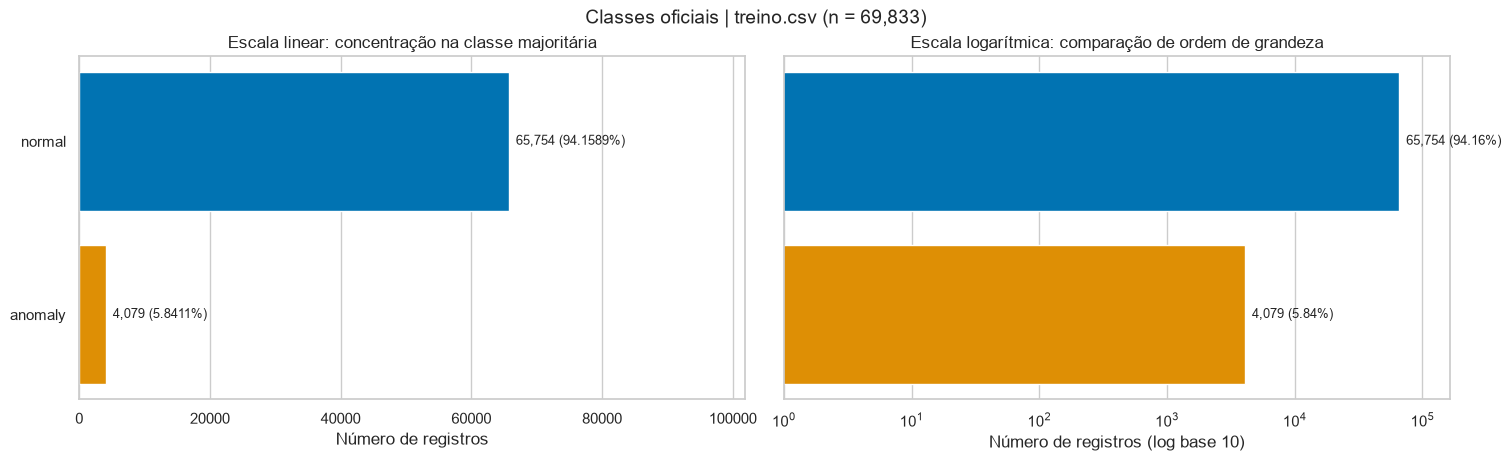

In [17]:
# As mesmas cores identificam cada classe nas duas escalas.
cores_classes = dict(zip(CLASSES, sns.color_palette("colorblind", len(CLASSES))))


def plotar_distribuicao(tabela, classes, titulo, altura):
    """Mostra frequências em escalas linear e logarítmica para comparar maioria e minoria."""
    fig, eixos = plt.subplots(1, 2, figsize=(15, altura), sharey=True, layout="constrained")
    posicoes = np.arange(len(tabela))
    valores = tabela["frequencia"].to_numpy()
    cores = [cores_classes[classe] for classe in classes]
    for eixo in eixos:
        eixo.barh(posicoes, valores, color=cores)
        eixo.set_yticks(posicoes, tabela.index)
        eixo.grid(axis="y", visible=False)
        eixo.set_axisbelow(True)
    eixos[0].invert_yaxis()
    eixos[0].set_xlim(0, valores.max() * 1.55)
    eixos[0].set_title("Escala linear: concentração na classe majoritária")
    eixos[0].set_xlabel("Número de registros")
    for posicao, (quantidade, percentual) in enumerate(
        tabela[["frequencia", "percentual"]].itertuples(index=False, name=None)
    ):
        eixos[0].annotate(
            f"{quantidade:,.0f} ({percentual:.4f}%)", (quantidade, posicao),
            xytext=(5, 0), textcoords="offset points", va="center", fontsize=9,
        )
    eixos[1].set_xscale("log")
    eixos[1].set_xlim(1, valores.max() * 2.5)
    eixos[1].set_title("Escala logarítmica: comparação de ordem de grandeza")
    eixos[1].set_xlabel("Número de registros (log base 10)")
    for posicao, (quantidade, percentual) in enumerate(
        tabela[["frequencia", "percentual"]].itertuples(index=False, name=None)
    ):
        eixos[1].annotate(
            f"{quantidade:,.0f} ({percentual:.2f}%)", (quantidade, posicao),
            xytext=(5, 0), textcoords="offset points", va="center", fontsize=9,
        )
    fig.suptitle(f"{titulo} | treino.csv (n = {n_treino:,})", fontsize=14)
    plt.show()


plotar_distribuicao(freq_rotulos, freq_rotulos.index, "Classes oficiais", altura=4.5)

### 2.3 Diagnóstico quantitativo do desbalanceamento e justificativa do F1-macro

Quantificamos a razão entre a classe majoritária (`normal`) e a minoritária (`anomaly`), verificamos se essa proporção se mantém ao remover duplicatas exatas e simulamos o desempenho de um classificador trivial (que prevê apenas a classe majoritária `normal`) para evidenciar a limitação da acurácia e do F1 ponderado frente ao **F1-macro**.

In [18]:
classe_maioria = freq_rotulos["frequencia"].idxmax()
classe_minoria = freq_rotulos["frequencia"].idxmin()
qtd_maioria = int(freq_rotulos.loc[classe_maioria, "frequencia"])
qtd_minoria = int(freq_rotulos.loc[classe_minoria, "frequencia"])
pct_maioria = float(freq_rotulos.loc[classe_maioria, "percentual"])
pct_minoria = float(freq_rotulos.loc[classe_minoria, "percentual"])
razao_rotulos = qtd_maioria / qtd_minoria

print(f"Classe majoritária ({classe_maioria}): {qtd_maioria:,} registros ({pct_maioria:.4f}%)")
print(f"Classe minoritária ({classe_minoria}): {qtd_minoria:,} registros ({pct_minoria:.4f}%)")
print(f"Razão maioria/minoria ({classe_maioria}/{classe_minoria}): {razao_rotulos:,.2f}:1")

# Verificação complementar: distribuição sem duplicatas exatas (diagnóstico apenas, sem alterar df_train)
freq_sem_dup = tabela_frequencias(df_train.drop_duplicates()[COL_ROTULO]).reindex(CLASSES)
razao_sem_dup = freq_sem_dup.loc["normal", "frequencia"] / freq_sem_dup.loc["anomaly", "frequencia"]
print(f"\nSem duplicatas exatas (n = {int(freq_sem_dup['frequencia'].sum()):,}): "
      f"normal = {int(freq_sem_dup.loc['normal', 'frequencia']):,} ({freq_sem_dup.loc['normal', 'percentual']:.2f}%), "
      f"anomaly = {int(freq_sem_dup.loc['anomaly', 'frequencia']):,} ({freq_sem_dup.loc['anomaly', 'percentual']:.2f}%), "
      f"razão = {razao_sem_dup:,.2f}:1")

# Simulação de classificador trivial que prevê exclusivamente a classe majoritária ('normal')
# Para 'normal': TP = qtd_maioria, FP = qtd_minoria, FN = 0 -> Precisão = p_maj, Recall = 1.0
# Para 'anomaly': TP = 0, FP = 0, FN = qtd_minoria -> Precisão = 0.0, Recall = 0.0, F1 = 0.0
p_maj = qtd_maioria / n_treino
p_min = qtd_minoria / n_treino
f1_normal_trivial = 2 * p_maj * 1.0 / (p_maj + 1.0)
f1_anomaly_trivial = 0.0
f1_macro_trivial = (f1_normal_trivial + f1_anomaly_trivial) / 2
f1_weighted_trivial = p_maj * f1_normal_trivial + p_min * f1_anomaly_trivial

comparativo_metricas = pd.DataFrame({
    "Métrica": [
        "Acurácia global",
        "F1 — classe normal (maioria)",
        "F1 — classe anomaly (minoria)",
        "F1-weighted (ponderado pelo suporte)",
        "F1-macro (média simples entre classes)",
    ],
    "Valor no classificador trivial (só prevê normal)": [
        p_maj,
        f1_normal_trivial,
        f1_anomaly_trivial,
        f1_weighted_trivial,
        f1_macro_trivial,
    ],
    "Interpretação sob desbalanceamento 16,12:1": [
        "Aparenta 94,16% de acerto mesmo ignorando 100% dos ataques",
        "Alto (0,9699) porque recall = 1,0000 e precisão = 0,9416",
        "Zero (0,0000) porque nenhum ataque é detectado (recall = 0)",
        "Continua inflado (0,9133) pelo peso de 94,16% da classe normal",
        "Cai para 0,4850 ao atribuir peso igual (50%/50%) a cada classe",
    ],
}).set_index("Métrica")

print("\nDesempenho de um classificador trivial (sempre prevê 'normal'):")
display(comparativo_metricas)
assert df_train[COL_ROTULO].equals(rotulos_originais), "O alvo original foi alterado."

Classe majoritária (normal): 65,754 registros (94.1589%)
Classe minoritária (anomaly): 4,079 registros (5.8411%)
Razão maioria/minoria (normal/anomaly): 16.12:1

Sem duplicatas exatas (n = 58,478): normal = 54,959 (93.98%), anomaly = 3,519 (6.02%), razão = 15.62:1

Desempenho de um classificador trivial (sempre prevê 'normal'):


,Valor no classificador trivial (só prevê normal),"Interpretação sob desbalanceamento 16,12:1"
Métrica,,
Acurácia global,0.9416,"Aparenta 94,16% de acerto mesmo ignorando 100%..."
F1 — classe normal (maioria),0.9699,"Alto (0,9699) porque recall = 1,0000 e precisã..."
F1 — classe anomaly (minoria),0.0000,"Zero (0,0000) porque nenhum ataque é detectado..."
F1-weighted (ponderado pelo suporte),0.9133,"Continua inflado (0,9133) pelo peso de 94,16% ..."
F1-macro (média simples entre classes),0.4850,"Cai para 0,4850 ao atribuir peso igual (50%/50..."


### 2.4 Síntese do Membro 2 — distribuição das classes, F1-macro e balanceamento

**Quantidades, proporções e classe minoritária.** O conjunto `treino.csv` possui **69.833 registros** integralmente rotulados em duas classes oficiais, sem valores ausentes ou inconsistências de grafia em `class`: a classe majoritária é **`normal`, com 65.754 instâncias (94,1589%)**, e a classe minoritária é **`anomaly`, com 4.079 instâncias (5,8411%)**. Diferentemente da versão antiga da base, o alvo já é estritamente binário e não há decomposição em famílias ou subtipos de ataque. A razão de desbalanceamento é de **16,12:1** (aproximadamente 16 conexões normais para cada anomalia). Mesmo ao descontar as 11.355 duplicatas exatas da base (restando 58.478 registros únicos), a distribuição permanece praticamente idêntica — **54.959 `normal` (93,98%)** contra **3.519 `anomaly` (6,02%)**, razão **15,62:1** —, demonstrando que a escassez da classe `anomaly` é uma característica estrutural do problema.

**Por que usar o F1-macro em vez da acurácia isolada.** Sob a proporção 94,16% versus 5,84%, métricas globais ponderadas pelo suporte mascaram falhas graves na detecção de intrusão. Um classificador trivial que simplesmente rotule todo o tráfego como `normal` obtém **94,16% de acurácia** e **0,9133 de F1-weighted**, embora apresente **recall zero na classe `anomaly`** (100% de falsos negativos para ataques). O **F1-macro** resolve essa distorção ao calcular a média aritmética simples dos escores F1 das duas classes:

$$\text{F1}_{\text{macro}} = \frac{\text{F1}_{\text{normal}} + \text{F1}_{\text{anomaly}}}{2}$$

Nessa formulação, tanto `normal` (65.754 registros) quanto `anomaly` (4.079 registros) recebem **exatamente o mesmo peso (50% cada)**. No classificador trivial, como $\text{F1}_{\text{normal}} = 0{,}9699$ e $\text{F1}_{\text{anomaly}} = 0{,}0000$, o **F1-macro cai para 0,4850**, expondo imediatamente a incapacidade de detectar anomalias. Além disso, como o F1 de `anomaly` é a média harmônica entre precisão e recall dessa classe, maximizar o F1-macro exige não apenas recuperar os ataques (reduzindo falsos negativos), mas também controlar os falsos positivos: dado que a classe `normal` é 16,12 vezes maior, mesmo uma taxa moderada de falsos alarmes em conexões normais geraria um volume absoluto de falsos positivos capaz de derrubar a precisão de `anomaly` e, consequentemente, o F1-macro.

**Propostas de técnicas de balanceamento para a Etapa 2.** Na próxima etapa, compararemos explicitamente o **baseline sem reamostragem (`none`)** contra pelo menos duas estratégias de balanceamento sobre as mesmas dobras de validação e com o mesmo classificador de referência:
1. **Subamostragem aleatória da maioria (`RandomUnderSampler`):** reduz aleatoriamente a quantidade de registros `normal` na partição de treino de cada dobra para equilibrar a proporção com `anomaly`. Tem como vantagem reduzir o custo computacional de treinamento, mas apresenta o risco de descartar exemplos informativos do tráfego normal e aumentar a variância das fronteiras de decisão (gerando mais falsos positivos na validação).
2. **Superamostragem sintética da minoria (`SMOTE` — *Synthetic Minority Over-sampling Technique*, ou variação como `BorderlineSMOTE`):** gera novos exemplos sintéticos da classe `anomaly` por interpolação entre os $k$ vizinhos mais próximos da própria minoria, preservando 100% dos registros da classe `normal`. O ponto de atenção a investigar na Etapa 2 é o risco de sobreajuste (*overfitting*) ou de criação de amostras sintéticas invadindo a região da classe `normal` quando há sobreposição ou conflito de rótulos.

**Protocolo contra vazamento de dados (*data leakage*) na Etapa 2:**
- Utilizar validação cruzada estratificada (`StratifiedKFold`) dentro de `treino.csv` para preservar a proporção de 94,16% / 5,84% em cada dobra.
- Inserir o amostrador em uma `imblearn.pipeline.Pipeline` para que o balanceamento atue **estritamente na partição de treino de cada dobra**; as partições de validação interna e o conjunto `teste_sem_rotulo.csv` jamais devem ser balanceados ou reamostrados.
- Como o `SMOTE` calcula distâncias no espaço de atributos, aplicá-lo somente após a imputação de valores ausentes, a codificação das variáveis categóricas e a padronização numérica ajustadas dentro da respectiva dobra.

## Membro 3 — Atributos categóricos e alta cardinalidade

Revisar o código reaproveitado e acrescentar a investigação de diferenças de caixa/espaços e ausências.
Justificar a codificação de service e o tratamento de categorias desconhecidas sem ajustar encoders nesta etapa.

### 3.1 Identificação e cardinalidade

Analisamos os atributos textuais do treino, comparando suas categorias antes e depois de remover espaços nas bordas e uniformizar maiúsculas e minúsculas. A comparação usa uma cópia e preserva os valores ausentes, sem alterar a base original.

In [19]:
# Reaproveita a análise de cardinalidade para todos os categóricos do CSV.
categoricos_m3 = COLS_CATEGORICAS.copy()
dados_categoricos_m3 = df_train[categoricos_m3].copy()

cardinalidade_m3 = pd.DataFrame({"tipo": dados_categoricos_m3.dtypes.astype(str),"categorias_distintas": dados_categoricos_m3.nunique(),"valores_ausentes": dados_categoricos_m3.isna().sum(),})
cardinalidade_m3.index.name = "atributo"

display(cardinalidade_m3)

for atributo in categoricos_m3:
    categorias = sorted(dados_categoricos_m3[atributo].dropna().unique())
    print(f"\n{atributo} ({len(categorias)} categorias):")
    print(", ".join(categorias))

# Compara as categorias em uma cópia, sem alterar os dados originais.
categoricos_normalizados_m3 = dados_categoricos_m3.copy()
for atributo in categoricos_m3:
    categoricos_normalizados_m3[atributo] = (dados_categoricos_m3[atributo].str.strip().str.lower())

comparacao_m3 = pd.DataFrame({
    "categorias_originais": dados_categoricos_m3.nunique(),
    "apos_remover_espacos": [dados_categoricos_m3[c].str.strip().nunique() for c in categoricos_m3],
    "apos_espacos_e_caixa": categoricos_normalizados_m3.nunique(),
    "registros_com_espacos_nas_bordas": [(dados_categoricos_m3[c].notna() & dados_categoricos_m3[c].ne(dados_categoricos_m3[c].str.strip())).sum() for c in categoricos_m3],
    "ausentes": dados_categoricos_m3.isna().sum()
})

display(comparacao_m3)
# Confirma que a normalização preservou as posições dos ausentes.
assert categoricos_normalizados_m3.isna().equals(dados_categoricos_m3.isna())

,tipo,categorias_distintas,valores_ausentes
atributo,,,
protocol_type,str,6,0
service,str,96,4416
flag,str,19,4093
tipo_alerta_soc,str,2,0



protocol_type (6 categorias):
ICMP, TCP, UDP, icmp, tcp, udp

service (96 categorias):
IRC, IRC , X11, X11 , Z39_50, auth, auth , bgp, bgp , courier, csnet_ns, ctf, ctf , daytime, discard, domain, domain_u, domain_u , echo, eco_i, eco_i , ecr_i, ecr_i , efs, exec, exec , finger, finger , ftp, ftp , ftp_data, ftp_data , gopher, hostnames, http, http , http_2784, http_443, imap4, imap4 , iso_tsap, klogin, kshell, ldap, ldap , link, login, login , mtp, name, netbios_dgm, netbios_dgm , netbios_ns, netbios_ssn, netstat, nnsp, nntp, ntp_u, ntp_u , other, other , pm_dump, pop_2, pop_3, pop_3 , printer, private, private , red_i, remote_job, remote_job , rje, shell, smtp, smtp , sql_net, ssh, sunrpc, supdup, supdup , systat, telnet, telnet , tftp_u, tim_i, time, urh_i, urp_i, urp_i , uucp, uucp , uucp_path, uucp_path , vmnet, vmnet , whois

flag (19 categorias):
OTH, REJ, RSTO, RSTOS0, RSTR, S0, S1, S2, S3, SF, SH, rej, rsto, rstr, s0, s1, s2, s3, sf

tipo_alerta_soc (2 categorias):
ALERTA, OK

,categorias_originais,apos_remover_espacos,apos_espacos_e_caixa,registros_com_espacos_nas_bordas,ausentes
protocol_type,6,6,3,0,0
service,96,67,67,1292,4416
flag,19,19,11,0,4093
tipo_alerta_soc,2,2,2,0,0


Após padronizar a escrita, `protocol_type` passou de 6 para 3 categorias, `service` de 96 para 67 e `flag` de 19 para 11. `tipo_alerta_soc` permaneceu com 2. Foram encontrados espaços nas bordas em 1.292 registros de `service`, além de 4.416 ausentes nessa coluna e 4.093 em `flag`.

### 3.2 Distribuição dos atributos categóricos

Calculamos as frequências absolutas e percentuais após remover espaços nas bordas e uniformizar maiúsculas e minúsculas em uma cópia. Os ausentes aparecem como `NaN`, separados das categorias observadas, e os percentuais consideram todas as linhas do treino.

In [20]:
# Guarda as distribuições para reutilização nas próximas análises.
frequencias_m3 = {}

for atributo in categoricos_m3:
    tabela = categoricos_normalizados_m3[atributo].value_counts(dropna=False).rename_axis("categoria").to_frame("frequencia")
    tabela["percentual"] = (tabela["frequencia"] / len(dados_categoricos_m3) * 100)
    frequencias_m3[atributo] = tabela

    # Confere se todos os registros foram contabilizados.
    assert tabela["frequencia"].sum() == len(dados_categoricos_m3)
    assert np.isclose(tabela["percentual"].sum(), 100)
    print(f"\nDistribuição de {atributo}:")
    with pd.option_context("display.max_rows", None):
        display(tabela)


Distribuição de protocol_type:


,frequencia,percentual
categoria,,
tcp,56010,80.2056
udp,12180,17.4416
icmp,1643,2.3528



Distribuição de service:


,frequencia,percentual
categoria,,
http,36218,51.8637
domain_u,7671,10.9848
smtp,6070,8.6922
NaN,4416,6.3237
ftp_data,4269,6.1132
private,2952,4.2272
other,2173,3.1117
ftp,1097,1.5709
telnet,888,1.2716



Distribuição de flag:


,frequencia,percentual
categoria,,
sf,59278,84.8854
NaN,4093,5.8611
rej,2917,4.1771
s0,2432,3.4826
rstr,338,0.4840
s1,292,0.4181
rsto,291,0.4167
s2,109,0.1561
s3,54,0.0773



Distribuição de tipo_alerta_soc:


,frequencia,percentual
categoria,,
ok,64797,92.7885
alerta,5036,7.2115


### 3.3 Serviços frequentes, raros e cauda longa

Analisamos os dez serviços mais frequentes e os serviços com menos de 100 registros, considerados raros neste diagnóstico. O limiar de 100 registros corresponde a aproximadamente 0,14% do treino e serve apenas como critério exploratório. Os ausentes não são considerados serviços, mas os percentuais continuam calculados sobre todas as linhas do treino.

Dez serviços mais frequentes:


,frequencia,percentual
categoria,,
http,36218,51.8637
domain_u,7671,10.9848
smtp,6070,8.6922
ftp_data,4269,6.1132
private,2952,4.2272
other,2173,3.1117
ftp,1097,1.5709
telnet,888,1.2716
eco_i,601,0.8606



Serviços raros: menos de 100 registros:


,frequencia,percentual
categoria,,
time,87,0.1246
imap4,69,0.0988
x11,59,0.0845
domain,56,0.0802
uucp_path,44,0.0630
uucp,43,0.0616
ctf,42,0.0601
iso_tsap,41,0.0587
link,41,0.0587



Os 10 serviços mais frequentes representam 89.51% dos registros.
Serviços raros: 51 de 67 categorias (76.12% das categorias).
Esses serviços somam 1,410 registros (2.0191% do treino).


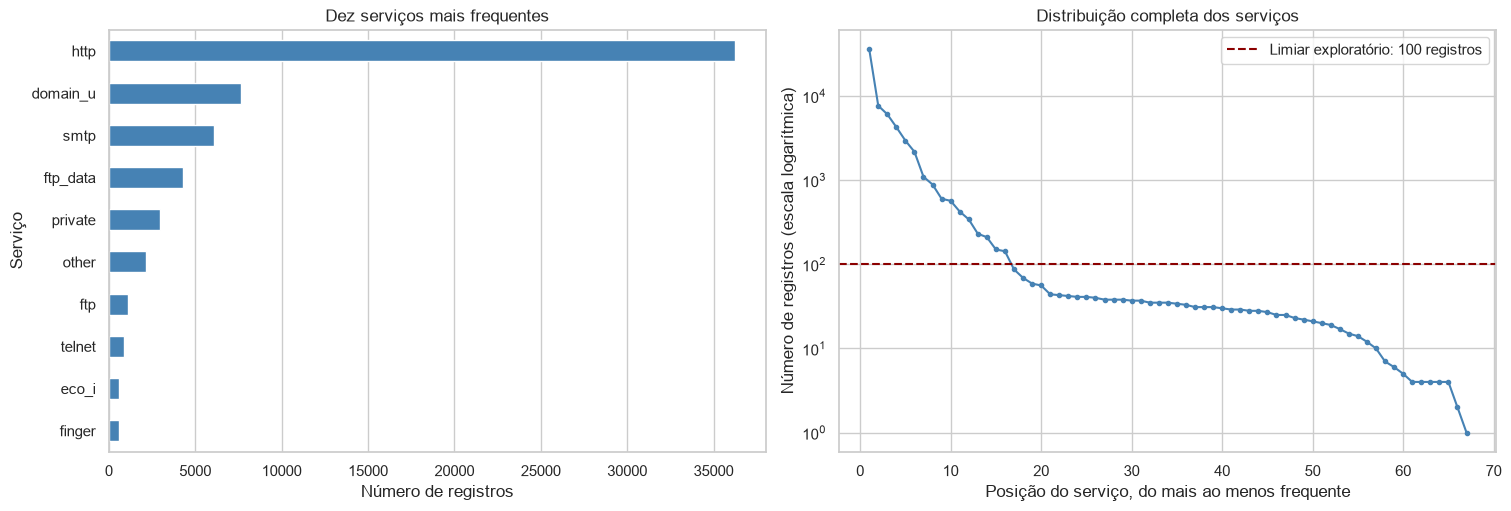

In [21]:
#Reutiliza as frequências calculadas na seção 3.2.
servicos_m3 = frequencias_m3["service"].loc[frequencias_m3["service"].index.notna()].copy()
# Ausência não é um serviço; percentuais continuam sobre todas as linhas do treino.
limiar_raridade_m3 = 100
top10_m3 = servicos_m3.head(10)
raros_m3 = servicos_m3[servicos_m3["frequencia"] < limiar_raridade_m3]

print("Dez serviços mais frequentes:")
display(top10_m3)
print(f"\nServiços raros: menos de {limiar_raridade_m3} registros:")
display(raros_m3)

#quantifica a concentração e o tamanho da cauda longa
n_servicos_m3 = len(servicos_m3)
n_raros_m3 = len(raros_m3)
registros_raros_m3 = int(raros_m3["frequencia"].sum())

print(f"\nOs 10 serviços mais frequentes representam "f"{top10_m3['percentual'].sum():.2f}% dos registros.")
print(f"Serviços raros: {n_raros_m3} de {n_servicos_m3} categorias "f"({100 * n_raros_m3 / n_servicos_m3:.2f}% das categorias).")
print(f"Esses serviços somam {registros_raros_m3:,} registros "f"({raros_m3['percentual'].sum():.4f}% do treino).")

#Visualiza os serviços dominantes e a distribuição completa.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
top10_m3["frequencia"].sort_values().plot.barh(ax=eixos[0], color="steelblue")
eixos[0].set_title("Dez serviços mais frequentes")
eixos[0].set_xlabel("Número de registros")
eixos[0].set_ylabel("Serviço")
eixos[0].grid(axis="y", visible=False)
posicoes_m3 = np.arange(1, n_servicos_m3 + 1)
eixos[1].plot(posicoes_m3,servicos_m3["frequencia"].to_numpy(),marker=".",color="steelblue",)
eixos[1].axhline(limiar_raridade_m3,color="darkred",linestyle="--",label="Limiar exploratório: 100 registros",)
eixos[1].set_yscale("log")
eixos[1].set_title("Distribuição completa dos serviços")
eixos[1].set_xlabel("Posição do serviço, do mais ao menos frequente")
eixos[1].set_ylabel("Número de registros (escala logarítmica)")
eixos[1].legend()

plt.show()

Os dez serviços mais frequentes concentram 89,51% dos registros do treino, com `http` representando 51,86%. Pelo critério de menos de 100 registros, encontramos 51 serviços raros entre as 67 categorias (76,12%). Apesar de serem a maioria das categorias, eles somam apenas 1.410 registros, ou 2,0191% do treino. Isso evidencia a cauda longa: poucos serviços concentram muitas conexões, enquanto vários aparecem pouco. Os 4.416 valores ausentes de `service` foram contabilizados separadamente e não entram como serviços raros. A baixa frequência, sozinha, não justifica remover ou agrupar essas categorias.

### 3.4 Discussão sobre alternativas de codificação e categorias desconhecidas

Antes de codificar, precisamos considerar as diferenças de escrita e os valores ausentes. Após remover espaços nas bordas e uniformizar maiúsculas e minúsculas, encontramos 3 categorias em `protocol_type`, 67 em `service`, 11 em `flag` e 2 em `tipo_alerta_soc`. No One-Hot Encoding, isso corresponde a 83 colunas sem descartar categorias, ou 85 se os ausentes de `service` e `flag` forem representados como uma categoria adicional em cada atributo. Essa quantidade não impede o uso da técnica, mas os serviços raros gerariam colunas com poucos valores 1. A presença de `tipo_alerta_soc` nesta análise não significa que ele será usado no modelo, pois sua origem e disponibilidade ainda precisam ser investigadas pelo Membro 5.

Count Encoding e Frequency Encoding mantêm uma coluna por atributo, substituindo as categorias por suas contagens ou frequências. Porém, categorias com a mesma frequência recebem o mesmo valor e perdem sua distinção. Agrupar serviços raros também pode reduzir a quantidade de categorias, mas pode juntar serviços com comportamentos diferentes. O limite de 100 registros foi usado apenas para descrever a raridade, sem aplicar agrupamentos. Os ausentes devem ser tratados separadamente, pois não representam um serviço pouco frequente.

Para categorias desconhecidas em dados futuros, o One-Hot pode deixar as colunas do atributo com valor zero quando configurado para isso. No Count/Frequency Encoding, podemos definir zero como valor padrão para categorias não encontradas. Em qualquer opção, precisamos distinguir uma categoria desconhecida de um valor ausente e aprender as categorias e frequências somente na parte de treinamento de cada divisão de validação. Nenhum codificador foi ajustado nesta análise e o teste oficial não foi consultado.

### 3.5 Síntese do Membro 3

A análise mostrou que diferenças de escrita aumentavam a quantidade de categorias: após remover espaços nas bordas e uniformizar maiúsculas e minúsculas, `protocol_type` passou de 6 para 3 categorias, `service` de 96 para 67 e `flag` de 19 para 11. `tipo_alerta_soc` permaneceu com 2 categorias. Também encontramos 4.416 ausentes em `service` e 4.093 em `flag`, que precisam ser considerados separadamente dos serviços raros. Os dez serviços mais frequentes concentram 89,51% dos registros, enquanto os 51 serviços com menos de 100 ocorrências somam apenas 2,0191% do treino.

Esses resultados mostram a importância de padronizar a escrita antes da codificação e definir como representar os ausentes. O One-Hot preserva a distinção entre categorias, enquanto Count/Frequency Encoding e agrupamento de raras oferecem alternativas com as limitações discutidas na seção 3.4. Nenhuma codificação ou remoção foi aplicada à base original. O Membro 5 pode usar `comparacao_m3`, `frequencias_m3` e `raros_m3` como apoio para investigar a associação com a classe e a possível presença de vazamento, especialmente em `tipo_alerta_soc`. Toda a análise utilizou apenas o treino.

## Membro 4 — Redundâncias, constantes e inconsistências

### 4.1 Duplicatas exatas e duplicatas de atributos

Reutilizamos os critérios de linhas completas e atributos sem classe. Aqui entram todos os atributos disponíveis.

In [22]:
COL_ROTULO_M4 = COL_ROTULO
ATRIB_M4 = COLS_ATRIBUTOS.copy()
n_treino_m4 = len(df_train)
n_dup_total = int(df_train.duplicated().sum())
n_dup_atrib_rotulo = int(df_train.duplicated(subset=ATRIB_M4 + [COL_ROTULO_M4]).sum())
mascara_dup_parcial = df_train.duplicated(subset=ATRIB_M4, keep=False)
n_linhas_dup_parcial = int(mascara_dup_parcial.sum())
n_excedentes_dup_parcial = int(df_train.duplicated(subset=ATRIB_M4).sum())
resumo_dup_m4 = pd.DataFrame({
    "criterio": ["Exata: todas as colunas", "Atributos iguais: todas as linhas dos grupos", "Atributos iguais: excedentes"],
    "n_linhas": [n_dup_total, n_linhas_dup_parcial, n_excedentes_dup_parcial],
})
resumo_dup_m4["pct_do_treino"] = 100 * resumo_dup_m4.n_linhas / n_treino_m4
display(resumo_dup_m4)

,criterio,n_linhas,pct_do_treino
0,Exata: todas as colunas,11355,16.2602
1,Atributos iguais: todas as linhas dos grupos,25788,36.9281
2,Atributos iguais: excedentes,13057,18.6975


In [23]:
# Revisão de 4.1: mesmo diagnóstico em uma cópia (categorias normalizadas) e sem derivados/operacionais.
COLS_DERIVADAS_M4 = ["src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod"]
COLS_OPERACIONAIS_M4 = ["score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]
ATRIB_ORIG_M4 = [c for c in ATRIB_M4 if c not in COLS_DERIVADAS_M4 + COLS_OPERACIONAIS_M4]

df_copia_m4 = df_train.copy()
for c in df_copia_m4[ATRIB_M4].select_dtypes(exclude="number").columns:
    df_copia_m4[c] = df_copia_m4[c].str.strip().str.lower()

def diagnostico_dup(d, cols):
    conflito = d.groupby(cols, dropna=False)[COL_ROTULO_M4].transform("nunique") > 1
    return {"duplicatas_exatas": int(d.duplicated(subset=cols + [COL_ROTULO_M4]).sum()),
            "linhas_atributos_iguais": int(d.duplicated(subset=cols, keep=False).sum()),
            "grupos_conflitantes": len(d.loc[conflito].drop_duplicates(subset=cols)),
            "linhas_conflitantes": int(conflito.sum())}

cenarios_m4 = {
    "Todos os atributos, bruto": (df_train, ATRIB_M4),
    "Todos os atributos, normalizado": (df_copia_m4, ATRIB_M4),
    "Sem derivados e operacionais, bruto": (df_train, ATRIB_ORIG_M4),
    "Sem derivados e operacionais, normalizado": (df_copia_m4, ATRIB_ORIG_M4),
}
revisao_dup_m4 = pd.DataFrame({k: diagnostico_dup(d, cols) for k, (d, cols) in cenarios_m4.items()}).T
display(revisao_dup_m4)

tamanho_grupos_m4 = df_train.loc[mascara_dup_parcial].groupby(ATRIB_M4, dropna=False).size().value_counts().sort_index()
print("Linhas por grupo de atributos iguais -> nº de grupos:", tamanho_grupos_m4.to_dict())

# Efeito de cada tratamento sobre as classes, só diagnóstico e nada é removido de df_train
efeito_trat_m4 = pd.DataFrame({
    "Base atual": df_train[COL_ROTULO_M4].value_counts(),
    "Sem duplicatas exatas": df_train.drop_duplicates()[COL_ROTULO_M4].value_counts(),
    "Uma linha por grupo de atributos": df_train.drop_duplicates(subset=ATRIB_M4)[COL_ROTULO_M4].value_counts(),
    "Sem linhas de grupos repetidos": df_train.loc[~mascara_dup_parcial, COL_ROTULO_M4].value_counts(),
}).T
efeito_trat_m4["total"] = efeito_trat_m4.sum(axis=1)
efeito_trat_m4["pct_anomaly"] = 100 * efeito_trat_m4["anomaly"] / efeito_trat_m4["total"]
display(efeito_trat_m4)

,duplicatas_exatas,linhas_atributos_iguais,grupos_conflitantes,linhas_conflitantes
"Todos os atributos, bruto",11355,25788,1702,3730
"Todos os atributos, normalizado",11355,25788,1702,3730
"Sem derivados e operacionais, bruto",11362,25798,1702,3730
"Sem derivados e operacionais, normalizado",11365,25804,1702,3730


Linhas por grupo de atributos iguais -> nº de grupos: {2: 12405, 3: 326}


class,normal,anomaly,total,pct_anomaly
Base atual,65754,4079,69833,5.8411
Sem duplicatas exatas,54959,3519,58478,6.0176
Uma linha por grupo de atributos,54112,2664,56776,4.6921
Sem linhas de grupos repetidos,42594,1451,44045,3.2944


### 4.2 Atributos iguais com classes divergentes

Reaproveitamos o agrupamento e o cálculo dos registros fora da classe majoritária de cada grupo,
agora somente para normal/anomaly. É um limite de erro de resubstituição para esses atributos,
não uma estimativa do erro em dados futuros.

In [24]:
sub_dup_m4 = df_train.loc[mascara_dup_parcial, ATRIB_M4 + [COL_ROTULO_M4]].copy()
def _maior_contagem(s):
    return int(s.value_counts().iloc[0])

grupos_m4 = (sub_dup_m4.groupby(ATRIB_M4, sort=False, dropna=False)
    .agg(n_registros=(COL_ROTULO_M4, "size"), n_rotulos=(COL_ROTULO_M4, "nunique"),
         rotulos=(COL_ROTULO_M4, lambda s: " | ".join(sorted(s.unique()))),
         maior_rotulo=(COL_ROTULO_M4, _maior_contagem)).reset_index())
conflitos_m4 = grupos_m4[grupos_m4.n_rotulos > 1].copy()
n_grupos_conflito = len(conflitos_m4)
n_linhas_conflito = int(conflitos_m4.n_registros.sum())
erro_min_rotulos = int((conflitos_m4.n_registros - conflitos_m4.maior_rotulo).sum())
print(f"Grupos conflitantes: {n_grupos_conflito}; linhas: {n_linhas_conflito}")
print(f"Erro mínimo de resubstituição para esses atributos: {erro_min_rotulos} registros")
display(conflitos_m4[["protocol_type", "service", "flag", "n_registros", "rotulos"]].head(12))  # há muitos grupos
linhas_conflito_m4 = sub_dup_m4.merge(conflitos_m4[ATRIB_M4], on=ATRIB_M4, how="inner")
afetados_m4 = linhas_conflito_m4[COL_ROTULO_M4].value_counts().rename("linhas_em_conflito").to_frame()
afetados_m4["total_no_treino"] = df_train[COL_ROTULO_M4].value_counts().reindex(afetados_m4.index)
afetados_m4["pct_da_classe"] = 100 * afetados_m4.linhas_em_conflito / afetados_m4.total_no_treino
assert len(linhas_conflito_m4) == n_linhas_conflito
display(afetados_m4)

Grupos conflitantes: 1702; linhas: 3730
Erro mínimo de resubstituição para esses atributos: 1702 registros


,protocol_type,service,flag,n_registros,rotulos
1,tcp,finger,SF,2,anomaly | normal
16,tcp,http,S0,3,anomaly | normal
20,tcp,private,S0,2,anomaly | normal
22,tcp,iso_tsap,S0,3,anomaly | normal
27,icmp,eco_i,SF,2,anomaly | normal
30,tcp,private,S0,2,anomaly | normal
32,tcp,http,SF,2,anomaly | normal
35,icmp,urp_i,NaN,3,anomaly | normal
37,tcp,http,SF,2,anomaly | normal
40,tcp,ftp_data,S0,2,anomaly | normal


,linhas_em_conflito,total_no_treino,pct_da_classe
class,,,
anomaly,1896,4079,46.4820
normal,1834,65754,2.7892


### 4.3 Atributos constantes (variância zero)

Um atributo constante tem variância zero, ou seja, apresenta o mesmo valor em todas as linhas e não ajuda a distinguir classes. Além disso, pode causar problemas em normalizações.

Verificamos isso contando os valores únicos nos atributos do CSV e calculando o desvio padrão dos numéricos. Também buscamos colunas idênticas para identificar atributos redundantes.

In [25]:
# 4.3 Atributos constantes (variância zero) e colunas idênticas entre si.

numericas_m4 = df_train[ATRIB_M4].select_dtypes(include="number").columns.tolist()

perfil_var_m4 = pd.DataFrame({
    "ausentes": df_train[ATRIB_M4].isna().sum(),
    "n_valores_unicos": df_train[ATRIB_M4].nunique(),
    "desvio_padrao": df_train[numericas_m4].std(),      # NaN nos categóricos
    "variancia": df_train[numericas_m4].var(),
})

constantes_unicos = set(perfil_var_m4.index[perfil_var_m4["n_valores_unicos"] == 1])
constantes_std = set(perfil_var_m4.index[perfil_var_m4["desvio_padrao"] == 0])
assert constantes_std <= constantes_unicos, "Divergência entre os dois critérios"
constantes_m4 = sorted(constantes_unicos)

print(f"Atributos com 1 único valor (entre valores observados): {constantes_m4}")
print(f"Atributos numéricos com desvio padrão = 0: {sorted(constantes_std)}")
if constantes_m4:
    display(pd.DataFrame({
        "valor_unico": [df_train[c].dropna().iloc[0] for c in constantes_m4],
        "n_registros": n_treino_m4,
    }, index=constantes_m4))

print("\nAtributos com menos valores distintos:")
display(perfil_var_m4.sort_values("n_valores_unicos").head(8))

# Colunas idênticas entre si (redundância exata de atributos)
pares_identicos_m4 = [(a, b) for a, b in combinations(ATRIB_M4, 2)
                      if df_train[a].equals(df_train[b])]
print(f"\nPares de colunas idênticas entre os atributos do CSV: {len(pares_identicos_m4)}")
for a, b in pares_identicos_m4:
    print(f"  {a} == {b}")

Atributos com 1 único valor (entre valores observados): ['num_outbound_cmds']
Atributos numéricos com desvio padrão = 0: ['num_outbound_cmds']


,valor_unico,n_registros
num_outbound_cmds,0,69833



Atributos com menos valores distintos:


,ausentes,n_valores_unicos,desvio_padrao,variancia
num_outbound_cmds,0,1,0.0000,0.0000
is_host_login,0,2,0.0054,0.0000
logged_in,4250,2,0.4674,0.2185
land,0,2,0.0120,0.0001
is_guest_login,0,2,0.1098,0.0121
root_shell,3880,2,0.0462,0.0021
tipo_alerta_soc,0,2,NaN,NaN
protocolo_cod,0,3,0.4685,0.2195



Pares de colunas idênticas entre os atributos do CSV: 0


### 4.4 Quase constantes, concentração em zero e domínio de su_attempted

Mantemos os limiares exploratórios de 99%, 90% e 75%. A concentração do valor dominante é calculada entre observações não ausentes, com o percentual ausente separado. Ausentes não contam como valores raros. Comparar a proporção de anomaly fora do valor dominante com a proporção atual do treino.
Verificar su_attempted sem assumir que ausência ou valor 2 deva ser convertido automaticamente para 1.

In [26]:
# 4.4 Quase constantes, concentração em zero e domínio de su_attempted.
LIMIAR_DOMINANTE_M4 = 99.0     # quase constante: >= 99% dos registros no mesmo valor
LIMIAR_CONCENTRADO_M4 = 90.0   # concentrado: entre 90% e 99% no mesmo valor
LIMIAR_ZEROS_M4 = 75.0         # apenas para listar atributos muito concentrados em zero

def perfil_concentracao(serie):
    contagem = serie.value_counts()
    if contagem.empty:
        return {"valor_dominante": np.nan, "pct_dominante": np.nan, "n_fora_do_dominante": 0}
    freq1 = int(contagem.iloc[0])
    return {
        "valor_dominante": contagem.index[0],
        "pct_dominante": 100 * freq1 / serie.notna().sum(),
        "n_fora_do_dominante": int(serie.notna().sum()) - freq1,
    }

conc_m4 = pd.DataFrame([{"atributo": c, **perfil_concentracao(df_train[c])} for c in ATRIB_M4]).set_index("atributo")
conc_m4["pct_zeros"] = (df_train[numericas_m4] == 0).mean() * 100      # NaN nos categóricos sobre todas as linhas (ausentes não contam como zero)

conc_m4["pct_ausentes"] = df_train[ATRIB_M4].isna().mean() * 100
eh_constante = (conc_m4["n_fora_do_dominante"] == 0) & (conc_m4["pct_ausentes"] == 0)
eh_q99 = conc_m4["pct_dominante"] >= LIMIAR_DOMINANTE_M4
eh_conc = conc_m4["pct_dominante"] >= LIMIAR_CONCENTRADO_M4
conc_m4["categoria"] = np.select(
    [eh_constante, eh_q99, eh_conc],
    ["constante", "quase constante (>= 99% no mesmo valor)", "concentrado (90% a 99% no mesmo valor)"],
    default="sem concentração relevante",
)

candidatos_nzv_m4 = conc_m4.index[~conc_m4["categoria"].isin(["constante", "sem concentração relevante"])].tolist()

print(conc_m4["categoria"].value_counts().to_string())
print(f"\nAtributos com >= {LIMIAR_ZEROS_M4:.0f}% de zeros: {int((conc_m4['pct_zeros'] >= LIMIAR_ZEROS_M4).sum())}")

mostrar_m4 = conc_m4[(conc_m4["categoria"] != "sem concentração relevante")
                     | (conc_m4["pct_zeros"] >= LIMIAR_ZEROS_M4)]
display(mostrar_m4.sort_values("pct_dominante", ascending=False))

eh_ataque_m4 = df_train[COL_ROTULO_M4] != "normal"
base_ataque_m4 = 100 * eh_ataque_m4.mean()
linhas_sinal = []
for c in candidatos_nzv_m4:
    fora = df_train[c].notna() & (df_train[c] != conc_m4.loc[c, "valor_dominante"])
    if not fora.any():
        continue
    rotulos_fora = df_train.loc[fora, COL_ROTULO_M4].value_counts(normalize=True)
    linhas_sinal.append({
        "atributo": c,
        "n_fora_do_dominante": int(fora.sum()),
        "pct_ataque_fora_do_dominante": 100 * eh_ataque_m4[fora].mean(),
        "rotulo_mais_comum_fora": rotulos_fora.index[0],
        "pct_desse_rotulo_fora": 100 * rotulos_fora.iloc[0],
    })
sinal_nzv_m4 = pd.DataFrame(linhas_sinal, columns=["atributo", "n_fora_do_dominante", "pct_ataque_fora_do_dominante", "rotulo_mais_comum_fora", "pct_desse_rotulo_fora"]).set_index("atributo")
print(f"\nBase inteira: {base_ataque_m4:.2f}% dos registros são anomaly.")
display(sinal_nzv_m4.sort_values("n_fora_do_dominante"))

# Domínio de su_attempted
dist_su_m4 = df_train["su_attempted"].value_counts(dropna=False).sort_index().rename("frequencia").to_frame()
dist_su_m4["percentual"] = 100 * dist_su_m4["frequencia"] / n_treino_m4
n_su_fora_dominio = int((df_train["su_attempted"].notna() & ~df_train["su_attempted"].isin([0, 1])).sum())
print("\nDistribuição de su_attempted:")
display(dist_su_m4)
print(f"Registros com su_attempted fora de {{0, 1}}: {n_su_fora_dominio}")
if n_su_fora_dominio:
    display(df_train.loc[df_train["su_attempted"].notna() & ~df_train["su_attempted"].isin([0, 1]), COL_ROTULO_M4]
            .value_counts().rename("registros_com_su_attempted_fora_do_dominio").to_frame())

categoria
sem concentração relevante                 27
quase constante (>= 99% no mesmo valor)    11
concentrado (90% a 99% no mesmo valor)     10
constante                                   1

Atributos com >= 75% de zeros: 25


,valor_dominante,pct_dominante,n_fora_do_dominante,pct_zeros,pct_ausentes,categoria
atributo,,,,,,
num_outbound_cmds,0,100.0000,0,100.0000,0.0000,constante
is_host_login,0,99.9971,2,99.9971,0.0000,quase constante (>= 99% no mesmo valor)
urgent,0,99.9914,6,99.9914,0.0000,quase constante (>= 99% no mesmo valor)
land,0,99.9857,10,99.9857,0.0000,quase constante (>= 99% no mesmo valor)
num_shells,0,99.9513,34,99.9513,0.0000,quase constante (>= 99% no mesmo valor)
su_attempted,0.0000,99.9023,65,95.1728,4.7342,quase constante (>= 99% no mesmo valor)
num_failed_logins,0,99.8740,88,99.8740,0.0000,quase constante (>= 99% no mesmo valor)
wrong_fragment,0,99.8325,117,99.8325,0.0000,quase constante (>= 99% no mesmo valor)
root_shell,0.0000,99.7862,141,94.2420,5.5561,quase constante (>= 99% no mesmo valor)



Base inteira: 5.84% dos registros são anomaly.


,n_fora_do_dominante,pct_ataque_fora_do_dominante,rotulo_mais_comum_fora,pct_desse_rotulo_fora
atributo,,,,
is_host_login,2,0.0000,normal,100.0000
urgent,6,0.0000,normal,100.0000
land,10,10.0000,normal,90.0000
num_shells,34,0.0000,normal,100.0000
su_attempted,65,0.0000,normal,100.0000
num_failed_logins,88,22.7273,normal,77.2727
wrong_fragment,117,46.1538,normal,53.8462
root_shell,141,4.2553,normal,95.7447
num_file_creations,204,2.9412,normal,97.0588



Distribuição de su_attempted:


,frequencia,percentual
su_attempted,,
0.0000,66462,95.1728
1.0000,16,0.0229
2.0000,49,0.0702
NaN,3306,4.7342


Registros com su_attempted fora de {0, 1}: 49


,registros_com_su_attempted_fora_do_dominio
class,
normal,49


### 4.5 Propostas para a etapa 2 — revisar com a equipe

A tabela abaixo reaproveita os diagnósticos para listar propostas, sem executar remoções ou correções.
Comparar tratamentos de redundância/inconsistência na etapa 2, dentro da validação no treino.
Não descartar atributos apenas por correlação exploratória ou poucos valores raros.

In [27]:
# Relações entre derivados e originais (valores e padrões de ausência).
# Cada derivado é recalculado a partir do original e comparado.
# total_bytes depende de src_bytes (ausente) e dst_bytes (sempre presente), por isso o original de referência é src_bytes.
RELACOES_M4 = [
    ("src_bytes_kb", "src_bytes", lambda d: d["src_bytes"] / 1024),
    ("dst_bytes_kb", "dst_bytes", lambda d: d["dst_bytes"] / 1024),
    ("total_bytes", "src_bytes", lambda d: d["src_bytes"] + d["dst_bytes"]),
    ("same_srv_pct", "same_srv_rate", lambda d: d["same_srv_rate"] * 100),
]
linhas_rel = []
for der, base, f in RELACOES_M4:
    ambos = df_train[der].notna() & df_train[base].notna()
    dif = (df_train.loc[ambos, der] - f(df_train.loc[ambos])).abs()
    linhas_rel.append({
        "derivado": der, "original": base, "ambos_presentes": int(ambos.sum()),
        "so_derivado_ausente": int((df_train[der].isna() & df_train[base].notna()).sum()),
        "so_original_ausente": int((df_train[der].notna() & df_train[base].isna()).sum()),
        "ambos_ausentes": int((df_train[der].isna() & df_train[base].isna()).sum()),
        "max_dif_absoluta": float(dif.max()), "n_diferentes": int((dif > 1e-9).sum()),
    })
relacoes_m4 = pd.DataFrame(linhas_rel).set_index("derivado")
display(relacoes_m4)

# protocolo_cod x protocol_type após normalizar
protocolo_norm_m4 = df_train["protocol_type"].str.strip().str.lower()
mapa_protocolo_m4 = pd.crosstab(protocolo_norm_m4, df_train["protocolo_cod"])
um_para_um_m4 = bool(((mapa_protocolo_m4 > 0).sum(axis=1) == 1).all() and ((mapa_protocolo_m4 > 0).sum(axis=0) == 1).all())
display(mapa_protocolo_m4)
print(f"Correspondência 1:1: {um_para_um_m4}; ausentes em protocol_type: {int(df_train['protocol_type'].isna().sum())}, "
      f"em protocolo_cod: {int(df_train['protocolo_cod'].isna().sum())}")

print(f"Negativos: src_bytes {int((df_train['src_bytes'] < 0).sum())}, src_bytes_kb {int((df_train['src_bytes_kb'] < 0).sum())}, "
      f"total_bytes {int((df_train['total_bytes'] < 0).sum())}")

,original,ambos_presentes,so_derivado_ausente,so_original_ausente,ambos_ausentes,max_dif_absoluta,n_diferentes
derivado,,,,,,,
src_bytes_kb,src_bytes,41927,0,0,27906,0.0000,0
dst_bytes_kb,dst_bytes,69833,0,0,0,0.0000,0
total_bytes,src_bytes,41927,0,0,27906,0.0000,0
same_srv_pct,same_srv_rate,66262,0,0,3571,0.0000,0


protocolo_cod,0,1,2
protocol_type,,,
icmp,0,0,1643
tcp,56010,0,0
udp,0,12180,0


Correspondência 1:1: True; ausentes em protocol_type: 0, em protocolo_cod: 0
Negativos: src_bytes 189, src_bytes_kb 189, total_bytes 73


In [28]:
decisoes = []
for c in constantes_m4:
    decisoes.append({"alvo": c, "proposta": "Avaliar remoção de constante",
                     "evidência": f"Um valor observado; {df_train[c].isna().sum()} ausentes. Confirmar em cada dobra."})
if n_su_fora_dominio:
    decisoes.append({"alvo": "su_attempted", "proposta": "Confirmar domínio antes de recodificar",
                     "evidência": f"{n_su_fora_dominio} valores observados fora de 0/1; ausentes separados."})
for c in candidatos_nzv_m4:
    decisoes.append({"alvo": c, "proposta": "Investigar antes de remover",
                     "evidência": f"{conc_m4.loc[c, 'pct_dominante']:.2f}% de concentração entre não ausentes."})
for der, lin in relacoes_m4.iterrows():
    decisoes.append({"alvo": der, "proposta": "Avaliar remoção do derivado (função exata do original)",
                     "evidência": f"{lin['n_diferentes']} diferenças em {lin['ambos_presentes']} pares com {lin['original']}; "
                                  f"{lin['so_derivado_ausente'] + lin['so_original_ausente']} ausentes em só um dos dois."})
if um_para_um_m4:
    decisoes.append({"alvo": "protocolo_cod", "proposta": "Avaliar remoção (código 1:1 de protocol_type)",
                     "evidência": f"Correspondência 1:1 com protocol_type normalizado; "
                                  f"{int(df_train['protocol_type'].isna().sum() + df_train['protocolo_cod'].isna().sum())} ausentes nos dois."})
decisoes.extend([
    {"alvo": "duplicatas", "proposta": "Definir tratamento e manter cópias no mesmo fold",
     "evidência": f"{n_dup_total} duplicatas exatas; {n_linhas_dup_parcial} linhas com atributos repetidos."},
    {"alvo": "classes conflitantes", "proposta": "Documentar sem inventar rótulos",
     "evidência": f"{n_grupos_conflito} grupos / {n_linhas_conflito} linhas no diagnóstico atual."},
])
decisoes_m4 = pd.DataFrame(decisoes)
display(decisoes_m4)

,alvo,proposta,evidência
0,num_outbound_cmds,Avaliar remoção de constante,Um valor observado; 0 ausentes. Confirmar em c...
1,su_attempted,Confirmar domínio antes de recodificar,49 valores observados fora de 0/1; ausentes se...
2,land,Investigar antes de remover,99.99% de concentração entre não ausentes.
3,wrong_fragment,Investigar antes de remover,99.83% de concentração entre não ausentes.
4,urgent,Investigar antes de remover,99.99% de concentração entre não ausentes.
5,hot,Investigar antes de remover,98.16% de concentração entre não ausentes.
6,num_failed_logins,Investigar antes de remover,99.87% de concentração entre não ausentes.
7,num_compromised,Investigar antes de remover,97.99% de concentração entre não ausentes.
8,root_shell,Investigar antes de remover,99.79% de concentração entre não ausentes.
9,su_attempted,Investigar antes de remover,99.90% de concentração entre não ausentes.


### 4.6 Síntese do Membro 4

**Duplicatas e conflitos:** O treino possui 11.355 duplicatas exatas (16,26% da base). Além disso, 1.702 grupos apresentam os mesmos atributos, mas classes diferentes, totalizando 3.730 linhas. Isso mostra que alguns registros são indistinguíveis mesmo tendo rótulos diferentes, o que dificulta a classificação de anomalias. Por isso, não foram alterados rótulos.

**Constantes e derivados:** A coluna num_outbound_cmds contém apenas zeros e pode ser removida. As cinco colunas derivadas repetem informações já presentes nos atributos originais, sem recuperar valores ausentes. Recomenda-se avaliar sua remoção na próxima etapa.

**Valores raros e inconsistências:** Muitos atributos apresentam valores concentrados em poucas categorias, e 25 possuem pelo menos 75% de zeros. Alguns valores raros aparecem com maior frequência em anomalias, mas não há dados suficientes para justificar a exclusão desses atributos. Também foram encontrados 49 valores iguais a 2 em su_attempted, embora o atributo seja documentado como binário. Esses casos devem ser investigados sem alterar os dados antecipadamente.

## Membro 5 — Associação de todos os atributos, vazamento e diagnóstico

Esta seção fecha a Etapa 1. Ela mede a associação de **cada um dos 49 atributos** com `class`,
investiga separadamente `difficulty_level`, analisa os três sinais operacionais acrescentados,
revisa as redundâncias levantadas pelo Membro 4, propõe remoções com justificativa técnica,
audita a conformidade metodológica da etapa e consolida o diagnóstico da equipe.

| Subseção | Conteúdo |
|---|---|
| 5.1 | Método de medição da associação e suas limitações |
| 5.2 | Associação dos 45 atributos numéricos (AUC, delta de Cliff) |
| 5.3 | Associação dos 4 atributos categóricos (V de Cramér) |
| 5.4 | Ranking único comparável (informação mútua normalizada) + associação do padrão de ausência |
| 5.5 | Investigação separada de `difficulty_level` |
| 5.6 | `score_ids_legado`, `tipo_alerta_soc` e `tempo_resposta_analista_min`: origem, disponibilidade e vazamento |
| 5.7 | Redundância entre atributos e relações determinísticas (revisão com o Membro 4) |
| 5.8 | Propostas de remoção e de retenção, com justificativa técnica |
| 5.9 | Auditoria de conformidade da Etapa 1 |
| 5.10 | Síntese do Membro 5 |

Nenhum modelo é treinado aqui e nenhuma coluna é removida: a seção produz **evidência e
recomendações** para a Etapa 2, onde cada decisão será comparada dentro das dobras de validação.

### 5.1 Método de medição da associação e suas limitações

Medir "associação com a classe" exige medidas diferentes por tipo de atributo, e nenhuma delas é
suficiente sozinha. Usamos quatro, de propósitos complementares:

| Medida | Aplica-se a | O que captura | Faixa |
|---|---|---|---|
| **AUC** (área sob a curva ROC, via soma de postos) | numéricos | capacidade de ordenar `anomaly` acima de `normal`; invariante a escala e a qualquer transformação monotônica | 0 a 1; 0,5 = nenhuma |
| **Delta de Cliff** (`2·AUC − 1`) | numéricos | o mesmo efeito em escala centrada em zero, com sinal indicando a direção | −1 a 1 |
| **V de Cramér** (com correção de viés de Bergsma) | categóricos | intensidade da dependência na tabela de contingência | 0 a 1 |
| **Informação mútua normalizada** `MI(X;class)/H(class)` | **todos** | fração da entropia do alvo explicada pelo atributo, com os ausentes tratados como uma faixa própria | 0 a 1 |

**Por que quatro medidas e não uma.** AUC e delta de Cliff só valem para atributos ordenáveis e
ignoram relações não monotônicas (um atributo que separa as classes nos dois extremos tem
AUC ≈ 0,5). O V de Cramér só vale para categóricos. A informação mútua normalizada é a única
comparável entre os dois tipos, mas exige discretizar os numéricos e, por isso, é sensível ao
número de faixas. Reportamos as quatro e, no ranking final, usamos a informação mútua.

**Limitações assumidas explicitamente:**

1. **Todas as medidas são marginais e univariadas.** Elas medem um atributo por vez e não
   capturam interações. Um atributo com associação individual nula pode ser decisivo em conjunto
   com outro, e um atributo com associação alta pode ser redundante com outro já presente.
   Por isso **associação baixa não é, por si, justificativa de remoção**.
2. **Associação alta não comprova vazamento.** Um atributo de tráfego legítimo e altamente
   informativo é exatamente o que se quer. A decisão sobre vazamento depende de *quando o valor
   passa a existir* em relação ao rótulo (Seção 5.6), não da magnitude da correlação.
3. **AUC e V de Cramér são calculados apenas sobre os valores observados**, descartando os
   ausentes. Em colunas com muita ausência (`tempo_resposta_analista_min`, 91,37%) isso mede uma
   subpopulação e não a base inteira. Para não perder essa informação, medimos **separadamente a
   associação do próprio indicador de ausência** com a classe (Seção 5.4).
4. **A informação mútua é enviesada para cima** quando o atributo tem muitas faixas ou categorias
   (`service` tem 67). Para dimensionar esse viés, calculamos um **piso por permutação**: a mesma
   medida com o rótulo embaralhado, cujo valor esperado é zero. O ranking usa a MI líquida
   (observada menos o piso).
5. **Valores-p foram omitidos de propósito.** Com n = 69.833, praticamente qualquer dependência,
   ainda que irrelevante, resulta significativa. O que decide aqui é tamanho de efeito, não
   significância. Pela mesma razão, o intervalo de confiança da AUC (erro padrão de Hanley–McNeil)
   é informado apenas para mostrar que as diferenças de ranking são largas em relação à incerteza
   amostral — não como teste de hipótese.
6. **Tudo é medido no conjunto de treino completo**, o que torna estes números uma descrição da
   amostra e um limite otimista, nunca uma estimativa de desempenho futuro. As duplicatas
   diagnosticadas pelo Membro 4 (11.355 exatas) inflam qualquer medida calculada sobre a base
   inteira; a Etapa 2 refará as medições dentro das dobras.

In [29]:
# 5.1 Ferramentas de medição do Membro 5.
# Tudo em numpy/pandas puros: nenhuma dependência nova além de unicodedata, da biblioteca
# padrão, usado na Seção 5.5 para comparar nomes de coluna sem acento e sem caixa.
import unicodedata

SEMENTE_M5 = 42          # usada apenas nas permutações do piso da informação mútua
N_PERMUTACOES_M5 = 5     # repetições do embaralhamento do rótulo
N_FAIXAS_M5 = 10         # faixas por quantil na discretização dos numéricos

# Procedência de cada atributo, herdada do diagnóstico do Membro 4.
# Separar os grupos é o que permite ler o ranking da Seção 5.4: se os sinais operacionais
# aparecerem no topo, o problema não é o tráfego, é a origem desses campos.
COLS_ORIGINAIS_M5 = [c for c in COLS_ATRIBUTOS
                     if c not in COLS_DERIVADAS_M4 + COLS_OPERACIONAIS_M4]
GRUPO_M5 = pd.Series(
    {**{c: "Tráfego original" for c in COLS_ORIGINAIS_M5},
     **{c: "Derivado de outro atributo" for c in COLS_DERIVADAS_M4},
     **{c: "Sinal operacional (SOC/IDS)" for c in COLS_OPERACIONAIS_M4}},
    name="grupo").reindex(COLS_ATRIBUTOS)
assert GRUPO_M5.notna().all(), "Todo atributo precisa de uma procedência declarada."

# Alvo em forma booleana: True = anomaly (classe minoritária e de interesse).
alvo_bin_m5 = (df_train[COL_ROTULO] == "anomaly").to_numpy()
PREVALENCIA_M5 = float(alvo_bin_m5.mean())
print(f"Atributos avaliados: {len(COLS_ATRIBUTOS)} "
      f"({(GRUPO_M5 == 'Tráfego original').sum()} de tráfego, "
      f"{(GRUPO_M5 == 'Derivado de outro atributo').sum()} derivados, "
      f"{(GRUPO_M5 == 'Sinal operacional (SOC/IDS)').sum()} operacionais)")
print(f"Prevalência de anomaly no treino: {100 * PREVALENCIA_M5:.4f}%")


def auc_por_postos(valores: pd.Series, alvo: np.ndarray) -> dict:
    """AUC por soma de postos (equivalente a Mann-Whitney), só sobre os valores observados.

    Empates recebem posto médio, que é o tratamento correto da AUC com empates.
    O erro padrão é a aproximação exponencial de Hanley-McNeil, usada apenas para
    dimensionar a incerteza amostral (ver limitação 5 da Seção 5.1).
    """
    observado = valores.notna().to_numpy()
    v, t = valores[observado], alvo[observado]
    n_anom, n_norm = int(t.sum()), int((~t).sum())
    if n_anom == 0 or n_norm == 0 or v.nunique() < 2:
        return {"auc": np.nan, "erro_padrao": np.nan, "n_anomaly_obs": n_anom, "n_normal_obs": n_norm}
    postos = v.rank(method="average").to_numpy()
    u = postos[t].sum() - n_anom * (n_anom + 1) / 2
    auc = u / (n_anom * n_norm)
    q1, q2 = auc / (2 - auc), 2 * auc * auc / (1 + auc)
    variancia = (auc * (1 - auc) + (n_anom - 1) * (q1 - auc ** 2)
                 + (n_norm - 1) * (q2 - auc ** 2)) / (n_anom * n_norm)
    return {"auc": float(auc), "erro_padrao": float(np.sqrt(max(variancia, 0.0))),
            "n_anomaly_obs": n_anom, "n_normal_obs": n_norm}


def v_de_cramer(categorias: pd.Series, rotulo: pd.Series) -> dict:
    """V de Cramér e sua versão corrigida por viés (Bergsma, 2013), sem scipy.

    Ausentes ficam fora da tabela de contingência; a contagem usada é informada.
    A correção importa porque o V cresce artificialmente com a cardinalidade, e
    `service` tem 67 categorias contra 2 de `tipo_alerta_soc`.
    """
    tabela = pd.crosstab(categorias, rotulo)
    n = int(tabela.to_numpy().sum())
    if n == 0 or min(tabela.shape) < 2:
        return {"v_cramer": np.nan, "v_cramer_corrigido": np.nan,
                "n_observados": n, "n_categorias": tabela.shape[0]}
    observado = tabela.to_numpy(dtype=float)
    esperado = observado.sum(1, keepdims=True) @ observado.sum(0, keepdims=True) / n
    chi2 = float(((observado - esperado) ** 2 / esperado).sum())
    n_lin, n_col = tabela.shape
    v = np.sqrt(chi2 / n / (min(n_lin, n_col) - 1))
    phi2_corrigido = max(0.0, chi2 / n - (n_col - 1) * (n_lin - 1) / (n - 1))
    lin_c = n_lin - (n_lin - 1) ** 2 / (n - 1)
    col_c = n_col - (n_col - 1) ** 2 / (n - 1)
    v_corrigido = np.sqrt(phi2_corrigido / max(min(lin_c - 1, col_c - 1), 1e-12))
    return {"v_cramer": float(v), "v_cramer_corrigido": float(v_corrigido),
            "n_observados": n, "n_categorias": int(n_lin)}


def codigos_discretos(serie: pd.Series, n_faixas: int = N_FAIXAS_M5) -> np.ndarray:
    """Converte qualquer atributo em códigos inteiros comparáveis; ausente recebe o código -1.

    Numéricos com poucos valores distintos usam os próprios valores. Os demais são
    discretizados pelo **posto percentual médio**, não por `pd.qcut`: nesta base vários
    atributos têm 90% ou mais das observações concentradas num único valor
    (`same_srv_rate` = 1,0 em 90,3% das linhas), e o `qcut` colapsa todos os cortes
    nesse valor, devolvendo uma única faixa e informação mútua artificialmente nula.
    Com o posto médio, cada grande ponto de massa cai numa faixa própria e a divisão
    informativa ("é igual ao valor dominante ou não") é preservada; em atributos sem
    empates o resultado é idêntico a decis de frequência igual.

    Categóricos usam as categorias normalizadas (sem espaços nas bordas e em caixa
    baixa), como o Membro 3 recomendou. Tratar o ausente como uma faixa própria é
    deliberado: é o que permite a um atributo com 91% de ausência entrar no ranking.
    """
    if pd.api.types.is_numeric_dtype(serie):
        observado = serie.dropna()
        if observado.nunique() <= n_faixas:
            codigos = serie.map({v: i for i, v in enumerate(sorted(observado.unique()))})
        else:
            codigos = np.ceil(serie.rank(method="average", pct=True) * n_faixas)
        codigos = pd.to_numeric(codigos, errors="coerce")
    else:
        normalizada = serie.str.strip().str.lower()
        codigos = normalizada.map({v: i for i, v in enumerate(sorted(normalizada.dropna().unique()))})
    return codigos.fillna(-1).astype(int).to_numpy()


def mi_normalizada(codigos: np.ndarray, alvo: np.ndarray) -> float:
    """MI(X;class)/H(class): fração da entropia do alvo explicada pelos códigos de X."""
    deslocados = codigos - codigos.min()
    tabela = np.zeros((int(deslocados.max()) + 1, 2), dtype=np.int64)
    np.add.at(tabela, (deslocados, alvo.astype(int)), 1)
    conjunta = tabela / codigos.size
    marg_x, marg_y = conjunta.sum(1), conjunta.sum(0)
    entropia_alvo = float(-(marg_y[marg_y > 0] * np.log2(marg_y[marg_y > 0])).sum())
    if entropia_alvo <= 0:
        return np.nan
    nao_zero = conjunta > 0
    esperado = np.outer(marg_x, marg_y)
    mi = float((conjunta[nao_zero] * np.log2(conjunta[nao_zero] / esperado[nao_zero])).sum())
    return mi / entropia_alvo


def f1_macro_m5(predito: np.ndarray, real: np.ndarray) -> float:
    """F1-macro de uma predição booleana (True = anomaly), com a mesma definição da Seção 2.3."""
    f1_por_classe = []
    for positivo in (True, False):
        vp = int(((predito == positivo) & (real == positivo)).sum())
        fp = int(((predito == positivo) & (real != positivo)).sum())
        fn = int(((predito != positivo) & (real == positivo)).sum())
        f1_por_classe.append(0.0 if vp == 0 else 2 * vp / (2 * vp + fp + fn))
    return float(np.mean(f1_por_classe))


# Conferência das funções contra casos de referência conhecidos.
assert np.isclose(auc_por_postos(pd.Series([1.0, 2, 3, 4]), np.array([False, False, True, True]))["auc"], 1.0)
assert np.isclose(auc_por_postos(pd.Series([1.0, 1, 1, 1]), np.array([False, False, True, True]))["auc"], np.nan, equal_nan=True)
assert np.isclose(mi_normalizada(np.array([0, 0, 1, 1]), np.array([False, False, True, True])), 1.0)
assert np.isclose(mi_normalizada(np.array([0, 1, 0, 1]), np.array([False, False, True, True])), 0.0)
assert np.isclose(f1_macro_m5(np.zeros(len(alvo_bin_m5), dtype=bool), alvo_bin_m5), f1_macro_trivial)
# A discretização precisa separar o valor dominante de same_srv_rate (90,3% em 1,0):
assert np.unique(codigos_discretos(df_train["same_srv_rate"])).size >= 2, (
    "A discretização colapsou um atributo concentrado numa única faixa.")
print("Funções de medição conferidas contra casos de referência.")

Atributos avaliados: 49 (41 de tráfego, 5 derivados, 3 operacionais)


Prevalência de anomaly no treino: 5.8411%


Funções de medição conferidas contra casos de referência.


### 5.2 Associação dos atributos numéricos com `class`

AUC acima de 0,5 indica que valores altos do atributo acompanham `anomaly`; abaixo de 0,5,
que valores altos acompanham `normal`. O delta de Cliff é a mesma informação centrada em zero,
e `poder` é o seu módulo — usado apenas para ordenar a tabela. `pct_ausentes` aparece ao lado
porque a AUC só enxerga os registros observados: quanto maior a ausência, menor a parcela da
base que o número descreve.

In [30]:
# 5.2 AUC e delta de Cliff de cada atributo numérico, com a ausência explicitada ao lado.
assoc_num_m5 = pd.DataFrame(
    [{"atributo": c, **auc_por_postos(df_train[c], alvo_bin_m5)} for c in COLS_NUMERICAS]
).set_index("atributo")
assoc_num_m5["delta_cliff"] = 2 * assoc_num_m5["auc"] - 1
assoc_num_m5["poder"] = assoc_num_m5["delta_cliff"].abs()
assoc_num_m5["ic95_auc"] = [
    "indefinido" if pd.isna(a) else f"[{a - 1.96 * e:.3f}; {a + 1.96 * e:.3f}]"
    for a, e in zip(assoc_num_m5["auc"], assoc_num_m5["erro_padrao"])
]
assoc_num_m5["direcao"] = np.select(
    [assoc_num_m5["auc"] > 0.5, assoc_num_m5["auc"] < 0.5],
    ["valores altos -> anomaly", "valores altos -> normal"], default="sem direção")
assoc_num_m5["pct_ausentes"] = df_train[COLS_NUMERICAS].isna().mean() * 100
assoc_num_m5["grupo"] = GRUPO_M5.reindex(COLS_NUMERICAS)

colunas_vista = ["grupo", "auc", "ic95_auc", "delta_cliff", "poder", "direcao", "pct_ausentes"]
print(f"Atributos numéricos avaliados: {len(assoc_num_m5)} "
      f"(AUC indefinida em {int(assoc_num_m5['auc'].isna().sum())}: atributo constante)")
display(assoc_num_m5.sort_values("poder", ascending=False)[colunas_vista])

Atributos numéricos avaliados: 45 (AUC indefinida em 1: atributo constante)


,grupo,auc,ic95_auc,delta_cliff,poder,direcao,pct_ausentes
atributo,,,,,,,
score_ids_legado,Sinal operacional (SOC/IDS),0.8829,[0.876; 0.890],0.7657,0.7657,valores altos -> anomaly,0.0000
total_bytes,Derivado de outro atributo,0.1566,[0.151; 0.162],-0.6868,0.6868,valores altos -> normal,39.9610
src_bytes_kb,Derivado de outro atributo,0.1760,[0.170; 0.182],-0.6479,0.6479,valores altos -> normal,39.9610
src_bytes,Tráfego original,0.1760,[0.170; 0.182],-0.6479,0.6479,valores altos -> normal,39.9610
dst_bytes,Tráfego original,0.1833,[0.178; 0.188],-0.6334,0.6334,valores altos -> normal,0.0000
dst_bytes_kb,Derivado de outro atributo,0.1833,[0.178; 0.188],-0.6334,0.6334,valores altos -> normal,0.0000
dst_host_srv_count,Tráfego original,0.1923,[0.186; 0.199],-0.6154,0.6154,valores altos -> normal,39.8723
dst_host_same_srv_rate,Tráfego original,0.2133,[0.208; 0.219],-0.5733,0.5733,valores altos -> normal,0.0000
same_srv_rate,Tráfego original,0.2152,[0.209; 0.221],-0.5697,0.5697,valores altos -> normal,5.1136


In [31]:
# 5.2 (continuação) Leitura objetiva da tabela acima.
sem_auc_m5 = assoc_num_m5.index[assoc_num_m5["auc"].isna()].tolist()
fortes_m5 = assoc_num_m5.index[assoc_num_m5["poder"] >= 0.50].tolist()
fracos_m5 = assoc_num_m5.index[assoc_num_m5["poder"] < 0.05].tolist()
print(f"Sem AUC definida (constante, nenhuma ordenação possível): {sem_auc_m5}")
print(f"\nAssociação forte (|delta de Cliff| >= 0,50) — {len(fortes_m5)} atributos:")
print("  " + ", ".join(fortes_m5))
print(f"\nAssociação marginal fraca (|delta de Cliff| < 0,05) — {len(fracos_m5)} atributos:")
print("  " + ", ".join(fracos_m5))
print("\nATENÇÃO: os 17 atributos de associação fraca NÃO são candidatos a remoção por esse"
      "\nmotivo. A medida é univariada (limitação 1 da Seção 5.1) e vários deles são justamente"
      "\nos quase constantes do Membro 4, em que o sinal está em poucas dezenas de registros.")

# Os três maiores de cada procedência: é aqui que a comparação começa a ficar desconfortável.
print("\nOs 3 atributos numéricos de maior poder em cada grupo de procedência:")
display(assoc_num_m5.sort_values("poder", ascending=False)
        .groupby("grupo", sort=False).head(3)
        .sort_values(["grupo", "poder"], ascending=[True, False])
        [["grupo", "auc", "delta_cliff", "poder", "pct_ausentes"]])

Sem AUC definida (constante, nenhuma ordenação possível): ['num_outbound_cmds']

Associação forte (|delta de Cliff| >= 0,50) — 14 atributos:
  dst_bytes, src_bytes, logged_in, same_srv_rate, diff_srv_rate, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, src_bytes_kb, dst_bytes_kb, total_bytes, same_srv_pct, score_ids_legado, tempo_resposta_analista_min

Associação marginal fraca (|delta de Cliff| < 0,05) — 17 atributos:
  duration, land, wrong_fragment, urgent, hot, num_failed_logins, num_root, num_shells, is_host_login, is_guest_login, protocolo_cod, num_compromised, root_shell, su_attempted, num_file_creations, num_access_files, srv_count

ATENÇÃO: os 17 atributos de associação fraca NÃO são candidatos a remoção por esse
motivo. A medida é univariada (limitação 1 da Seção 5.1) e vários deles são justamente
os quase constantes do Membro 4, em que o sinal está em poucas dezenas de registros.

Os 3 atributos numéricos de maior poder em cada grupo de procedência:


,grupo,auc,delta_cliff,poder,pct_ausentes
atributo,,,,,
total_bytes,Derivado de outro atributo,0.1566,-0.6868,0.6868,39.9610
src_bytes_kb,Derivado de outro atributo,0.1760,-0.6479,0.6479,39.9610
dst_bytes_kb,Derivado de outro atributo,0.1833,-0.6334,0.6334,0.0000
score_ids_legado,Sinal operacional (SOC/IDS),0.8829,0.7657,0.7657,0.0000
tempo_resposta_analista_min,Sinal operacional (SOC/IDS),0.7753,0.5506,0.5506,91.3665
src_bytes,Tráfego original,0.1760,-0.6479,0.6479,39.9610
dst_bytes,Tráfego original,0.1833,-0.6334,0.6334,0.0000
dst_host_srv_count,Tráfego original,0.1923,-0.6154,0.6154,39.8723


### 5.3 Associação dos atributos categóricos com `class`

Os quatro atributos textuais não têm ordem, então AUC não se aplica: usamos o V de Cramér sobre a
tabela de contingência das **categorias normalizadas** (sem espaços nas bordas e em caixa baixa,
conforme o Membro 3 — sem isso, `http` e `HTTP ` contariam como categorias diferentes e a medida
ficaria distorcida). A coluna `v_cramer_corrigido` aplica a correção de viés de Bergsma, necessária
porque o V cresce com a cardinalidade e aqui comparamos `service` (67 categorias) com
`tipo_alerta_soc` (2). Ausentes ficam fora da tabela e são informados em `pct_ausentes`.

In [32]:
# 5.3 V de Cramér dos categóricos, sobre as categorias normalizadas (cópia, sem alterar df_train).
cat_norm_m5 = df_train[COLS_CATEGORICAS].apply(lambda s: s.str.strip().str.lower())
assert cat_norm_m5.isna().equals(df_train[COLS_CATEGORICAS].isna()), "A normalização mexeu nos ausentes."

assoc_cat_m5 = pd.DataFrame(
    [{"atributo": c, **v_de_cramer(cat_norm_m5[c], df_train[COL_ROTULO])} for c in COLS_CATEGORICAS]
).set_index("atributo")
assoc_cat_m5["pct_ausentes"] = df_train[COLS_CATEGORICAS].isna().mean() * 100
assoc_cat_m5["grupo"] = GRUPO_M5.reindex(COLS_CATEGORICAS)
display(assoc_cat_m5.sort_values("v_cramer_corrigido", ascending=False)
        [["grupo", "n_categorias", "n_observados", "v_cramer", "v_cramer_corrigido", "pct_ausentes"]])
print("A correção de viés praticamente não altera os valores: com n = 69.833, o termo de correção"
      "\né pequeno até para as 67 categorias de service. O ranking entre os quatro se mantém.")

,grupo,n_categorias,n_observados,v_cramer,v_cramer_corrigido,pct_ausentes
atributo,,,,,,
tipo_alerta_soc,Sinal operacional (SOC/IDS),2,69833,0.7282,0.7282,0.0000
flag,Tráfego original,11,65740,0.5649,0.5647,5.8611
service,Tráfego original,67,65417,0.5644,0.5635,6.3237
protocol_type,Tráfego original,3,69833,0.1335,0.1334,0.0000


A correção de viés praticamente não altera os valores: com n = 69.833, o termo de correção
é pequeno até para as 67 categorias de service. O ranking entre os quatro se mantém.


In [33]:
# 5.3 (continuação) Onde está a associação dentro de cada categórico.
# Taxa de anomaly por categoria, com os ausentes como linha própria, para separar
# "a categoria carrega sinal" de "a ausência carrega sinal".
def taxa_por_categoria(atributo: str, minimo: int = 100) -> pd.DataFrame:
    """Taxa de anomaly por categoria; categorias com menos de `minimo` registros viram 'outras'."""
    chave = cat_norm_m5[atributo].fillna("(ausente)")
    frequentes = chave.value_counts()
    chave = chave.where(chave.map(frequentes) >= minimo, "(outras, < 100 registros)")
    tabela = pd.crosstab(chave, df_train[COL_ROTULO])
    tabela["n"] = tabela.sum(axis=1)
    tabela["pct_anomaly"] = 100 * tabela["anomaly"] / tabela["n"]
    tabela["razao_vs_base"] = tabela["pct_anomaly"] / (100 * PREVALENCIA_M5)
    return tabela.sort_values("pct_anomaly", ascending=False)

for atributo in ["tipo_alerta_soc", "flag", "protocol_type"]:
    print(f"\nTaxa de anomaly por categoria de {atributo} "
          f"(base de referência: {100 * PREVALENCIA_M5:.2f}%):")
    display(taxa_por_categoria(atributo))

print("\nservice: só as 8 categorias de maior e as 4 de menor taxa de anomaly "
      f"(base: {100 * PREVALENCIA_M5:.2f}%):")
taxa_service_m5 = taxa_por_categoria("service")
display(pd.concat([taxa_service_m5.head(8), taxa_service_m5.tail(4)]))


Taxa de anomaly por categoria de tipo_alerta_soc (base de referência: 5.84%):


class,anomaly,normal,n,pct_anomaly,razao_vs_base
tipo_alerta_soc,,,,,
alerta,3379,1657,5036,67.0969,11.4871
ok,700,64097,64797,1.0803,0.1849



Taxa de anomaly por categoria de flag (base de referência: 5.84%):


class,anomaly,normal,n,pct_anomaly,razao_vs_base
flag,,,,,
s0,1648,784,2432,67.7632,11.6011
rstr,145,193,338,42.8994,7.3444
"(outras, < 100 registros)",32,51,83,38.5542,6.6005
rsto,82,209,291,28.1787,4.8242
rej,608,2309,2917,20.8433,3.5684
(ausente),245,3848,4093,5.9858,1.0248
s2,5,104,109,4.5872,0.7853
sf,1313,57965,59278,2.2150,0.3792
s1,1,291,292,0.3425,0.0586



Taxa de anomaly por categoria de protocol_type (base de referência: 5.84%):


class,anomaly,normal,n,pct_anomaly,razao_vs_base
protocol_type,,,,,
icmp,383,1260,1643,23.3110,3.9909
tcp,3449,52561,56010,6.1578,1.0542
udp,247,11933,12180,2.0279,0.3472



service: só as 8 categorias de maior e as 4 de menor taxa de anomaly (base: 5.84%):


class,anomaly,normal,n,pct_anomaly,razao_vs_base
service,,,,,
"(outras, < 100 registros)",960,450,1410,68.0851,11.6563
private,1180,1772,2952,39.9729,6.8434
ecr_i,130,212,342,38.0117,6.5077
eco_i,187,414,601,31.1148,5.3269
pop_3,36,174,210,17.1429,2.9349
auth,37,194,231,16.0173,2.7422
telnet,127,761,888,14.3018,2.4485
finger,62,506,568,10.9155,1.8687
domain_u,74,7597,7671,0.9647,0.1652


### 5.4 Ranking único e comparável: informação mútua normalizada

AUC e V de Cramér não são comparáveis entre si, então nenhum dos dois produz um ranking dos 49
atributos. A informação mútua normalizada `MI(X;class)/H(class)` produz: ela vale para os dois
tipos, está sempre em [0, 1] e lê-se como **a fração da incerteza sobre a classe que o atributo
resolve sozinho**. Como ela é enviesada para cima quando há muitas faixas, a coluna
`piso_permutacao` traz a mesma medida com o rótulo embaralhado (valor esperado zero) e o ranking
usa a **MI líquida** = observada − piso.

Dois detalhes do método importam para a leitura:

- **`mi_norm` trata o ausente como uma faixa própria.** Um atributo cuja ausência é informativa
  aparece aqui com valor alto mesmo que os valores observados não separem nada.
- **`mi_ausencia` isola esse efeito**: é a informação mútua apenas do indicador "está ausente",
  ignorando o valor. Comparar as duas colunas separa "o valor informa" de "a ausência informa".

In [34]:
# 5.4 Informação mútua normalizada de todos os 49 atributos, com piso por permutação.
gerador_m5 = np.random.default_rng(SEMENTE_M5)
codigos_m5 = {c: codigos_discretos(df_train[c]) for c in COLS_ATRIBUTOS}

linhas_mi = []
for coluna in COLS_ATRIBUTOS:
    codigos = codigos_m5[coluna]
    # Piso: o rótulo embaralhado destrói qualquer relação real; o que sobra é o viés da medida.
    piso = float(np.mean([mi_normalizada(codigos, gerador_m5.permutation(alvo_bin_m5))
                          for _ in range(N_PERMUTACOES_M5)]))
    ausente = df_train[coluna].isna().to_numpy()
    linhas_mi.append({
        "atributo": coluna,
        "grupo": GRUPO_M5[coluna],
        "n_faixas": int(np.unique(codigos).size),
        "mi_norm": mi_normalizada(codigos, alvo_bin_m5),
        "piso_permutacao": piso,
        "mi_ausencia": (mi_normalizada(ausente.astype(int), alvo_bin_m5)
                        if 0 < ausente.sum() < ausente.size else 0.0),
        "pct_ausentes": 100 * float(ausente.mean()),
    })
assoc_geral_m5 = pd.DataFrame(linhas_mi).set_index("atributo")
assoc_geral_m5["mi_liquida"] = assoc_geral_m5["mi_norm"] - assoc_geral_m5["piso_permutacao"]
assoc_geral_m5 = assoc_geral_m5.sort_values("mi_liquida", ascending=False)

assert len(assoc_geral_m5) == len(COLS_ATRIBUTOS), "Algum atributo ficou fora do ranking."
print(f"Ranking completo dos {len(assoc_geral_m5)} atributos "
      f"(H(class) = entropia do alvo; mi_liquida = fração dela explicada pelo atributo):")
display(assoc_geral_m5[["grupo", "n_faixas", "mi_norm", "piso_permutacao",
                        "mi_liquida", "mi_ausencia", "pct_ausentes"]])
print(f"Piso máximo observado: {assoc_geral_m5['piso_permutacao'].max():.4f} "
      f"(em {assoc_geral_m5['piso_permutacao'].idxmax()}, com "
      f"{int(assoc_geral_m5.loc[assoc_geral_m5['piso_permutacao'].idxmax(), 'n_faixas'])} faixas).")
print("O viés de cardinalidade é, portanto, duas ordens de grandeza menor que as associações do"
      "\ntopo do ranking: com n = 69.833 ele não explica nenhuma das posições relevantes.")

Ranking completo dos 49 atributos (H(class) = entropia do alvo; mi_liquida = fração dela explicada pelo atributo):


,grupo,n_faixas,mi_norm,piso_permutacao,mi_liquida,mi_ausencia,pct_ausentes
atributo,,,,,,,
tipo_alerta_soc,Sinal operacional (SOC/IDS),2,0.5460,0.0000,0.5460,0.0000,0.0000
tempo_resposta_analista_min,Sinal operacional (SOC/IDS),11,0.4654,0.0004,0.4650,0.4109,91.3665
score_ids_legado,Sinal operacional (SOC/IDS),10,0.4242,0.0004,0.4238,0.0000,0.0000
service,Tráfego original,68,0.3339,0.0022,0.3317,0.0000,6.3237
flag,Tráfego original,12,0.3100,0.0004,0.3095,0.0000,5.8611
dst_bytes,Tráfego original,10,0.2304,0.0003,0.2301,0.0000,0.0000
dst_bytes_kb,Derivado de outro atributo,10,0.2304,0.0004,0.2300,0.0000,0.0000
same_srv_rate,Tráfego original,3,0.2236,0.0000,0.2236,0.0000,5.1136
same_srv_pct,Derivado de outro atributo,3,0.2236,0.0001,0.2235,0.0000,5.1136


Piso máximo observado: 0.0022 (em service, com 68 faixas).
O viés de cardinalidade é, portanto, duas ordens de grandeza menor que as associações do
topo do ranking: com n = 69.833 ele não explica nenhuma das posições relevantes.


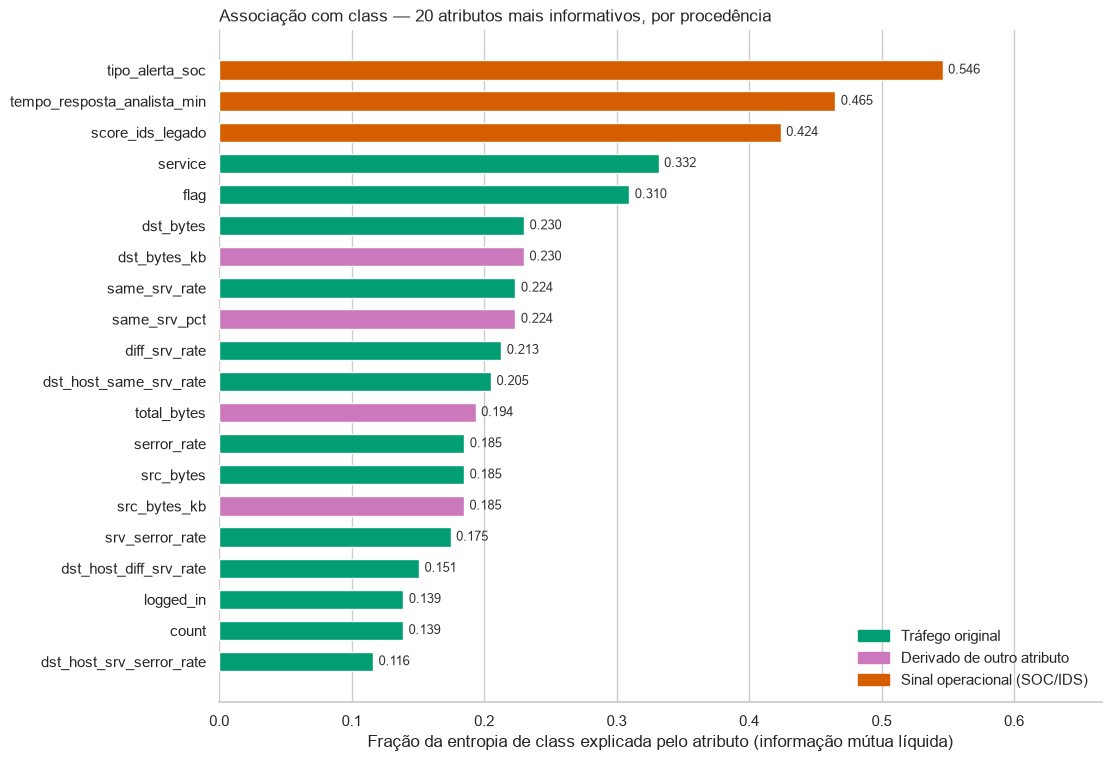

Posição de cada sinal operacional no ranking dos 49 atributos:
  score_ids_legado               3º lugar (mi_liquida = 0.4238)
  tipo_alerta_soc                1º lugar (mi_liquida = 0.5460)
  tempo_resposta_analista_min    2º lugar (mi_liquida = 0.4650)

Melhor atributo de tráfego: service (4º lugar, mi_liquida = 0.3317).


In [35]:
# 5.4 (continuação) Figura 1: os 20 atributos de maior associação, identificados pela procedência.
# As cores identificam a ORIGEM do atributo, não o seu valor: é o que torna visível o fato de que
# os três primeiros lugares não são medições de tráfego. Os dois tons reservados às classes
# (Seção 2.2) não são reutilizados aqui, para que azul/laranja continuem significando
# normal/anomaly em todo o notebook.
CORES_GRUPO_M5 = {
    "Tráfego original": "#029E73",            # verde
    "Derivado de outro atributo": "#CC78BC",  # rosa
    "Sinal operacional (SOC/IDS)": "#D55E00",  # vermelhão: o grupo sob suspeita
}
N_TOPO_M5 = 20
topo_m5 = assoc_geral_m5.head(N_TOPO_M5).iloc[::-1]  # invertido: maior no topo do gráfico

fig, eixo = plt.subplots(figsize=(11, 7.5), layout="constrained")
posicoes = np.arange(len(topo_m5))
eixo.barh(posicoes, topo_m5["mi_liquida"], height=0.62,
          color=[CORES_GRUPO_M5[g] for g in topo_m5["grupo"]])
eixo.set_yticks(posicoes, topo_m5.index)
eixo.set_xlim(0, topo_m5["mi_liquida"].max() * 1.22)
eixo.set_xlabel("Fração da entropia de class explicada pelo atributo (informação mútua líquida)")
eixo.set_title(f"Associação com class — {N_TOPO_M5} atributos mais informativos, por procedência",
               loc="left")
eixo.grid(axis="y", visible=False)
eixo.set_axisbelow(True)
for lado in ("top", "right", "left"):
    eixo.spines[lado].set_visible(False)
# Rótulo direto em cada barra: a leitura não depende de medir a barra contra o eixo.
for posicao, valor in zip(posicoes, topo_m5["mi_liquida"]):
    eixo.annotate(f"{valor:.3f}", (valor, posicao), xytext=(4, 0),
                  textcoords="offset points", va="center", fontsize=9, color="#333333")
# Legenda sempre presente: a identidade do grupo nunca depende só da cor.
eixo.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cor, label=grupo)
                     for grupo, cor in CORES_GRUPO_M5.items()],
            loc="lower right", frameon=False, title=None)
plt.show()

print("Posição de cada sinal operacional no ranking dos 49 atributos:")
for sinal in COLS_OPERACIONAIS_M4:
    print(f"  {sinal:<30} {assoc_geral_m5.index.get_loc(sinal) + 1}º lugar "
          f"(mi_liquida = {assoc_geral_m5.loc[sinal, 'mi_liquida']:.4f})")
melhor_trafego_m5 = assoc_geral_m5[assoc_geral_m5["grupo"] == "Tráfego original"].index[0]
print(f"\nMelhor atributo de tráfego: {melhor_trafego_m5} "
      f"({assoc_geral_m5.index.get_loc(melhor_trafego_m5) + 1}º lugar, "
      f"mi_liquida = {assoc_geral_m5.loc[melhor_trafego_m5, 'mi_liquida']:.4f}).")

,grupo,normal,anomaly,diferenca_pp,mi_ausencia,mi_liquida
tempo_resposta_analista_min,Sinal operacional (SOC/IDS),95.5744,23.5352,-72.0392,0.4109,0.4650
dst_host_serror_rate,Tráfego original,29.7533,44.8394,15.0861,0.0124,0.0711
dst_host_same_src_port_rate,Tráfego original,28.0759,26.5261,-1.5497,0.0001,0.0554
num_file_creations,Tráfego original,5.3153,5.9573,0.6421,0.0001,0.0001
count,Tráfego original,5.3670,4.7806,-0.5864,0.0001,0.1388
dst_host_srv_rerror_rate,Tráfego original,4.7541,4.2167,-0.5374,0.0001,0.0237
dst_host_diff_srv_rate,Tráfego original,3.4751,3.0645,-0.4106,0.0001,0.1508
total_bytes,Derivado de outro atributo,40.0234,38.9556,-1.0678,0.0001,0.1936
src_bytes,Tráfego original,40.0234,38.9556,-1.0678,0.0001,0.1849
src_bytes_kb,Derivado de outro atributo,40.0234,38.9556,-1.0678,0.0001,0.1847


Colunas cuja AUSÊNCIA sozinha explica >= 1% da entropia do alvo: ['tempo_resposta_analista_min', 'dst_host_serror_rate']
Nas outras 26 colunas com ausentes, a informação mútua do indicador
de ausência não passa de 0.0001: a ausência é praticamente não informativa
e compatível com perda aleatória. Em flag, por exemplo, os 4.093 ausentes têm 5,99% de
anomaly contra 5.84% da base (Seção 5.3) — indistinguível do acaso.


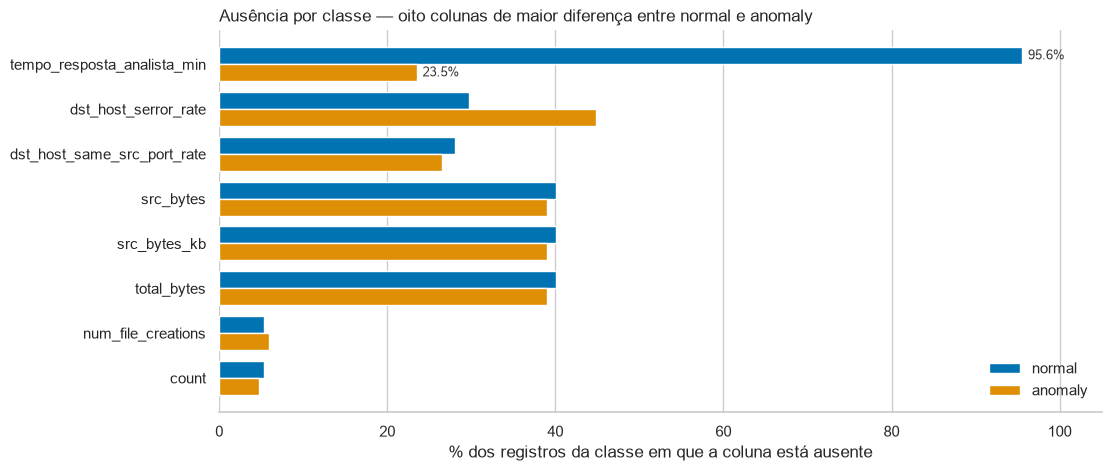

In [36]:
# 5.4 (continuação) Onde o sinal está na AUSÊNCIA e não no valor.
# Reaproveita pct_aus_classe (Seção 1.4) e cruza com a informação mútua do indicador de ausência.
ausencia_m5 = pct_aus_classe.join(assoc_geral_m5[["grupo", "mi_ausencia", "mi_liquida"]])
ausencia_m5 = ausencia_m5.sort_values("mi_ausencia", ascending=False)
display(ausencia_m5[["grupo", "normal", "anomaly", "diferenca_pp", "mi_ausencia", "mi_liquida"]].head(10))

informativas_m5 = ausencia_m5.index[ausencia_m5["mi_ausencia"] >= 0.01].tolist()
nao_informativas_m5 = [c for c in cols_com_ausentes if c not in informativas_m5]
teto_ausencia_m5 = ausencia_m5.loc[nao_informativas_m5, "mi_ausencia"].max()
print(f"Colunas cuja AUSÊNCIA sozinha explica >= 1% da entropia do alvo: {informativas_m5}")
print(f"Nas outras {len(nao_informativas_m5)} colunas com ausentes, a informação mútua do indicador")
print(f"de ausência não passa de {teto_ausencia_m5:.4f}: a ausência é praticamente não informativa")
print("e compatível com perda aleatória. Em flag, por exemplo, os 4.093 ausentes têm 5,99% de")
print(f"anomaly contra {100 * PREVALENCIA_M5:.2f}% da base (Seção 5.3) — indistinguível do acaso.")

# Figura 2: as oito colunas de maior diferença de ausência entre as classes.
topo_aus_m5 = (pct_aus_classe.reindex(pct_aus_classe["diferenca_pp"].abs()
               .sort_values(ascending=False).index).head(8).iloc[::-1])
fig, eixo = plt.subplots(figsize=(11, 4.6), layout="constrained")
posicoes = np.arange(len(topo_aus_m5))
altura = 0.38
for deslocamento, classe in zip((altura / 2, -altura / 2), CLASSES):
    eixo.barh(posicoes + deslocamento, topo_aus_m5[classe], height=altura,
              color=cores_classes[classe], label=classe)
eixo.set_yticks(posicoes, topo_aus_m5.index)
eixo.set_xlabel("% dos registros da classe em que a coluna está ausente")
eixo.set_title("Ausência por classe — oito colunas de maior diferença entre normal e anomaly",
               loc="left")
eixo.set_xlim(0, 105)
eixo.grid(axis="y", visible=False)
eixo.set_axisbelow(True)
for lado in ("top", "right", "left"):
    eixo.spines[lado].set_visible(False)
# Rótulo direto só na coluna que carrega a conclusão; o resto fica na tabela acima.
for classe, deslocamento in zip(CLASSES, (altura / 2, -altura / 2)):
    valor = topo_aus_m5.loc["tempo_resposta_analista_min", classe]
    eixo.annotate(f"{valor:.1f}%", (valor, len(topo_aus_m5) - 1 + deslocamento),
                  xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color="#333333")
eixo.legend(frameon=False, loc="lower right")
plt.show()

### 5.5 Investigação separada de `difficulty_level`

`difficulty_level` é a 43ª coluna dos arquivos originais do NSL-KDD (`KDDTrain+` / `KDDTest+`).
Ela **não descreve a conexão**: é um metadado de construção da base, igual ao número de
classificadores, entre os 21 avaliados pelos autores do NSL-KDD, que acertaram aquele registro.
Como esse número só pode ser calculado **depois de conhecer o rótulo verdadeiro**, usá-la como
preditor é vazamento por definição — não por correlação alta, mas por origem. Por isso ela merece
verificação própria, separada da análise de associação das Seções 5.2 a 5.4, e por isso ela é
verificada mesmo quando se espera que não exista.

A verificação abaixo responde a três perguntas, nesta ordem: a coluna existe com esse nome? existe
com algum nome equivalente? existe alguma coluna com o seu perfil estrutural (inteiro em [0, 21],
sem relação com tráfego)? O resultado é registrado em `STATUS_DIFFICULTY_M5` para constar do
diagnóstico final.

In [37]:
# 5.5 Verificação explícita de difficulty_level na base oficial deste trabalho.

def chave_coluna(nome: str) -> str:
    """Nome reduzido a letras e dígitos, sem acento e sem caixa, para comparar variantes."""
    sem_acento = unicodedata.normalize("NFKD", str(nome)).encode("ascii", "ignore").decode()
    return "".join(c for c in sem_acento.lower() if c.isalnum())

# (a) Nome exato.
tem_exato_m5 = "difficulty_level" in df_train.columns

# (b) Variantes de grafia e traduções plausíveis.
VARIANTES_DIFFICULTY_M5 = ["difficulty_level", "difficulty", "dificuldade", "nivel_dificuldade",
                           "level", "nivel", "score_dificuldade"]
variantes_achadas_m5 = {v: [c for c in df_train.columns if chave_coluna(v) in chave_coluna(c)]
                        for v in VARIANTES_DIFFICULTY_M5}
variantes_achadas_m5 = {v: achados for v, achados in variantes_achadas_m5.items() if achados}

# (c) Perfil estrutural: inteiro, sem ausentes, com domínio contido em [0, 21] e no máximo 22
#     valores distintos — a assinatura do difficulty_level do NSL-KDD.
perfil_difficulty_m5 = []
for coluna in COLS_NUMERICAS:
    observado = df_train[coluna].dropna()
    if observado.empty:
        continue
    if (observado.between(0, 21).all() and observado.nunique() <= 22
            and bool((observado == observado.round()).all())):
        perfil_difficulty_m5.append(coluna)

print(f"(a) Coluna 'difficulty_level' presente em treino.csv: {tem_exato_m5}")
print(f"(b) Colunas com nome equivalente a alguma variante: "
      f"{variantes_achadas_m5 if variantes_achadas_m5 else 'nenhuma'}")
print(f"(c) Colunas com o perfil estrutural de difficulty_level (inteiro em [0, 21], <= 22 "
      f"valores): {len(perfil_difficulty_m5)}")
display(pd.DataFrame({
    "tipo_semantico": mapa_tipos.loc[perfil_difficulty_m5, "tipo_semantico"],
    "n_valores_distintos": df_train[perfil_difficulty_m5].nunique(),
    "valores_observados": [sorted(df_train[c].dropna().unique().tolist())[:5] for c in perfil_difficulty_m5],
    "mi_liquida": assoc_geral_m5.loc[perfil_difficulty_m5, "mi_liquida"],
}))
print("Todas as colunas do item (c) são binários ou contagens de tráfego já documentados pelo"
      "\nMembro 1 (land, logged_in, num_shells, protocolo_cod, ...). Nenhuma delas é um metadado"
      "\nde dificuldade: todas têm significado de rede e nenhuma usa 0..21 como escala de nível.")

(a) Coluna 'difficulty_level' presente em treino.csv: False
(b) Colunas com nome equivalente a alguma variante: nenhuma
(c) Colunas com o perfil estrutural de difficulty_level (inteiro em [0, 21], <= 22 valores): 13


,tipo_semantico,n_valores_distintos,valores_observados,mi_liquida
land,binário (0/1),2,"[0, 1]",-0.0000
wrong_fragment,inteiro – contagem/magnitude,3,"[0, 1, 3]",0.0048
urgent,inteiro – contagem/magnitude,4,"[0, 1, 2, 3]",0.0000
num_failed_logins,inteiro – contagem/magnitude,5,"[0, 1, 2, 3, 4]",0.0011
num_shells,inteiro – contagem/magnitude,3,"[0, 1, 2]",0.0001
num_outbound_cmds,constante,1,[0],0.0000
is_host_login,binário (0/1),2,"[0, 1]",-0.0000
is_guest_login,binário (0/1),2,"[0, 1]",-0.0000
protocolo_cod,categórico codificado (inteiro),3,"[0, 1, 2]",0.0314
logged_in,binário (0/1),2,"[0.0, 1.0]",0.1390


Todas as colunas do item (c) são binários ou contagens de tráfego já documentados pelo
Membro 1 (land, logged_in, num_shells, protocolo_cod, ...). Nenhuma delas é um metadado
de dificuldade: todas têm significado de rede e nenhuma usa 0..21 como escala de nível.


In [38]:
# 5.5 (continuação) Registro formal do resultado, para o diagnóstico final.
STATUS_DIFFICULTY_M5 = {
    "coluna_presente": tem_exato_m5,
    "variantes_de_nome_encontradas": bool(variantes_achadas_m5),
    "colunas_com_perfil_estrutural": len(perfil_difficulty_m5),
    "conclusao": ("AUSENTE — difficulty_level não existe nesta base e nada precisa ser removido "
                  "por esse motivo"),
    "acao_necessaria": "nenhuma remoção; o risco análogo foi transferido para a Seção 5.6",
}
assert not tem_exato_m5 and not variantes_achadas_m5, (
    "difficulty_level (ou variante) apareceu na base: refazer a Seção 5.5 e tratá-la como vazamento.")
display(pd.Series(STATUS_DIFFICULTY_M5, name="difficulty_level").to_frame())

print("Conclusão da verificação separada:")
print(f"  treino.csv tem {df_train.shape[1]} colunas (49 atributos + class), e não as 43 do")
print("  KDDTrain+ original. A base deste trabalho não é o NSL-KDD bruto: ela perdeu")
print("  difficulty_level e o rótulo multiclasse de ataque, e ganhou 5 atributos derivados")
print("  e 3 sinais operacionais. Procurar difficulty_level aqui é, portanto, uma conferência")
print("  negativa — e o papel metodológico que ela desempenhava (coluna que só existe depois")
print("  de o rótulo ser conhecido) passou a ser desempenhado pelos candidatos da Seção 5.6,")
print("  que é onde a investigação de vazamento efetivamente acontece nesta base.")

,difficulty_level
coluna_presente,False
variantes_de_nome_encontradas,False
colunas_com_perfil_estrutural,13
conclusao,AUSENTE — difficulty_level não existe nesta ba...
acao_necessaria,nenhuma remoção; o risco análogo foi transferi...


Conclusão da verificação separada:
  treino.csv tem 50 colunas (49 atributos + class), e não as 43 do
  KDDTrain+ original. A base deste trabalho não é o NSL-KDD bruto: ela perdeu
  difficulty_level e o rótulo multiclasse de ataque, e ganhou 5 atributos derivados
  e 3 sinais operacionais. Procurar difficulty_level aqui é, portanto, uma conferência
  negativa — e o papel metodológico que ela desempenhava (coluna que só existe depois
  de o rótulo ser conhecido) passou a ser desempenhado pelos candidatos da Seção 5.6,
  que é onde a investigação de vazamento efetivamente acontece nesta base.


### 5.6 Os três sinais operacionais: origem, disponibilidade e vazamento

As Seções 5.2 a 5.4 mostraram que `tipo_alerta_soc`, `tempo_resposta_analista_min` e
`score_ids_legado` ocupam, nessa ordem, os três primeiros lugares do ranking de associação, à
frente dos 41 atributos de tráfego. **Isso não prova vazamento.** Um atributo pode ser muito
informativo e perfeitamente legítimo. O que decide é outra pergunta:

> No instante em que o modelo precisa classificar uma conexão nova, esse valor **já existe**, e
> existe por um motivo independente do rótulo que queremos prever?

Um atributo cujo valor só passa a existir *porque* alguém já decidiu que o evento era um incidente
é um atributo posterior ao rótulo. Ele funciona no treino, infla qualquer validação interna e
desaparece — ou vira ruído — quando o modelo encontra tráfego que ainda não passou pela triagem.

Esta seção reúne quatro evidências sobre os três campos: (a) o que cada um mede e quando passa a
existir; (b) como se distribuem por classe; (c) quanto um único campo, sozinho, já resolve do
problema; e (d) se os três se comportam como medições independentes ou como estágios de um mesmo
fluxo de triagem.

In [39]:
# 5.6 (a) Caracterização dos três campos: o que são, quanto existem e como se distribuem.
alerta_m5 = df_train["tipo_alerta_soc"].str.strip().str.lower()
tem_tempo_m5 = df_train["tempo_resposta_analista_min"].notna()
score_m5 = df_train["score_ids_legado"]

perfil_oper_m5 = pd.DataFrame({
    "leitura_do_nome": ["Pontuação de um IDS legado (sistema de detecção anterior)",
                        "Tipo do alerta gerado pelo SOC (centro de operações de segurança)",
                        "Tempo de resposta do analista, em minutos"],
    "tipo": [mapa_tipos.loc[c, "tipo_semantico"] for c in COLS_OPERACIONAIS_M4],
    "pct_ausentes": [100 * df_train[c].isna().mean() for c in COLS_OPERACIONAIS_M4],
    "n_valores_distintos": [df_train[c].nunique() for c in COLS_OPERACIONAIS_M4],
    "amplitude": ["[0,000; 1,000], múltiplos de 0,001",
                  "2 categorias: 'ok' e 'alerta'",
                  f"[{df_train['tempo_resposta_analista_min'].min():.1f}; "
                  f"{df_train['tempo_resposta_analista_min'].max():.1f}] minutos"],
    "posicao_no_ranking": [assoc_geral_m5.index.get_loc(c) + 1 for c in COLS_OPERACIONAIS_M4],
}, index=COLS_OPERACIONAIS_M4)
display(perfil_oper_m5)

print("Distribuição de score_ids_legado por classe:")
display(df_train.groupby(COL_ROTULO)["score_ids_legado"]
        .describe()[["count", "mean", "std", "25%", "50%", "75%"]].reindex(CLASSES))
print("\nTaxa de anomaly por categoria de tipo_alerta_soc:")
display(taxa_por_categoria("tipo_alerta_soc"))
print("\nPresença de tempo_resposta_analista_min x classe:")
tabela_tempo_m5 = pd.crosstab(tem_tempo_m5.map({True: "preenchido", False: "ausente"})
                              .rename("tempo_resposta_analista_min"), df_train[COL_ROTULO])
tabela_tempo_m5["n"] = tabela_tempo_m5.sum(axis=1)
tabela_tempo_m5["pct_anomaly"] = 100 * tabela_tempo_m5["anomaly"] / tabela_tempo_m5["n"]
display(tabela_tempo_m5)
print("Entre os registros com tempo de resposta preenchido, a taxa de anomaly é de "
      f"{tabela_tempo_m5.loc['preenchido', 'pct_anomaly']:.2f}% contra "
      f"{tabela_tempo_m5.loc['ausente', 'pct_anomaly']:.2f}% entre os ausentes — uma razão de "
      f"{tabela_tempo_m5.loc['preenchido', 'pct_anomaly'] / tabela_tempo_m5.loc['ausente', 'pct_anomaly']:.1f}x "
      "obtida sem olhar um único valor do campo.")

,leitura_do_nome,tipo,pct_ausentes,n_valores_distintos,amplitude,posicao_no_ranking
score_ids_legado,Pontuação de um IDS legado (sistema de detecçã...,"real – taxa em [0, 1]",0.0000,920,"[0,000; 1,000], múltiplos de 0,001",3
tipo_alerta_soc,Tipo do alerta gerado pelo SOC (centro de oper...,categórico nominal,0.0000,2,2 categorias: 'ok' e 'alerta',1
tempo_resposta_analista_min,"Tempo de resposta do analista, em minutos",real,91.3665,1289,[1.0; 432.5] minutos,2


Distribuição de score_ids_legado por classe:


,count,mean,std,25%,50%,75%
class,,,,,,
normal,"65,754.0000",0.1580,0.1742,0.0570,0.1260,0.1990
anomaly,"4,079.0000",0.7069,0.2998,0.6730,0.8180,0.9040



Taxa de anomaly por categoria de tipo_alerta_soc:


class,anomaly,normal,n,pct_anomaly,razao_vs_base
tipo_alerta_soc,,,,,
alerta,3379,1657,5036,67.0969,11.4871
ok,700,64097,64797,1.0803,0.1849



Presença de tempo_resposta_analista_min x classe:


class,anomaly,normal,n,pct_anomaly
tempo_resposta_analista_min,,,,
ausente,960,62844,63804,1.5046
preenchido,3119,2910,6029,51.7333


Entre os registros com tempo de resposta preenchido, a taxa de anomaly é de 51.73% contra 1.50% entre os ausentes — uma razão de 34.4x obtida sem olhar um único valor do campo.


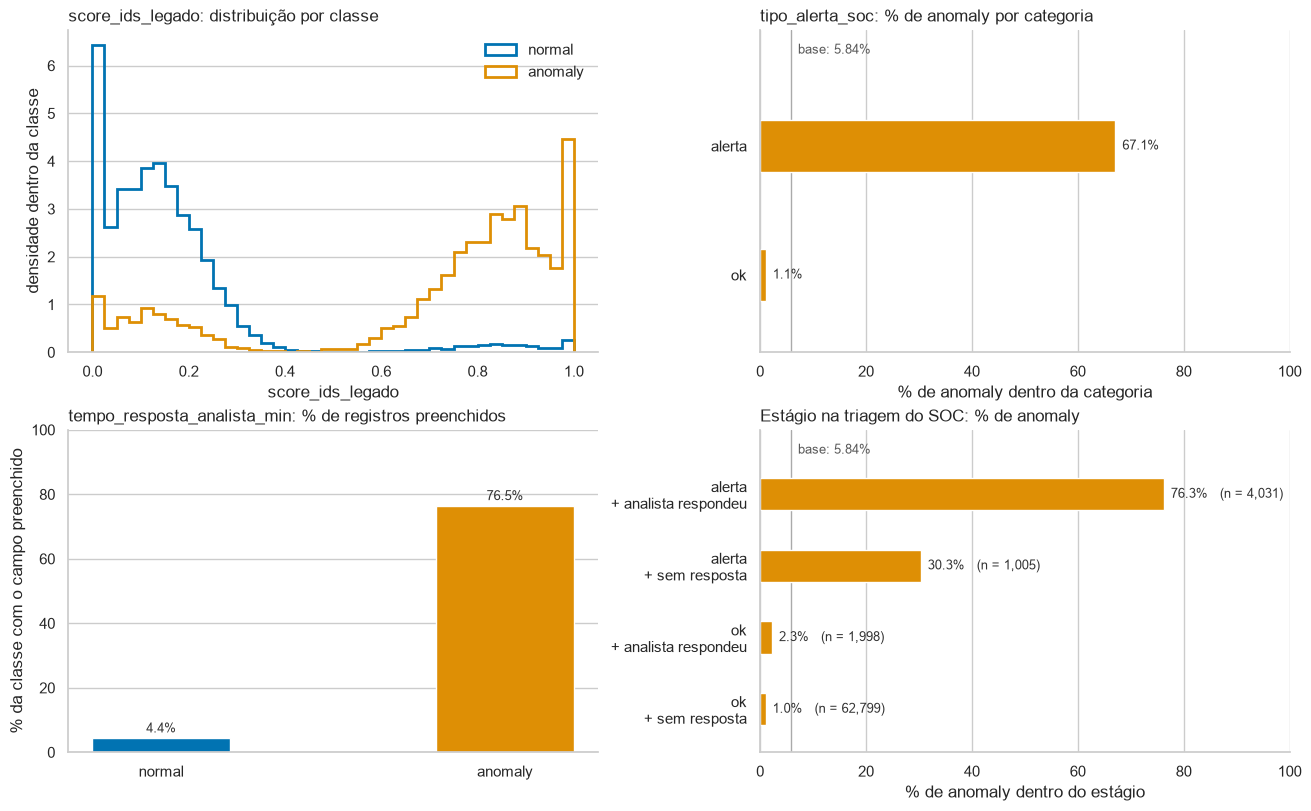

class,anomaly,normal,n,pct_anomaly
estagio,,,,
ok\n+ sem resposta,655,62144,62799,1.0430
ok\n+ analista respondeu,45,1953,1998,2.2523
alerta\n+ sem resposta,305,700,1005,30.3483
alerta\n+ analista respondeu,3074,957,4031,76.2590


In [40]:
# 5.6 (b) Figura 3: os três sinais vistos por classe, mais o estágio de triagem que eles formam.
# Toda a figura usa apenas as duas cores de classe já definidas na Seção 2.2: onde a barra mede
# "% de anomaly", ela recebe a cor de anomaly; a linha cinza é sempre a prevalência da base.
from matplotlib.transforms import blended_transform_factory

COR_REFERENCIA_M5 = "#AAAAAA"
estagio_m5 = pd.Series(
    np.where(alerta_m5.eq("alerta"), "alerta", "ok")
    + np.where(tem_tempo_m5, "\n+ analista respondeu", "\n+ sem resposta"), name="estagio")
funil_m5 = pd.crosstab(estagio_m5, df_train[COL_ROTULO])
funil_m5["n"] = funil_m5.sum(axis=1)
funil_m5["pct_anomaly"] = 100 * funil_m5["anomaly"] / funil_m5["n"]
funil_m5 = funil_m5.sort_values("pct_anomaly")


def linha_de_base(eixo):
    """Marca a prevalência de anomaly da base, atrás das barras, com rótulo no topo do painel."""
    eixo.axvline(100 * PREVALENCIA_M5, color=COR_REFERENCIA_M5, linewidth=1.0, zorder=0)
    eixo.annotate(f"base: {100 * PREVALENCIA_M5:.2f}%", xy=(100 * PREVALENCIA_M5, 1.0),
                  xycoords=blended_transform_factory(eixo.transData, eixo.transAxes),
                  xytext=(5, -10), textcoords="offset points", fontsize=9,
                  color="#595959", va="top")


def folga_no_topo(eixo, n_barras):
    """Abre espaço acima da barra mais alta para o rótulo da linha de base não cobri-la."""
    eixo.set_ylim(-0.6, n_barras - 1 + 0.9)


def rotular_barras_h(eixo, valores, sufixos=None):
    """Rótulo direto no fim de cada barra horizontal."""
    for posicao, valor in enumerate(valores):
        texto = f"{valor:.1f}%" + ("" if sufixos is None else sufixos[posicao])
        eixo.annotate(texto, (valor, posicao), xytext=(5, 0), textcoords="offset points",
                      va="center", fontsize=9, color="#333333")


fig, eixos = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")

# (a) score_ids_legado: densidade por classe, para comparar formas e não volumes.
faixas = np.linspace(0, 1, 41)
for classe in CLASSES:
    eixos[0, 0].hist(df_train.loc[df_train[COL_ROTULO] == classe, "score_ids_legado"],
                     bins=faixas, density=True, histtype="step", linewidth=2,
                     color=cores_classes[classe], label=classe)
eixos[0, 0].set_title("score_ids_legado: distribuição por classe", loc="left")
eixos[0, 0].set_xlabel("score_ids_legado")
eixos[0, 0].set_ylabel("densidade dentro da classe")
eixos[0, 0].legend(frameon=False)

# (b) tipo_alerta_soc: taxa de anomaly por categoria, contra a prevalência da base.
taxa_alerta_m5 = taxa_por_categoria("tipo_alerta_soc").sort_values("pct_anomaly")
eixos[0, 1].barh(np.arange(len(taxa_alerta_m5)), taxa_alerta_m5["pct_anomaly"],
                 height=0.4, color=cores_classes["anomaly"])
eixos[0, 1].set_yticks(np.arange(len(taxa_alerta_m5)), taxa_alerta_m5.index)
eixos[0, 1].set_xlim(0, 100)
eixos[0, 1].set_title("tipo_alerta_soc: % de anomaly por categoria", loc="left")
eixos[0, 1].set_xlabel("% de anomaly dentro da categoria")
folga_no_topo(eixos[0, 1], len(taxa_alerta_m5))
linha_de_base(eixos[0, 1])
rotular_barras_h(eixos[0, 1], taxa_alerta_m5["pct_anomaly"])

# (c) tempo_resposta_analista_min: o campo existe ou não, por classe.
pct_preenchido_m5 = (100 * tem_tempo_m5.groupby(df_train[COL_ROTULO]).mean()).reindex(CLASSES)
eixos[1, 0].bar(np.arange(len(CLASSES)), pct_preenchido_m5, width=0.4,
                color=[cores_classes[c] for c in CLASSES])
eixos[1, 0].set_xticks(np.arange(len(CLASSES)), CLASSES)
eixos[1, 0].set_ylim(0, 100)
eixos[1, 0].set_title("tempo_resposta_analista_min: % de registros preenchidos", loc="left")
eixos[1, 0].set_ylabel("% da classe com o campo preenchido")
for posicao, valor in enumerate(pct_preenchido_m5):
    eixos[1, 0].annotate(f"{valor:.1f}%", (posicao, valor), xytext=(0, 4),
                         textcoords="offset points", ha="center", fontsize=9, color="#333333")

# (d) Os três campos lidos juntos: a taxa de anomaly cresce com o avanço na triagem.
eixos[1, 1].barh(np.arange(len(funil_m5)), funil_m5["pct_anomaly"], height=0.45,
                 color=cores_classes["anomaly"])
eixos[1, 1].set_yticks(np.arange(len(funil_m5)), funil_m5.index)
eixos[1, 1].set_xlim(0, 100)
eixos[1, 1].set_title("Estágio na triagem do SOC: % de anomaly", loc="left")
eixos[1, 1].set_xlabel("% de anomaly dentro do estágio")
folga_no_topo(eixos[1, 1], len(funil_m5))
linha_de_base(eixos[1, 1])
rotular_barras_h(eixos[1, 1], funil_m5["pct_anomaly"],
                 [f"   (n = {n:,})" for n in funil_m5["n"]])

for eixo in eixos.ravel():
    eixo.set_axisbelow(True)
    for lado in ("top", "right"):
        eixo.spines[lado].set_visible(False)
for eixo in (eixos[0, 1], eixos[1, 1]):
    eixo.grid(axis="y", visible=False)
eixos[1, 0].grid(axis="x", visible=False)
eixos[0, 0].grid(axis="x", visible=False)
plt.show()
display(funil_m5)

#### 5.6 (c) Quanto um único campo já resolve do problema

Para dimensionar o tamanho do efeito numa escala que a equipe vai usar nas etapas seguintes,
aplicamos a **mesma regra elementar** a cada candidato: um único limiar sobre um único atributo
(`atributo >= t` prevê `anomaly`), com `t` escolhido para maximizar o F1-macro. Isso não é treinar
um classificador — é descrever a base; a Etapa 3 é que treina modelos.

**Duas limitações críticas desta medida:**

1. **É resubstituição.** O limiar é escolhido e avaliado nos mesmos 69.833 registros, portanto o
   valor é um **limite superior otimista**, não uma estimativa de desempenho futuro. Serve para
   comparar atributos entre si, nunca para prever o resultado da Etapa 3.
2. **A comparação só é justa porque a regra é idêntica para todos.** Por isso aplicamos a mesma
   varredura aos melhores atributos de tráfego: a pergunta não é "o sinal operacional é bom?",
   é "ele é mais forte do que a própria medição de rede, usando a regra mais simples possível?".

A referência de leitura é o F1-macro do classificador trivial da Seção 2.3 (0,4850).

In [41]:
# 5.6 (c) Mesma regra de limiar único aplicada aos operacionais e aos melhores atributos de tráfego.
def melhor_limiar_unico(valores: pd.Series, real: np.ndarray, n_cortes: int = 201) -> dict:
    """Varre limiares nos quantis do atributo e devolve o de maior F1-macro.

    Ausentes são sempre previstos como 'normal' (a regra não pode usar o que não existe).
    Testa as duas direções, porque em vários atributos é o valor BAIXO que indica anomaly.
    """
    observado = valores.notna().to_numpy()
    brutos = valores.to_numpy()
    if observado.sum() == 0 or valores.nunique() < 2:
        return {"f1_macro": np.nan, "limiar": np.nan, "direcao": "indefinida"}
    cortes = np.unique(np.nanquantile(brutos[observado], np.linspace(0, 1, n_cortes)))
    melhor = {"f1_macro": -1.0, "limiar": np.nan, "direcao": "indefinida"}
    for corte in cortes:
        for sentido, rotulo in ((1, ">= limiar -> anomaly"), (-1, "<= limiar -> anomaly")):
            predito = np.where(observado, sentido * brutos >= sentido * corte, False)
            escore = f1_macro_m5(predito.astype(bool), real)
            if escore > melhor["f1_macro"]:
                melhor = {"f1_macro": escore, "limiar": float(corte), "direcao": rotulo}
    return melhor


# Candidatos: os três operacionais numéricos e os cinco melhores atributos de tráfego do ranking.
melhores_trafego_m5 = (assoc_geral_m5[(assoc_geral_m5["grupo"] == "Tráfego original")
                       & assoc_geral_m5.index.isin(COLS_NUMERICAS)].head(5).index.tolist())
linhas_regra = []
for coluna in ["score_ids_legado", "tempo_resposta_analista_min"] + melhores_trafego_m5:
    linhas_regra.append({"atributo": coluna, "grupo": GRUPO_M5[coluna],
                         "regra": "limiar único", **melhor_limiar_unico(df_train[coluna], alvo_bin_m5)})

# As duas regras que não são limiares numéricos: uma categoria e a simples presença do campo.
linhas_regra.append({"atributo": "tipo_alerta_soc", "grupo": GRUPO_M5["tipo_alerta_soc"],
                     "regra": "categoria != 'ok' -> anomaly", "limiar": np.nan,
                     "direcao": "categórica",
                     "f1_macro": f1_macro_m5(alerta_m5.ne("ok").to_numpy(), alvo_bin_m5)})
linhas_regra.append({"atributo": "tempo_resposta_analista_min", "grupo": GRUPO_M5["tempo_resposta_analista_min"],
                     "regra": "campo preenchido -> anomaly", "limiar": np.nan,
                     "direcao": "só a presença, ignorando o valor",
                     "f1_macro": f1_macro_m5(tem_tempo_m5.to_numpy(), alvo_bin_m5)})

regras_m5 = (pd.DataFrame(linhas_regra)
             .set_index(["atributo", "regra"])
             .sort_values("f1_macro", ascending=False))
regras_m5["ganho_vs_trivial"] = regras_m5["f1_macro"] - f1_macro_trivial
print(f"F1-macro do classificador trivial (Seção 2.3), para referência: {f1_macro_trivial:.4f}")
display(regras_m5[["grupo", "f1_macro", "ganho_vs_trivial", "limiar", "direcao"]])

F1-macro do classificador trivial (Seção 2.3), para referência: 0.4850


,,grupo,f1_macro,ganho_vs_trivial,limiar,direcao
atributo,regra,,,,,
tipo_alerta_soc,categoria != 'ok' -> anomaly,Sinal operacional (SOC/IDS),0.8617,0.3767,NaN,categórica
tempo_resposta_analista_min,limiar único,Sinal operacional (SOC/IDS),0.8236,0.3387,13.4000,>= limiar -> anomaly
score_ids_legado,limiar único,Sinal operacional (SOC/IDS),0.8050,0.3200,0.4652,>= limiar -> anomaly
tempo_resposta_analista_min,campo preenchido -> anomaly,Sinal operacional (SOC/IDS),0.7936,0.3087,NaN,"só a presença, ignorando o valor"
same_srv_rate,limiar único,Tráfego original,0.7619,0.2770,0.1700,<= limiar -> anomaly
serror_rate,limiar único,Tráfego original,0.7369,0.2519,1.0000,>= limiar -> anomaly
diff_srv_rate,limiar único,Tráfego original,0.7209,0.2359,0.0500,>= limiar -> anomaly
dst_host_same_srv_rate,limiar único,Tráfego original,0.6799,0.1950,0.0900,<= limiar -> anomaly
dst_bytes,limiar único,Tráfego original,0.6336,0.1486,0.0000,<= limiar -> anomaly


In [42]:
# 5.6 (c, continuação) Leitura da tabela de regras.
melhor_oper_m5 = regras_m5[regras_m5["grupo"] == "Sinal operacional (SOC/IDS)"].iloc[0]
melhor_traf_m5 = regras_m5[regras_m5["grupo"] == "Tráfego original"].iloc[0]
print(f"Melhor regra entre os sinais operacionais: {melhor_oper_m5.name[0]} "
      f"({melhor_oper_m5.name[1]}) -> F1-macro {melhor_oper_m5['f1_macro']:.4f}")
print(f"Melhor regra entre os atributos de tráfego: {melhor_traf_m5.name[0]} "
      f"({melhor_traf_m5.name[1]}) -> F1-macro {melhor_traf_m5['f1_macro']:.4f}")
print(f"Diferença: {melhor_oper_m5['f1_macro'] - melhor_traf_m5['f1_macro']:+.4f}")
n_oper_acima_m5 = int((regras_m5[regras_m5["grupo"] == "Sinal operacional (SOC/IDS)"]["f1_macro"]
                       > melhor_traf_m5["f1_macro"]).sum())
print(f"\nTodas as {n_oper_acima_m5} regras construídas sobre sinais operacionais superam a melhor"
      "\nregra construída sobre tráfego. O caso mais incômodo é 'campo preenchido -> anomaly':"
      f"\n{regras_m5.loc[('tempo_resposta_analista_min', 'campo preenchido -> anomaly'), 'f1_macro']:.4f}"
      " de F1-macro SEM LER UM ÚNICO VALOR do campo — apenas verificando se ele existe."
      "\nUm atributo cuja mera existência classifica melhor do que qualquer medição de rede não"
      "\nestá medindo a rede: está registrando uma decisão já tomada sobre aquele evento.")

Melhor regra entre os sinais operacionais: tipo_alerta_soc (categoria != 'ok' -> anomaly) -> F1-macro 0.8617
Melhor regra entre os atributos de tráfego: same_srv_rate (limiar único) -> F1-macro 0.7619
Diferença: +0.0997

Todas as 4 regras construídas sobre sinais operacionais superam a melhor
regra construída sobre tráfego. O caso mais incômodo é 'campo preenchido -> anomaly':
0.7936 de F1-macro SEM LER UM ÚNICO VALOR do campo — apenas verificando se ele existe.
Um atributo cuja mera existência classifica melhor do que qualquer medição de rede não
está medindo a rede: está registrando uma decisão já tomada sobre aquele evento.


In [43]:
# 5.6 (d) Os três campos são medições independentes ou estágios do mesmo fluxo?
# Se forem saídas do mesmo processo de triagem, isso reforça a hipótese de posterioridade.

# (i) score_ids_legado x tipo_alerta_soc: um limiar no score reproduz a categoria do alerta?
concordancia_m5 = pd.DataFrame([
    {"limiar_no_score": t,
     "pct_concordancia_com_alerta": 100 * float((score_m5.ge(t) == alerta_m5.eq("alerta")).mean())}
    for t in np.round(np.arange(0.30, 0.75, 0.05), 2)]).set_index("limiar_no_score")
display(concordancia_m5)
melhor_conc_m5 = concordancia_m5["pct_concordancia_com_alerta"].max()
print(f"Um único corte em score_ids_legado reproduz tipo_alerta_soc em até "
      f"{melhor_conc_m5:.2f}% das 69.833 linhas: os dois campos são, essencialmente, a versão"
      "\ncontínua e a versão binarizada da MESMA saída do detector legado, e não duas medições"
      "\nindependentes.")

# (ii) Correlação de score_ids_legado com o tráfego e com o outro campo operacional.
corr_score_m5 = (df_train[COLS_NUMERICAS].corr(method="spearman", min_periods=100)["score_ids_legado"]
                 .drop("score_ids_legado").dropna())
corr_score_m5 = corr_score_m5.reindex(corr_score_m5.abs().sort_values(ascending=False).index)
print("\nMaiores correlações de Spearman de score_ids_legado com os demais numéricos:")
display(corr_score_m5.head(6).to_frame("spearman").join(GRUPO_M5.rename("grupo")))
print(f"O maior |rho| contra um atributo de TRÁFEGO é "
      f"{corr_score_m5[GRUPO_M5.reindex(corr_score_m5.index) == 'Tráfego original'].abs().max():.4f}:"
      "\nnão há combinação simples de atributos de rede que reconstrua o score. Ele traz informação"
      "\nde fora da captura de tráfego — informação cuja origem e disponibilidade a equipe não"
      "\nconsegue verificar com os arquivos entregues.")

# (iii) O funil: a taxa de anomaly cresce monotonicamente com o avanço na triagem.
print("\nTaxa de anomaly por estágio de triagem (mesma tabela da Figura 3d):")
display(funil_m5[["n", "pct_anomaly"]])
assert funil_m5["pct_anomaly"].is_monotonic_increasing, (
    "O funil deixou de ser monotônico; revisar a interpretação da Seção 5.6.")
progressao_m5 = " -> ".join(f"{v:.2f}%" for v in funil_m5["pct_anomaly"])
print(f"A progressão {progressao_m5} é monotônica e está ordenada exatamente pelo quanto o")
print("evento avançou na triagem do SOC. É assim que se parece um conjunto de campos")
print("posteriores ao rótulo, e não um conjunto de medições do tráfego.")

,pct_concordancia_com_alerta
limiar_no_score,
0.3000,92.9847
0.3500,95.1470
0.4000,95.8573
0.4500,96.0291
0.5000,96.0563
0.5500,96.0434
0.6000,96.0005
0.6500,95.8959
0.7000,95.7513


Um único corte em score_ids_legado reproduz tipo_alerta_soc em até 96.06% das 69.833 linhas: os dois campos são, essencialmente, a versão
contínua e a versão binarizada da MESMA saída do detector legado, e não duas medições
independentes.



Maiores correlações de Spearman de score_ids_legado com os demais numéricos:


,spearman,grupo
tempo_resposta_analista_min,0.5300,Sinal operacional (SOC/IDS)
same_srv_rate,-0.2229,Tráfego original
same_srv_pct,-0.2229,Derivado de outro atributo
serror_rate,0.2125,Tráfego original
diff_srv_rate,0.1992,Tráfego original
srv_serror_rate,0.1990,Tráfego original


O maior |rho| contra um atributo de TRÁFEGO é 0.2229:
não há combinação simples de atributos de rede que reconstrua o score. Ele traz informação
de fora da captura de tráfego — informação cuja origem e disponibilidade a equipe não
consegue verificar com os arquivos entregues.

Taxa de anomaly por estágio de triagem (mesma tabela da Figura 3d):


class,n,pct_anomaly
estagio,,
ok\n+ sem resposta,62799,1.0430
ok\n+ analista respondeu,1998,2.2523
alerta\n+ sem resposta,1005,30.3483
alerta\n+ analista respondeu,4031,76.2590


A progressão 1.04% -> 2.25% -> 30.35% -> 76.26% é monotônica e está ordenada exatamente pelo quanto o
evento avançou na triagem do SOC. É assim que se parece um conjunto de campos
posteriores ao rótulo, e não um conjunto de medições do tráfego.


#### 5.6 (e) Disponibilidade no momento da predição e veredito

Reunindo as quatro evidências, a questão que decide é a linha do tempo de cada campo. O quadro
abaixo separa o que é **medido pela captura de tráfego** do que é **produzido pela resposta ao
evento** — e é a segunda coluna, não a magnitude da correlação, que determina o veredito.

| Campo | O que registra | Quando o valor passa a existir | Evidência nos dados |
|---|---|---|---|
| `tipo_alerta_soc` | classificação do alerta pelo centro de operações | **depois** de a detecção classificar o evento: só há "alerta" porque algo já foi apontado como suspeito | 1º no ranking (MI 0,546); 67,10% de `anomaly` em `alerta` contra 1,08% em `ok`; F1-macro 0,8617 sozinho |
| `tempo_resposta_analista_min` | minutos até um analista humano responder | **depois** de o alerta ser escalado para uma pessoa: tempo de resposta não existe sem que haja a que responder | 91,37% ausente; ausente em 95,57% dos `normal` e em 23,54% dos `anomaly`; só a presença dá F1-macro 0,7936 |
| `score_ids_legado` | pontuação de um IDS anterior | indefinido com os arquivos entregues: pode ser em tempo real (legítimo) ou recalculado após o incidente (vazamento) | 3º no ranking (MI 0,424); correlação de postos máxima contra tráfego de apenas 0,22 em módulo; reproduz `tipo_alerta_soc` em 96,06% das linhas |

**Veredito, campo a campo.**

- **`tempo_resposta_analista_min` — vazamento confirmado por construção.** Tempo de resposta de
  analista é posterior à triagem por definição: o valor só existe porque alguém já tratou aquele
  evento como incidente. A evidência empírica é coerente com isso, e de forma particularmente
  clara: a informação está concentrada na **presença** do campo (MI da ausência 0,411 de um total
  de 0,465), não nos valores. **Recomendação: excluir.**
- **`tipo_alerta_soc` — vazamento operacional, mesmo mecanismo.** A categoria é a saída da triagem
  do SOC, não uma propriedade do pacote. Os 1.657 registros `alerta` rotulados `normal` são os
  falsos positivos do detector anterior — o que confirma a leitura: o campo registra o que o
  detector *decidiu*, não o que a rede *fez*. **Recomendação: excluir.**
- **`score_ids_legado` — risco alto, decisão dependente de informação que não temos.** É a saída
  de um modelo anterior; usá-lo transforma o trabalho em empilhar um classificador sobre outro
  classificador não documentado. Há dois cenários e nenhum dos arquivos entregues permite
  distinguir entre eles:
  1. *Score em tempo real*, calculado pelo IDS no instante da conexão. Nesse caso estaria
     disponível na predição e seria legítimo — mas o modelo final herdaria todos os erros do IDS
     legado e, se ele for desligado ou não cobrir o tráfego de teste, o desempenho desaba.
  2. *Score recalculado na investigação*, depois de o incidente ser conhecido. Nesse caso é
     vazamento puro, igual aos outros dois.
  Três fatos empurram para o segundo cenário: o score não é reconstruível a partir do tráfego
  (|rho| ≤ 0,22), reproduz `tipo_alerta_soc` em 96,06% das linhas e tem correlação 0,53 com o
  tempo de resposta do analista — ou seja, acompanha o fluxo de triagem, não a rede.
  **Recomendação: excluir do pipeline principal e, se a equipe quiser quantificar o impacto,
  manter um experimento separado na Etapa 2 (com e sem o campo), relatando os dois resultados.**

**O que esta seção NÃO afirma.** Não afirmamos que os três campos "estão correlacionados demais,
logo vazam": a Seção 5.4 mostra `service` e `flag` com associação alta e eles permanecem na base.
A decisão vem da origem do dado. Também não afirmamos que a presença dos campos no arquivo de
teste os tornaria legítimos: um campo pode estar preenchido no arquivo e ainda assim ser
posterior ao rótulo — é exatamente o caso de `tempo_resposta_analista_min` no treino, onde ele
está preenchido para 6.029 registros e, ainda assim, só existe depois da triagem.

**Limite desta análise.** O enunciado não documenta a origem dos três campos, e os arquivos
entregues não trazem carimbo de tempo que permita verificar a ordem dos eventos. A conclusão
sobre `tempo_resposta_analista_min` e `tipo_alerta_soc` é sustentada pelo significado dos campos
mais a estrutura observada; a de `score_ids_legado` é uma avaliação de risco, não uma prova.
**Confirmar a origem dos três campos com a professora é a ação pendente de maior valor da Etapa 1.**

### 5.7 Redundância entre atributos e relações determinísticas (revisão com o Membro 4)

O Membro 4 identificou cinco derivados que são função exata de um original e a correspondência 1:1
entre `protocolo_cod` e `protocol_type`. Esta seção confirma esses achados por um caminho
independente — correlação de postos entre todos os pares de numéricos — e verifica se a
redundância se repete entre os atributos do topo do ranking de associação.

Usamos **Spearman** e não Pearson porque vários atributos têm assimetria acima de 10 (Seção 1.5):
Pearson mediria o efeito dos extremos, não a relação. Como limitação, Spearman só detecta relações
monotônicas entre pares — `total_bytes = src_bytes + dst_bytes` não aparece com |rho| ≈ 1 contra
nenhum dos dois isoladamente, embora seja determinístico. Por isso a verificação por correlação
**complementa**, e não substitui, a reconstrução algébrica feita pelo Membro 4 na Seção 4.5.

In [44]:
# 5.7 Pares de numéricos com correlação de postos muito alta (redundância quase exata).
LIMIAR_REDUNDANCIA_M5 = 0.95
corr_postos_m5 = df_train[COLS_NUMERICAS].corr(method="spearman", min_periods=100)

pares_m5 = [{"atributo_a": a, "atributo_b": b, "spearman": corr_postos_m5.loc[a, b],
             "grupo_a": GRUPO_M5[a], "grupo_b": GRUPO_M5[b]}
            for a, b in combinations(COLS_NUMERICAS, 2)
            if pd.notna(corr_postos_m5.loc[a, b])
            and abs(corr_postos_m5.loc[a, b]) >= LIMIAR_REDUNDANCIA_M5]
pares_m5 = pd.DataFrame(pares_m5).sort_values("spearman", key=abs, ascending=False)
print(f"Pares com |Spearman| >= {LIMIAR_REDUNDANCIA_M5}: {len(pares_m5)}")
display(pares_m5)

# Confirmação cruzada: todo derivado reconstruído pelo Membro 4 deve reaparecer aqui ou ser
# justificado pela limitação do Spearman (relação não monotônica em pares).
derivados_confirmados_m5 = set(pares_m5["atributo_a"]) | set(pares_m5["atributo_b"])
print("\nDerivados do Membro 4 que a correlação de postos também aponta como redundantes:",
      sorted(set(COLS_DERIVADAS_M4) & derivados_confirmados_m5))
print("Derivados do Membro 4 que a correlação NÃO aponta:",
      sorted(set(COLS_DERIVADAS_M4) - derivados_confirmados_m5))
print("  total_bytes é soma de dois atributos e protocolo_cod é um código categórico: nenhum dos")
print("  dois é função monotônica de UM único numérico, então o Spearman por pares não os detecta.")
print("  Ambos continuam redundantes pela reconstrução algébrica da Seção 4.5 — é a limitação do")
print("  método desta seção, não uma discordância entre os dois diagnósticos.")

Pares com |Spearman| >= 0.95: 5


,atributo_a,atributo_b,spearman,grupo_a,grupo_b
0,dst_bytes,dst_bytes_kb,1.0000,Tráfego original,Derivado de outro atributo
1,src_bytes,src_bytes_kb,1.0000,Tráfego original,Derivado de outro atributo
3,same_srv_rate,same_srv_pct,1.0000,Tráfego original,Derivado de outro atributo
2,same_srv_rate,diff_srv_rate,-0.9593,Tráfego original,Tráfego original
4,diff_srv_rate,same_srv_pct,-0.9593,Tráfego original,Derivado de outro atributo



Derivados do Membro 4 que a correlação de postos também aponta como redundantes: ['dst_bytes_kb', 'same_srv_pct', 'src_bytes_kb']
Derivados do Membro 4 que a correlação NÃO aponta: ['protocolo_cod', 'total_bytes']
  total_bytes é soma de dois atributos e protocolo_cod é um código categórico: nenhum dos
  dois é função monotônica de UM único numérico, então o Spearman por pares não os detecta.
  Ambos continuam redundantes pela reconstrução algébrica da Seção 4.5 — é a limitação do
  método desta seção, não uma discordância entre os dois diagnósticos.


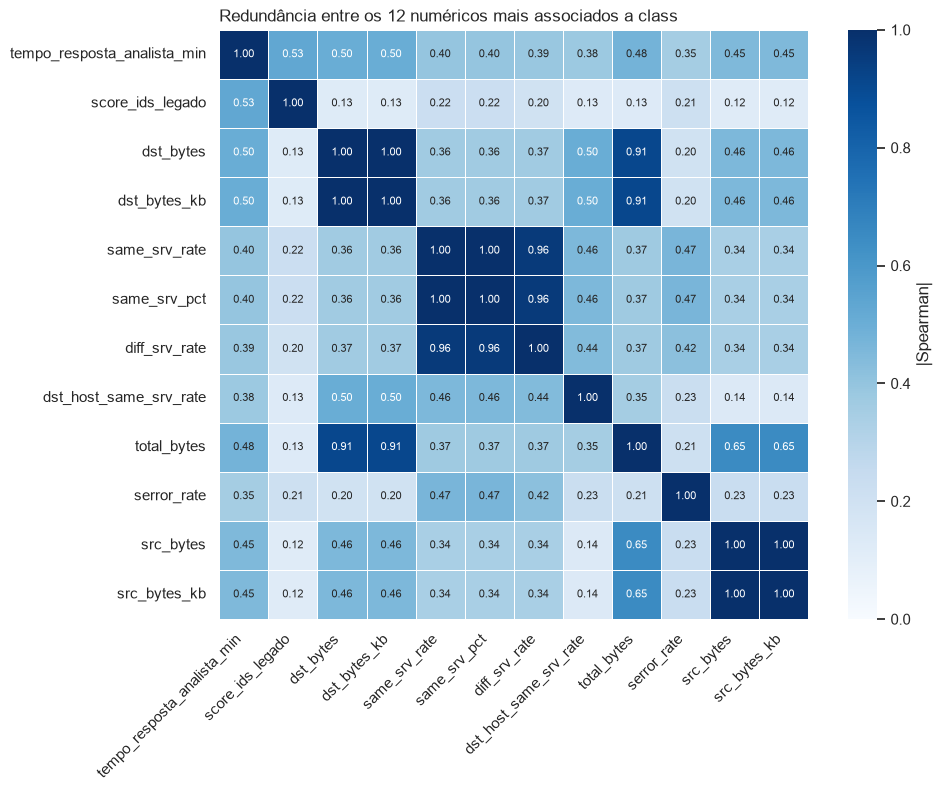

Blocos redundantes identificados dentro do topo do ranking:
  bytes de origem: ['src_bytes', 'src_bytes_kb', 'total_bytes']
  bytes de destino: ['dst_bytes', 'dst_bytes_kb']
  mesmo serviço: ['same_srv_rate', 'same_srv_pct', 'diff_srv_rate']

Consequência para a leitura da Seção 5.4: o ranking univariado conta a mesma informação
mais de uma vez — src_bytes e src_bytes_kb aparecem com mi_liquida idêntica porque são o
mesmo atributo em outra unidade. Isso NÃO muda a conclusão da Seção 5.6: os três sinais
operacionais continuam à frente mesmo depois de colapsar cada bloco redundante em um
único representante.


In [45]:
# 5.7 (continuação) Figura 4: redundância DENTRO do topo do ranking de associação.
# Importa saber se os atributos mais informativos repetem uns aos outros: se repetirem,
# o ranking univariado da Seção 5.4 está contando a mesma informação várias vezes.
topo_num_m5 = [c for c in assoc_geral_m5.index if c in COLS_NUMERICAS][:12]
matriz_m5 = corr_postos_m5.loc[topo_num_m5, topo_num_m5].abs()

fig, eixo = plt.subplots(figsize=(9.5, 7.8), layout="constrained")
# Escala sequencial de um só tom: a cor codifica magnitude, não identidade.
mapa = sns.heatmap(matriz_m5, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
                   annot_kws={"fontsize": 8}, linewidths=0.5, linecolor="white",
                   cbar_kws={"label": "|Spearman|"}, square=True, ax=eixo)
eixo.set_title("Redundância entre os 12 numéricos mais associados a class", loc="left")
eixo.set_xlabel("")
eixo.set_ylabel("")
plt.setp(eixo.get_xticklabels(), rotation=45, ha="right")
plt.show()

blocos_m5 = {
    "bytes de origem": ["src_bytes", "src_bytes_kb", "total_bytes"],
    "bytes de destino": ["dst_bytes", "dst_bytes_kb"],
    "mesmo serviço": ["same_srv_rate", "same_srv_pct", "diff_srv_rate"],
}
print("Blocos redundantes identificados dentro do topo do ranking:")
for nome, colunas in blocos_m5.items():
    presentes = [c for c in colunas if c in topo_num_m5]
    print(f"  {nome}: {presentes}")
print("\nConsequência para a leitura da Seção 5.4: o ranking univariado conta a mesma informação")
print("mais de uma vez — src_bytes e src_bytes_kb aparecem com mi_liquida idêntica porque são o")
print("mesmo atributo em outra unidade. Isso NÃO muda a conclusão da Seção 5.6: os três sinais")
print("operacionais continuam à frente mesmo depois de colapsar cada bloco redundante em um")
print("único representante.")

### 5.8 Propostas de remoção e de retenção, com justificativa técnica

A tabela abaixo é montada a partir das variáveis calculadas nas seções anteriores — nenhum número
é digitado à mão, de modo que ela não pode divergir das evidências. Cada linha traz o motivo
**técnico** da proposta e o critério que a equipe usará na Etapa 2 para confirmá-la ou derrubá-la.

Três princípios governam as decisões:

1. **Nada é removido nesta etapa.** São propostas; a remoção acontece na Etapa 2, comparada contra
   uma referência que mantém o atributo, sempre dentro das dobras de validação.
2. **Associação baixa nunca é motivo de remoção** (limitação 1 da Seção 5.1). Os 17 atributos com
   |delta de Cliff| < 0,05 permanecem.
3. **Associação alta nunca é motivo de remoção**, sozinha. `service` e `flag` têm associação alta
   e ficam. O que remove um atributo é ele ser redundante, constante ou **posterior ao rótulo**.

In [46]:
# 5.8 Tabela de propostas, montada a partir das evidências calculadas nas seções 5.2 a 5.7.
propostas_m5 = []

def registrar(alvo, proposta, motivo, evidencia, criterio):
    propostas_m5.append({"alvo": alvo, "proposta": proposta, "motivo_tecnico": motivo,
                         "evidencia_calculada": evidencia, "criterio_de_confirmacao": criterio})

# (1) Sinais operacionais: posterioridade ao rótulo.
registrar("tempo_resposta_analista_min", "REMOVER",
          "Posterior ao rótulo: tempo de resposta só existe depois de a triagem tratar o evento",
          f"{100 * df_train['tempo_resposta_analista_min'].isna().mean():.2f}% ausente; "
          f"ausência explica {assoc_geral_m5.loc['tempo_resposta_analista_min', 'mi_ausencia']:.3f} "
          f"da entropia do alvo; só a presença dá F1-macro "
          f"{regras_m5.loc[('tempo_resposta_analista_min', 'campo preenchido -> anomaly'), 'f1_macro']:.4f}",
          "Nenhum: a decisão é de origem do dado, não de desempenho")
registrar("tipo_alerta_soc", "REMOVER",
          "Posterior ao rótulo: é a saída da triagem do SOC, não uma medição da conexão",
          f"1º no ranking (MI {assoc_geral_m5.loc['tipo_alerta_soc', 'mi_liquida']:.3f}); "
          f"{taxa_alerta_m5.loc['alerta', 'pct_anomaly']:.2f}% de anomaly em 'alerta' contra "
          f"{taxa_alerta_m5.loc['ok', 'pct_anomaly']:.2f}% em 'ok'",
          "Nenhum: a decisão é de origem do dado, não de desempenho")
registrar("score_ids_legado", "REMOVER do pipeline principal, manter experimento separado",
          "Saída de um detector anterior, de disponibilidade não documentada; empilhar modelos",
          f"3º no ranking (MI {assoc_geral_m5.loc['score_ids_legado', 'mi_liquida']:.3f}); "
          f"|rho| máximo contra tráfego = "
          f"{corr_score_m5[GRUPO_M5.reindex(corr_score_m5.index) == 'Tráfego original'].abs().max():.3f}; "
          f"reproduz tipo_alerta_soc em {melhor_conc_m5:.2f}% das linhas",
          "Etapa 2: rodar com e sem o campo e relatar as duas colunas de resultado")

# (2) Constantes: sem variância, não separam nada.
for coluna in constantes_m4:
    registrar(coluna, "REMOVER", "Constante: variância zero, não distingue classes e quebra "
              "normalizações",
              f"1 valor observado em {n_treino_m4:,} registros; "
              f"mi_liquida = {assoc_geral_m5.loc[coluna, 'mi_liquida']:.4f}",
              "Reconfirmar dentro de cada dobra antes de remover")

# (3) Derivados exatos: informação duplicada. A fórmula de cada um é a verificada na Seção 4.5.
FORMULAS_M5 = {"src_bytes_kb": ("src_bytes / 1024", ["src_bytes"]),
               "dst_bytes_kb": ("dst_bytes / 1024", ["dst_bytes"]),
               "total_bytes": ("src_bytes + dst_bytes", ["src_bytes", "dst_bytes"]),
               "same_srv_pct": ("same_srv_rate * 100", ["same_srv_rate"])}
for derivado, linha in relacoes_m4.iterrows():
    formula, originais = FORMULAS_M5[derivado]
    mis = ", ".join(f"{o} {assoc_geral_m5.loc[o, 'mi_liquida']:.3f}" for o in originais)
    registrar(derivado, f"REMOVER (mantendo {' e '.join(originais)})",
              f"Reproduz exatamente {formula}: não acrescenta informação aos originais",
              f"{int(linha['n_diferentes'])} diferenças em {int(linha['ambos_presentes']):,} pares "
              f"com {linha['original']}; mi_liquida do derivado "
              f"{assoc_geral_m5.loc[derivado, 'mi_liquida']:.3f} contra {mis}",
              "Comparar na Etapa 2 contra a versão que mantém os dois")
if um_para_um_m4:
    registrar("protocolo_cod", "REMOVER (manter protocol_type)",
              "Código 1:1 de protocol_type: a mesma informação em outra representação",
              f"correspondência 1:1 confirmada; mi_liquida idêntica "
              f"({assoc_geral_m5.loc['protocolo_cod', 'mi_liquida']:.4f} contra "
              f"{assoc_geral_m5.loc['protocol_type', 'mi_liquida']:.4f})",
              "Comparar com a codificação de protocol_type escolhida na Etapa 2")

# (4) Atributos de associação alta que PERMANECEM: registrar a decisão de não remover.
for coluna in ["service", "flag"]:
    registrar(coluna, "MANTER",
              "Associação alta, mas é medição de tráfego disponível no instante da conexão",
              f"MI líquida {assoc_geral_m5.loc[coluna, 'mi_liquida']:.3f}; "
              f"V de Cramér corrigido {assoc_cat_m5.loc[coluna, 'v_cramer_corrigido']:.3f}",
              "Tratar cardinalidade e ausentes na codificação (Etapa 2), sem remover")
registrar(f"{len(fracos_m5)} atributos de |delta de Cliff| < 0,05", "MANTER",
          "Associação univariada baixa não é evidência de inutilidade (limitação 1 da Seção 5.1)",
          "inclui os quase constantes do Membro 4, em que o sinal está em dezenas de registros",
          "Decidir por seleção de atributos dentro das dobras, na Etapa 2")

propostas_m5 = pd.DataFrame(propostas_m5).set_index("alvo")
with pd.option_context("display.max_colwidth", 95):
    display(propostas_m5)
print(f"Propostas de remoção: {int((propostas_m5['proposta'].str.startswith('REMOVER')).sum())} "
      f"| Decisões explícitas de manter: {int((propostas_m5['proposta'] == 'MANTER').sum())}")

,proposta,motivo_tecnico,evidencia_calculada,criterio_de_confirmacao
alvo,,,,
tempo_resposta_analista_min,REMOVER,Posterior ao rótulo: tempo de resposta só existe depois de a triagem tratar o evento,91.37% ausente; ausência explica 0.411 da entropia do alvo; só a presença dá F1-macro 0.7936,"Nenhum: a decisão é de origem do dado, não de desempenho"
tipo_alerta_soc,REMOVER,"Posterior ao rótulo: é a saída da triagem do SOC, não uma medição da conexão",1º no ranking (MI 0.546); 67.10% de anomaly em 'alerta' contra 1.08% em 'ok',"Nenhum: a decisão é de origem do dado, não de desempenho"
score_ids_legado,"REMOVER do pipeline principal, manter experimento separado","Saída de um detector anterior, de disponibilidade não documentada; empilhar modelos",3º no ranking (MI 0.424); |rho| máximo contra tráfego = 0.223; reproduz tipo_alerta_soc em ...,Etapa 2: rodar com e sem o campo e relatar as duas colunas de resultado
num_outbound_cmds,REMOVER,"Constante: variância zero, não distingue classes e quebra normalizações","1 valor observado em 69,833 registros; mi_liquida = 0.0000",Reconfirmar dentro de cada dobra antes de remover
src_bytes_kb,REMOVER (mantendo src_bytes),Reproduz exatamente src_bytes / 1024: não acrescenta informação aos originais,"0 diferenças em 41,927 pares com src_bytes; mi_liquida do derivado 0.185 contra src_bytes 0...",Comparar na Etapa 2 contra a versão que mantém os dois
dst_bytes_kb,REMOVER (mantendo dst_bytes),Reproduz exatamente dst_bytes / 1024: não acrescenta informação aos originais,"0 diferenças em 69,833 pares com dst_bytes; mi_liquida do derivado 0.230 contra dst_bytes 0...",Comparar na Etapa 2 contra a versão que mantém os dois
total_bytes,REMOVER (mantendo src_bytes e dst_bytes),Reproduz exatamente src_bytes + dst_bytes: não acrescenta informação aos originais,"0 diferenças em 41,927 pares com src_bytes; mi_liquida do derivado 0.194 contra src_bytes 0...",Comparar na Etapa 2 contra a versão que mantém os dois
same_srv_pct,REMOVER (mantendo same_srv_rate),Reproduz exatamente same_srv_rate * 100: não acrescenta informação aos originais,"0 diferenças em 66,262 pares com same_srv_rate; mi_liquida do derivado 0.224 contra same_sr...",Comparar na Etapa 2 contra a versão que mantém os dois
protocolo_cod,REMOVER (manter protocol_type),Código 1:1 de protocol_type: a mesma informação em outra representação,correspondência 1:1 confirmada; mi_liquida idêntica (0.0314 contra 0.0314),Comparar com a codificação de protocol_type escolhida na Etapa 2


Propostas de remoção: 9 | Decisões explícitas de manter: 3


### 5.9 Auditoria de conformidade da Etapa 1

As quatro verificações abaixo são executáveis e falham com `AssertionError` se alguma regra do
enunciado tiver sido violada. Elas existem para que a conformidade seja **demonstrada**, e não
apenas afirmada na redação.

| # | Regra do enunciado | Como é verificada aqui |
|---|---|---|
| A | Todas as análises usam exclusivamente o conjunto de treino | Varredura do código-fonte deste notebook: toda leitura de arquivo é listada e comparada com a lista de arquivos vedados |
| B | O split oficial não é alterado e nenhum arquivo de dados é reescrito | Varredura por chamadas de escrita; conferência de dimensões contra o arquivo em disco |
| C | Os rótulos originais são preservados | Comparação de `df_train['class']` com a cópia feita na Seção 2.1 **e** com uma releitura do CSV |
| D | A granularidade do alvo está confirmada e registrada | Contagem de valores distintos, busca por coluna de subtipo e registro do status |

Observação sobre o método da verificação A: ela lê o arquivo `.ipynb` **salvo em disco**. Se houver
edições não salvas, salve o notebook antes de executar esta seção. Os nomes dos arquivos vedados
são montados em tempo de execução, de modo que o literal não aparece em nenhuma célula de código
e a varredura não encontra a si mesma.

In [47]:
# 5.9 (A) e (B) Varredura do código-fonte: o que este notebook lê e o que ele escreve.
import re
import json as _json

caminho_notebook_m5 = project_root / "notebooks" / "01_analise_exploratoria.ipynb"
assert caminho_notebook_m5.exists(), f"Notebook não encontrado em {caminho_notebook_m5}"
celulas_codigo_m5 = ["".join(c["source"]) for c in
                     _json.loads(caminho_notebook_m5.read_text(encoding="utf-8"))["cells"]
                     if c["cell_type"] == "code"]
fonte_m5 = "\n".join(celulas_codigo_m5)
print(f"Auditando {len(celulas_codigo_m5)} células de código de {caminho_notebook_m5.name} "
      f"({len(fonte_m5):,} caracteres).")

# Os nomes vedados são montados em tempo de execução: assim o literal não existe em nenhuma
# célula de código e a varredura não encontra a si mesma.
ARQUIVOS_VEDADOS_M5 = ["teste_sem_" + "rotulo.csv", "modelo_de_" + "submissao.csv"]
PADRAO_LEITURA_M5 = "read" + r"_csv\s*\(([^)]*)\)"
LEITURAS_M5 = re.findall(PADRAO_LEITURA_M5, fonte_m5)
ESCRITAS_M5 = re.findall(r"\.(to_csv|to_excel|to_parquet|to_pickle)\s*\(", fonte_m5)

print(f"\n(A) Chamadas de leitura de dados encontradas: {len(LEITURAS_M5)}")
for leitura in LEITURAS_M5:
    print("    argumentos: " + " ".join(leitura.split()))
citacoes_vedadas_m5 = {arquivo: fonte_m5.count(arquivo) for arquivo in ARQUIVOS_VEDADOS_M5}
print(f"    Ocorrências dos arquivos vedados em TODO o código: {citacoes_vedadas_m5}")
assert all(n == 0 for n in citacoes_vedadas_m5.values()), (
    "Alguma célula de código menciona um arquivo que a Etapa 1 não pode ler.")
assert LEITURAS_M5 and all("treino" in leitura for leitura in LEITURAS_M5), (
    "Há leitura de um arquivo que não é o treino oficial.")

print(f"\n(B) Chamadas de escrita de dados encontradas: {len(ESCRITAS_M5)} "
      f"{ESCRITAS_M5 if ESCRITAS_M5 else '(nenhuma)'}")
assert not ESCRITAS_M5, "O notebook da Etapa 1 não deve escrever arquivos de dados."

Auditando 49 células de código de 01_analise_exploratoria.ipynb (87,327 caracteres).

(A) Chamadas de leitura de dados encontradas: 2
    argumentos: project_root / "data" / "treino.csv"
    argumentos: project_root / "data" / "treino.csv", usecols=[COL_ROTULO]
    Ocorrências dos arquivos vedados em TODO o código: {'teste_sem_rotulo.csv': 0, 'modelo_de_submissao.csv': 0}

(B) Chamadas de escrita de dados encontradas: 0 (nenhuma)


In [48]:
# 5.9 (B, continuação) e (C) O split e os rótulos continuam exatamente como vieram do arquivo.
# Releitura independente do CSV: prova que nada foi alterado em memória desde a Seção 1.1.
confere_m5 = pd.read_csv(project_root / "data" / "treino.csv", usecols=[COL_ROTULO])

verificacoes_m5 = {
    "Linhas idênticas ao arquivo em disco": len(df_train) == len(confere_m5),
    "Nenhuma linha removida desde a Seção 1.1": len(df_train) == n_linhas,
    "Nenhuma coluna removida desde a Seção 1.1": df_train.shape[1] == n_colunas,
    "Ordem das linhas preservada (índice 0..n-1)":
        df_train.index.equals(pd.RangeIndex(len(df_train))),
    "Rótulos iguais à cópia da Seção 2.1": df_train[COL_ROTULO].equals(rotulos_originais),
    "Rótulos iguais aos do arquivo em disco":
        df_train[COL_ROTULO].equals(confere_m5[COL_ROTULO]),
    "Grafia original preservada (sem alterar caixa ou espaços)":
        bool((df_train[COL_ROTULO] == confere_m5[COL_ROTULO]).all()),
    "Domínio restrito a normal/anomaly": set(df_train[COL_ROTULO]) == set(CLASSES),
    "Nenhum rótulo ausente": bool(df_train[COL_ROTULO].notna().all()),
    "Frequências por classe inalteradas":
        df_train[COL_ROTULO].value_counts().reindex(CLASSES).equals(
            confere_m5[COL_ROTULO].value_counts().reindex(CLASSES)),
}
resultado_m5 = pd.Series(verificacoes_m5, name="aprovado").to_frame()
resultado_m5["situacao"] = np.where(resultado_m5["aprovado"], "OK", "FALHOU")
display(resultado_m5)
assert resultado_m5["aprovado"].all(), (
    f"Falhas de conformidade: {resultado_m5.index[~resultado_m5['aprovado']].tolist()}")
print(f"As {len(verificacoes_m5)} verificações de preservação passaram. "
      f"Os {len(df_train):,} rótulos originais estão intactos.")

,aprovado,situacao
Linhas idênticas ao arquivo em disco,True,OK
Nenhuma linha removida desde a Seção 1.1,True,OK
Nenhuma coluna removida desde a Seção 1.1,True,OK
Ordem das linhas preservada (índice 0..n-1),True,OK
Rótulos iguais à cópia da Seção 2.1,True,OK
Rótulos iguais aos do arquivo em disco,True,OK
Grafia original preservada (sem alterar caixa ou espaços),True,OK
Domínio restrito a normal/anomaly,True,OK
Nenhum rótulo ausente,True,OK
Frequências por classe inalteradas,True,OK


As 10 verificações de preservação passaram. Os 69,833 rótulos originais estão intactos.


In [49]:
# 5.9 (D) Granularidade do alvo: confirmada, com o status registrado para o relatório.
# A base antiga (NSL-KDD) trazia o nome do ataque em class e permitia agrupar em cinco famílias.
# Aqui é preciso confirmar se alguma granularidade mais fina ainda é recuperável dos arquivos.
PISTAS_SUBTIPO_M5 = ["attack", "ataque", "familia", "family", "subtipo", "subtype",
                     "categoria", "label", "rotulo", "target", "classe", "tipo_ataque"]
colunas_subtipo_m5 = [c for c in df_train.columns if c != COL_ROTULO
                      and any(chave_coluna(p) in chave_coluna(c) for p in PISTAS_SUBTIPO_M5)]
valores_alvo_m5 = sorted(df_train[COL_ROTULO].unique())

STATUS_GRANULARIDADE_M5 = {
    "valores_distintos_no_alvo": len(valores_alvo_m5),
    "valores_observados": ", ".join(valores_alvo_m5),
    "coluna_de_subtipo_de_ataque": colunas_subtipo_m5 or "nenhuma",
    "granularidade_mais_fina_recuperavel": bool(colunas_subtipo_m5),
    "confirmacao": ("CONFIRMADA — alvo binário. Os dados e o enunciado concordam: treino.csv tem "
                    "exatamente 2 valores em class e nenhuma coluna de subtipo, logo o "
                    "agrupamento em cinco famílias não se aplica e não é reconstruível"),
    "consequencia": ("Toda a Etapa 1 trata o problema como classificação binária; a métrica "
                     "oficial é o F1-macro sobre normal/anomaly (Seção 2.3)"),
    "pendencia": ("Nenhuma para a modelagem. Permanece a confirmação com a professora sobre a "
                  "origem dos sinais operacionais (Seção 5.6), que é questão distinta"),
}
assert len(valores_alvo_m5) == 2 and set(valores_alvo_m5) == set(CLASSES), (
    "O alvo deixou de ser binário: revisar toda a Etapa 1.")
assert not colunas_subtipo_m5, (
    "Apareceu uma coluna candidata a subtipo de ataque: reavaliar a granularidade do alvo.")
display(pd.Series(STATUS_GRANULARIDADE_M5, name="granularidade do alvo").to_frame())

print("Resumo da auditoria da Etapa 1:")
for item, texto in [
    ("A", "apenas data/treino.csv é lido; os arquivos de teste e de submissão não aparecem "
          "em nenhuma célula de código"),
    ("B", "nenhuma escrita de arquivo; dimensões e ordem das linhas idênticas às do CSV"),
    ("C", f"os {len(df_train):,} rótulos conferem com a cópia da Seção 2.1 e com o arquivo em disco"),
    ("D", "alvo binário confirmado e registrado em STATUS_GRANULARIDADE_M5"),
]:
    print(f"  ({item}) OK — {texto}")
print("\nTambém registrado na Seção 5.5: difficulty_level não existe nesta base "
      f"(STATUS_DIFFICULTY_M5['coluna_presente'] = {STATUS_DIFFICULTY_M5['coluna_presente']}).")

,granularidade do alvo
valores_distintos_no_alvo,2
valores_observados,"anomaly, normal"
coluna_de_subtipo_de_ataque,nenhuma
granularidade_mais_fina_recuperavel,False
confirmacao,CONFIRMADA — alvo binário. Os dados e o enunci...
consequencia,Toda a Etapa 1 trata o problema como classific...
pendencia,Nenhuma para a modelagem. Permanece a confirma...


Resumo da auditoria da Etapa 1:
  (A) OK — apenas data/treino.csv é lido; os arquivos de teste e de submissão não aparecem em nenhuma célula de código
  (B) OK — nenhuma escrita de arquivo; dimensões e ordem das linhas idênticas às do CSV
  (C) OK — os 69,833 rótulos conferem com a cópia da Seção 2.1 e com o arquivo em disco
  (D) OK — alvo binário confirmado e registrado em STATUS_GRANULARIDADE_M5

Também registrado na Seção 5.5: difficulty_level não existe nesta base (STATUS_DIFFICULTY_M5['coluna_presente'] = False).


### 5.10 Síntese do Membro 5

**Associação de todos os atributos.** Os 49 atributos foram medidos contra `class`, nenhum ficou
de fora: 45 numéricos por AUC e delta de Cliff (Seção 5.2), 4 categóricos por V de Cramér com
correção de viés (Seção 5.3) e todos os 49 num ranking único por informação mútua normalizada,
com piso por permutação e com os ausentes tratados como faixa própria (Seção 5.4). As limitações
do método estão declaradas antes dos resultados, na Seção 5.1, e três delas mudam a leitura: as
medidas são univariadas, são calculadas na base inteira (com as 11.355 duplicatas do Membro 4
dentro) e medem associação, não causalidade nem disponibilidade. Por isso **associação baixa não
removeu nenhum atributo e associação alta não removeu nenhum atributo** — `service` e `flag` estão
entre os mais informativos e permanecem.

**O que o ranking mostrou.** Os três primeiros lugares são `tipo_alerta_soc` (0,546),
`tempo_resposta_analista_min` (0,465) e `score_ids_legado` (0,424). O melhor atributo de tráfego,
`service`, aparece em 4º com 0,332. A distância não é pequena nem explicada pelo viés da medida:
o piso por permutação não passa de 0,0022 em nenhum atributo, duas ordens de grandeza abaixo.

**Vazamento.** A conclusão não vem da magnitude dessas associações — vem da linha do tempo dos
campos (Seção 5.6). `tempo_resposta_analista_min` e `tipo_alerta_soc` são posteriores ao rótulo
por construção: um tempo de resposta só existe depois que um analista respondeu, e um tipo de
alerta só existe depois que a triagem classificou o evento. A estrutura dos dados é coerente com
essa leitura em três pontos independentes: a informação de `tempo_resposta_analista_min` está na
**presença** do campo (0,411 dos 0,465) e não nos valores; `score_ids_legado` reproduz
`tipo_alerta_soc` em 96,06% das linhas e tem correlação 0,53 com o tempo de resposta, mas no
máximo 0,22 com qualquer atributo de rede; e a taxa de `anomaly` cresce monotonicamente com o
avanço no funil de triagem (1,04% → 2,25% → 30,35% → 76,26%). `score_ids_legado` é o caso de
risco alto sem prova: é saída de um detector anterior, e os arquivos entregues não permitem saber
se ela existe no instante da conexão ou só depois da investigação.

**`difficulty_level`.** Verificado separadamente, como manda o roteiro, e **ausente**: não existe
com esse nome, com nenhuma variante de grafia, nem há coluna com o seu perfil estrutural
(Seção 5.5). Nada a remover por esse motivo. O papel metodológico que ela tinha no NSL-KDD — uma
coluna que só pode ser calculada depois de conhecer o rótulo — é desempenhado nesta base pelos
sinais operacionais, e é lá que a investigação de vazamento efetivamente se concentra.

**Propostas.** Nove remoções propostas (3 sinais operacionais, 1 constante, 4 derivados exatos e
1 código redundante) e três decisões explícitas de **manter**, cada uma com motivo técnico,
evidência calculada e critério de confirmação (Seção 5.8). Nenhuma coluna foi removida nesta
etapa: todas as propostas serão comparadas contra uma referência na Etapa 2, dentro das dobras.

**Plano de validação para a Etapa 2.** Validação cruzada estratificada **apenas dentro do
treino**, com três cuidados que esta análise tornou obrigatórios:

1. **Cópias no mesmo fold.** Há 11.355 duplicatas exatas e 25.788 linhas em grupos de atributos
   idênticos. Se cópias do mesmo registro caírem em dobras diferentes, a validação mede memória e
   não generalização. Agrupar pela tupla de atributos (`GroupKFold` ou deduplicação declarada)
   antes de dividir.
2. **Todo ajuste dentro da dobra.** Imputação, codificação, normalização, balanceamento e redução
   são estimados só na parte de treino de cada dobra — inclusive as medidas de associação desta
   seção, se forem usadas para selecionar atributos.
3. **Teto realista.** Os 1.702 grupos com atributos idênticos e rótulos divergentes garantem pelo
   menos 1.702 erros para qualquer modelo que use apenas estes atributos. Nenhum resultado deve
   ser lido como se 100% fosse alcançável.

O conjunto de teste não é lido em nenhum momento e nenhuma decisão de tratamento depende dele
(auditoria da Seção 5.9).

**Pendência para a equipe.** Confirmar com a professora a origem e o momento de geração de
`score_ids_legado`, `tipo_alerta_soc` e `tempo_resposta_analista_min`. A recomendação de excluir
os três está justificada pela evidência disponível, mas é a confirmação da origem que fecha o
argumento — em especial para `score_ids_legado`, cuja exclusão é avaliação de risco e não prova.

## Diagnóstico consolidado da Etapa 1

Fechamento das cinco análises. Todos os números vêm das células acima, calculados sobre
`data/treino.csv` e apenas sobre ele.

**1. Estrutura, tipos e completude.** 69.833 registros e 50 colunas: 49 atributos e o alvo binário
`class`, sem coluna `id`. Dos 49 atributos, 41 são medições de tráfego do NSL-KDD, 5 são derivados
de outros atributos e 3 são sinais operacionais acrescentados. O tipo físico engana — 12 colunas
foram lidas como `float64` apenas por conterem ausentes, e `protocolo_cod` é um código categórico
armazenado como inteiro. Há ausentes em 28 das 50 colunas (8,38% das células), mas distribuídos de
tal forma que apenas **321 registros estão completos**: descartar linhas incompletas não é uma
opção, a imputação é obrigatória. Nenhum marcador textual disfarçado de ausência foi encontrado.
5.650 linhas têm pelo menos um valor fora do domínio esperado (taxas acima de 1, contagens acima
do máximo documentado, bytes e duração negativos).

**2. Classes e desbalanceamento.** 65.754 `normal` (94,1589%) contra 4.079 `anomaly` (5,8411%),
razão 16,12:1, sem ausentes nem variação de grafia no alvo. A proporção se mantém ao descontar as
duplicatas (15,62:1), o que mostra que a escassez é estrutural e não artefato de repetição. Um
classificador que preveja sempre `normal` obtém 94,16% de acurácia e 0,9133 de F1-weighted com
**recall zero em `anomaly`** — daí a escolha do **F1-macro** (0,4850 nesse classificador trivial)
como métrica de seleção.

**3. Categorias e cardinalidade.** Depois de padronizar espaços e caixa, `protocol_type` cai de 6
para 3 categorias, `service` de 96 para 67 e `flag` de 19 para 11: parte da cardinalidade aparente
é erro de grafia, não diversidade real. `service` tem cauda longa — os 10 serviços mais frequentes
concentram 89,51% dos registros e 51 serviços somam 2,02%. Há 4.416 ausentes em `service` e 4.093
em `flag`, que precisam de tratamento próprio: em `flag`, os ausentes têm 5,99% de `anomaly`
contra 5,84% da base, ou seja, ausência não informativa.

**4. Redundância e inconsistência.** 11.355 duplicatas exatas (16,26%) e 25.788 linhas em grupos
com atributos idênticos. 1.702 desses grupos têm rótulos divergentes, atingindo 3.730 linhas e,
o que é mais sério, **46,48% de toda a classe `anomaly`** — esses registros são indistinguíveis
entre si com os atributos disponíveis e impõem um piso de 1.702 erros a qualquer modelo.
`num_outbound_cmds` é constante; `src_bytes_kb`, `dst_bytes_kb`, `total_bytes` e `same_srv_pct`
são funções exatas de outros atributos; `protocolo_cod` tem correspondência 1:1 com
`protocol_type`. `su_attempted`, documentado como binário, tem 49 registros com valor 2 — todos
`normal`, nenhum tratamento aplicado antes de confirmar o domínio.

**5. Associação e vazamento.** Os 49 atributos foram medidos contra a classe, com método e
limitações declarados. Os três sinais operacionais ocupam os três primeiros lugares do ranking,
à frente de todas as 41 medições de tráfego, e cada um deles, sozinho, supera o melhor atributo de
rede sob a mesma regra de limiar único. A origem dos campos, e não a magnitude da associação,
sustenta a conclusão: `tempo_resposta_analista_min` e `tipo_alerta_soc` são posteriores à triagem
por construção, e `score_ids_legado` é a saída de um detector anterior cuja disponibilidade os
arquivos não documentam. Recomenda-se excluir os três, mantendo `score_ids_legado` em um
experimento separado na Etapa 2. `difficulty_level` **não existe** nesta base, verificado por nome,
por variantes e por perfil estrutural.

**Conformidade (Seção 5.9).** Auditado por código: apenas `data/treino.csv` é lido, o teste não é
aberto em nenhuma célula, nenhum arquivo é escrito, as dimensões e a ordem das linhas conferem com
o arquivo em disco e os 69.833 rótulos originais estão intactos — verificados contra a cópia da
Seção 2.1 e contra uma releitura do CSV. Granularidade do alvo **confirmada como binária** e
registrada em `STATUS_GRANULARIDADE_M5`: 2 valores distintos, nenhuma coluna de subtipo, logo o
agrupamento em cinco famílias não é aplicável nem reconstruível.

**O que entra na Etapa 2.** Imputação comparada para as 28 colunas com ausentes (obrigatória, dado
que só 321 linhas são completas); tratamento declarado para duplicatas e para os grupos
conflitantes; padronização de grafia antes de qualquer codificação; decisão de codificação para
`service`; transformação dos atributos com assimetria acima de 10; pelo menos duas técnicas de
balanceamento; e as 9 remoções propostas, cada uma comparada contra uma referência que mantém o
atributo. Tudo ajustado dentro das dobras, com cópias do mesmo registro na mesma dobra, e sem
tocar no conjunto de teste.

**Pendência única em aberto:** confirmar com a professora a origem e o momento de geração dos três
sinais operacionais (Seção 5.6).